# Ignore Warnings

In [1]:
import warnings
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings(action='ignore')

# Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import numpy as np
from sklearn.datasets import make_blobs
import colorcet as cc

# *Data* *Profiling*


**Convert The Dataset To Dataframe**

In [3]:
pd.options.display.max_columns = 30 # To Display All Columns
pd.options.display.max_rows = 1000
clean_df = pd.read_csv('Clean_Retail_Data.csv')

**First Five Rows**

In [4]:
clean_df.head()

,Transaction_ID,Customer_ID,Gender,Age_Group,Country,City,State,Income,Customer_Segment,Ratings,Order_Status,Payment_Method,Shipping_Method,Date,Month,Month_Name,Day,Day_Of_Month,Quarter,Season,Hour,Products,Product_Category,Product_Type,Price_USD,Cost_USD,Quantity
0,100001,37249,Male,Twenties,Canada,Hamilton,Ontario,High,New,5,Shipped,Debit Card,Same-Day,2023-09-18,9,September,Monday,18,Third,Autumn,22,Cycling Shorts,Clothing,Shorts,13.12,6.70,2
1,100002,26603,Female,Twenties,Germany,Bremen,Bremen,Medium,Premium,1,Processing,Cash,Same-Day,2023-03-24,3,March,Friday,24,First,Spring,10,Dress Shirt,Clothing,Shirt,79.34,35.40,2
2,100003,31878,Female,Twenties,USA,Boston,Massachusetts,Medium,Regular,4,Delivered,Cash,Standard,2023-10-04,10,October,Wednesday,4,Fourth,Autumn,22,Candles,Home_Decor,Decorations,24.50,16.90,1
3,100004,78484,Female,Twenties,Australia,Cairns,Queensland,Medium,New,4,Delivered,PayPal,Express,2023-12-28,12,December,Thursday,28,Fourth,Winter,0,Drill,Home_Decor,Tools,64.62,46.54,1
4,100005,66989,Male,Youth,Germany,Leipzig,Saxony,Medium,New,5,Delivered,Debit Card,Standard,2023-06-06,6,June,Tuesday,6,Second,Summer,17,Flavored Water,Grocery,Water,1.33,0.94,19


**Last Five Rows**

In [5]:
clean_df.tail()

,Transaction_ID,Customer_ID,Gender,Age_Group,Country,City,State,Income,Customer_Segment,Ratings,Order_Status,Payment_Method,Shipping_Method,Date,Month,Month_Name,Day,Day_Of_Month,Quarter,Season,Hour,Products,Product_Category,Product_Type,Price_USD,Cost_USD,Quantity
302005,595269,82372,Male,Forties,Canada,Edmonton,Alberta,Low,New,2,Pending,Credit Card,Express,2024-01-21,1,January,Sunday,21,First,Winter,8,Top-Freezer Refrigerator,Home_Decor,Fridge,766.14,597.50,1
302006,595270,65203,Female,Fifties,UK,Oxford,England,Low,Regular,1,Delivered,Credit Card,Express,2023-05-20,5,May,Saturday,20,Second,Spring,9,Black Refrigerator,Home_Decor,Fridge,1208.83,863.16,1
302007,595271,72342,Female,Youth,USA,Fort Worth,Texas,Medium,New,1,Shipped,Credit Card,Same-Day,2023-05-11,5,May,Thursday,11,Second,Spring,18,Stainless Steel Refrigerator,Home_Decor,Fridge,894.26,746.56,1
302008,595272,75652,Female,Forties,USA,Oakland,California,Low,New,1,Pending,Credit Card,Same-Day,2024-02-21,2,February,Wednesday,21,First,Winter,6,Side-By-Side Refrigerator,Home_Decor,Fridge,1738.24,1461.26,1
302009,595273,22366,Female,Sixties,USA,Chicago,Illinois,High,Premium,2,Shipped,Credit Card,Same-Day,2023-08-17,8,August,Thursday,17,Third,Summer,3,Stainless Steel Refrigerator,Home_Decor,Fridge,894.26,746.56,1


**Data Type Of Columns**

In [6]:
clean_df.dtypes

Transaction_ID        int64
Customer_ID           int64
Gender                  str
Age_Group               str
Country                 str
City                    str
State                   str
Income                  str
Customer_Segment        str
Ratings               int64
Order_Status            str
Payment_Method          str
Shipping_Method         str
Date                    str
Month                 int64
Month_Name              str
Day                     str
Day_Of_Month          int64
Quarter                 str
Season                  str
Hour                  int64
Products                str
Product_Category        str
Product_Type            str
Price_USD           float64
Cost_USD            float64
Quantity              int64
dtype: object

**Number Of Rows And Columns**

In [7]:
print("Number of rows is \033[1m{}\033[0m and number of columns is \033[1m{}\033[0m".format(clean_df.shape[0], clean_df.shape[1]))

Number of rows is 302010 and number of columns is 27


**Dataset Columns**

In [8]:
clean_df.columns

Index(['Transaction_ID', 'Customer_ID', 'Gender', 'Age_Group', 'Country',
       'City', 'State', 'Income', 'Customer_Segment', 'Ratings',
       'Order_Status', 'Payment_Method', 'Shipping_Method', 'Date', 'Month',
       'Month_Name', 'Day', 'Day_Of_Month', 'Quarter', 'Season', 'Hour',
       'Products', 'Product_Category', 'Product_Type', 'Price_USD', 'Cost_USD',
       'Quantity'],
      dtype='str')

**Number Of Unique Values Of Each Columns**

In [9]:
clean_df.nunique()

Transaction_ID      302010
Customer_ID          86765
Gender                   2
Age_Group                7
Country                  5
City                   130
State                   59
Income                   3
Customer_Segment         3
Ratings                  5
Order_Status             4
Payment_Method           4
Shipping_Method          3
Date                   366
Month                   12
Month_Name              12
Day                      7
Day_Of_Month            31
Quarter                  4
Season                   4
Hour                    24
Products               315
Product_Category         5
Product_Type            31
Price_USD             1481
Cost_USD              1429
Quantity                13
dtype: int64

**Find Number Of Duplicated Values**

In [10]:
clean_df.duplicated().sum()

np.int64(0)

**Find Number Of Missing Values In Each Column**

In [11]:
clean_df.isnull().sum()

Transaction_ID      0
Customer_ID         0
Gender              0
Age_Group           0
Country             0
City                0
State               0
Income              0
Customer_Segment    0
Ratings             0
Order_Status        0
Payment_Method      0
Shipping_Method     0
Date                0
Month               0
Month_Name          0
Day                 0
Day_Of_Month        0
Quarter             0
Season              0
Hour                0
Products            0
Product_Category    0
Product_Type        0
Price_USD           0
Cost_USD            0
Quantity            0
dtype: int64

**Data Statistics**

In [12]:
clean_df.describe(include=[object]).T

,count,unique,top,freq
Gender,302010,2,Female,158117
Age_Group,302010,7,Twenties,126859
Country,302010,5,USA,94901
City,302010,130,Chicago,29192
State,302010,59,England,51053
Income,302010,3,Medium,129324
Customer_Segment,302010,3,Regular,142877
Order_Status,302010,4,Delivered,130502
Payment_Method,302010,4,Credit Card,90175
Shipping_Method,302010,3,Same-Day,104250


In [13]:
clean_df.describe().map(lambda x: f"{x:0.3f}").T

,count,mean,std,min,25%,50%,75%,max
Transaction_ID,302010.000,355261.781,159006.808,100001.000,222622.250,335006.500,519770.750,595273.000
Customer_ID,302010.000,55007.865,26006.224,10000.000,32472.000,55013.000,77512.000,99999.000
Ratings,302010.000,3.162,1.321,1.000,2.000,3.000,4.000,5.000
Month,302010.000,6.505,3.452,1.000,3.000,7.000,10.000,12.000
Day_Of_Month,302010.000,15.760,8.815,1.000,8.000,16.000,23.000,31.000
Hour,302010.000,11.505,6.910,0.000,6.000,11.000,18.000,23.000
Price_USD,302010.000,273.508,555.630,0.750,11.590,36.610,249.540,5030.700
Cost_USD,302010.000,211.130,446.311,0.490,6.660,20.590,165.440,4084.150
Quantity,302010.000,2.479,2.770,1.000,1.000,1.000,3.000,19.000


# Split The Data Depending On Country

In [14]:
clean_df ['Total_Amount'] = clean_df['Price_USD'] * clean_df['Quantity']

In [15]:
usa_data = clean_df[clean_df['Country'] == 'USA'].copy()
uk_data = clean_df[clean_df['Country'] == 'UK'].copy()
canada_data = clean_df[clean_df['Country'] == 'Canada'].copy()
germany_data = clean_df[clean_df['Country'] == 'Germany'].copy()
australia_data = clean_df[clean_df['Country'] == 'Australia'].copy()

# *Exploratory* *Data* *Analysis*

**A- Univariate Analysis**

*1- Price Distribution*

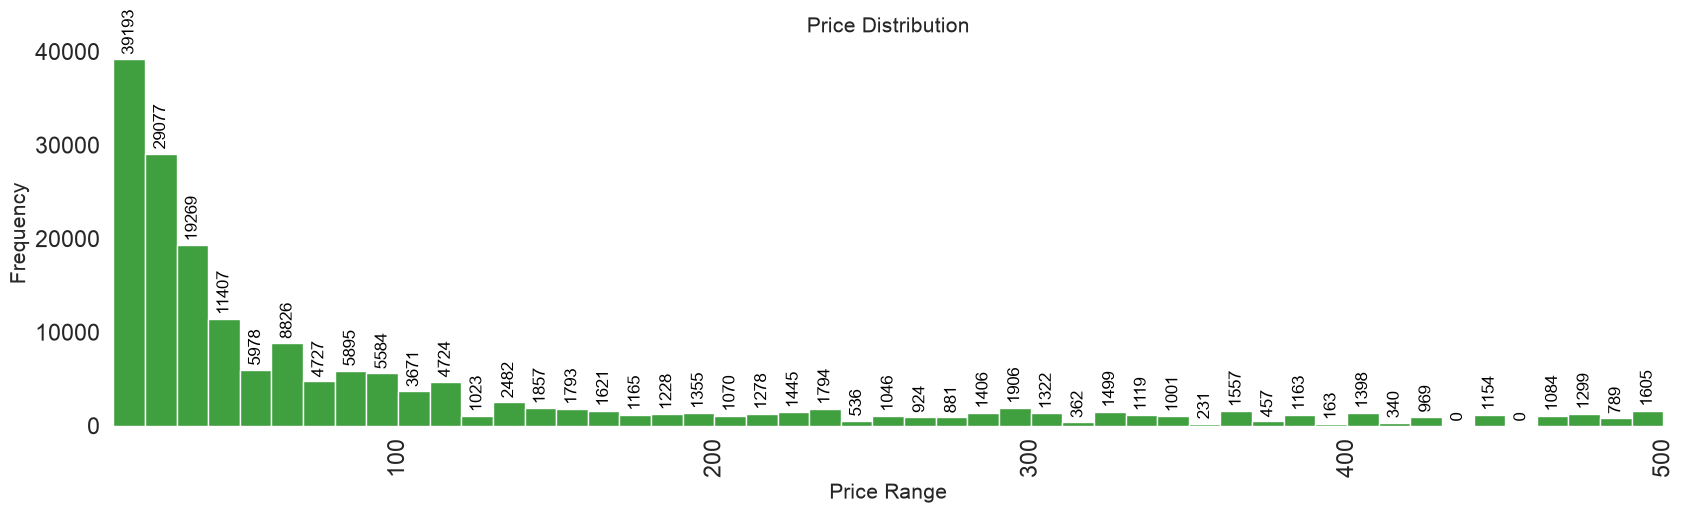

In [16]:
bins = np.arange(10, 510, 10)
sns.set_theme(font_scale =1.5)
sns.set_style("white")
fig, ax = plt.subplots(figsize = (20, 5))
sns.histplot(data=clean_df[(clean_df['Price_USD'] >= 10) & (clean_df['Price_USD'] <= 500)],
             x='Price_USD',  binrange=[10, 500], bins=bins, binwidth=10, color='green', kde=False)
ax.set_xlim(10, 500)
plt.title('Price Distribution', fontsize = 15)
ax.tick_params(axis='x', labelrotation = 90)
ax.set_xlabel('Price Range', fontsize=15)
ax.set_ylabel("Frequency", fontsize=15)
sns.despine(bottom = True, left = True)
for i in ax.containers:
    ax.bar_label(i,  padding=3, fmt='%d', color = 'black', rotation = 90,  fontsize = 12)
plt.show()

*2-Country Distribution*

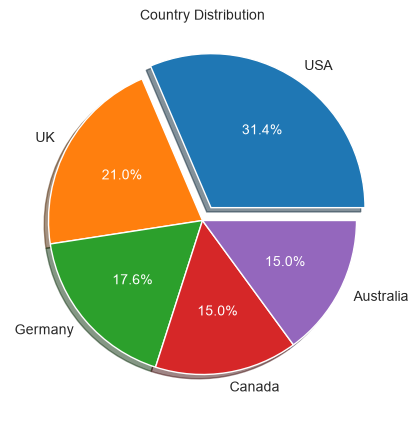

In [17]:
sns.set_theme(font_scale = 1.5)
fig, ax = plt.subplots(figsize = (5, 5))
_,_, autotexts =ax.pie(clean_df['Country'].value_counts(), labels=clean_df['Country'].value_counts().index, autopct='%2.1f%%', textprops={'size': 'xx-small'}, colors=sns.color_palette('tab10'), explode = [0.1, 0, 0, 0, 0], shadow=True)
for ins in autotexts:
    ins.set_color('white')
plt.title('Country Distribution', fontsize = 10)
plt.show()

*3-Gender Distribution*

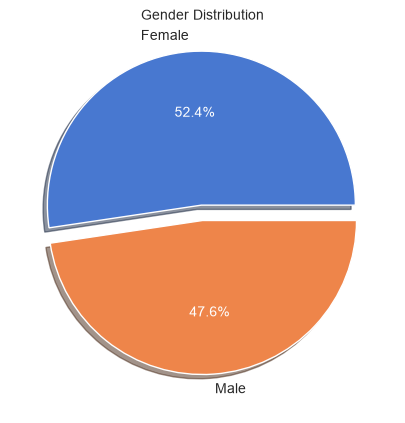

In [18]:
sns.set_theme(font_scale = 1.5)
fig, ax = plt.subplots(figsize = (5, 5))
_,_, autotexts = ax.pie(clean_df['Gender'].value_counts(),  labels=clean_df['Gender'].value_counts().index, autopct='%2.1f%%', textprops={'size': 'xx-small'}, colors=sns.color_palette('muted'), explode = [0.1, 0], shadow=True)
for ins in autotexts:
    ins.set_color('white')
plt.title('Gender Distribution', fontsize = 10)
plt.show()

*4-Order Status Distribution*

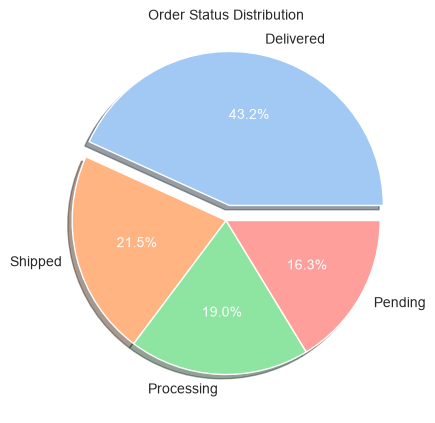

In [19]:
sns.set_theme(font_scale = 1.5)
fig, ax = plt.subplots(figsize = (5, 5))
_,_, autotexts = ax.pie(clean_df['Order_Status'].value_counts(),  labels=clean_df['Order_Status'].value_counts().index, autopct='%2.1f%%', textprops={'size': 'xx-small'}, colors=sns.color_palette('pastel'), explode = [0.1, 0, 0, 0], shadow=True)

for ins in autotexts:
    ins.set_color('white')
plt.title('Order Status Distribution', fontsize = 10)
plt.show()

*5- Product Category Distribution*

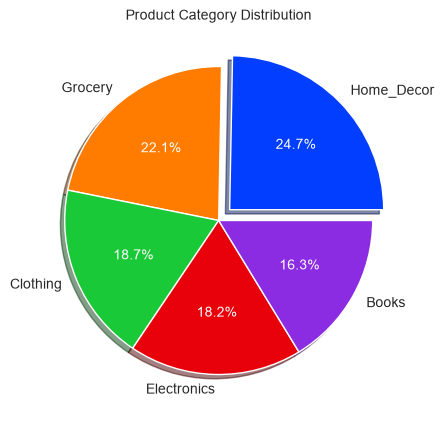

In [20]:
sns.set_theme(font_scale = 1.5)
fig, ax = plt.subplots(figsize = (5, 5))
_, _, autotexts = ax.pie(clean_df['Product_Category'].value_counts(), labels=clean_df['Product_Category'].value_counts().index, autopct='%2.1f%%', textprops={'size': 'xx-small'}, colors=sns.color_palette('bright'), explode = [0.1, 0, 0, 0, 0], shadow=True)
for ins in autotexts:
    ins.set_color('white')
plt.title('Product Category Distribution', fontsize = 10)
plt.show()

*6 - Ratings Disrubution*

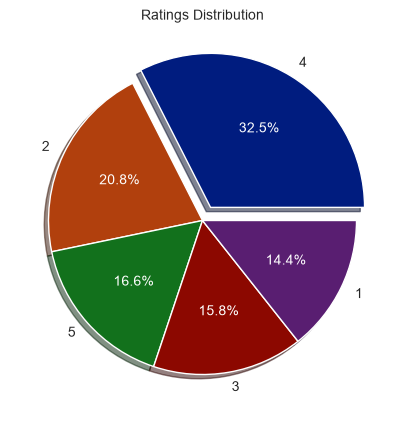

In [21]:
sns.set_theme(font_scale = 1.5)
fig, ax = plt.subplots(figsize = (5, 5))
_, _, autotexts = ax.pie(clean_df['Ratings'].value_counts(),  labels=clean_df['Ratings'].value_counts().index, autopct='%2.1f%%', textprops={'size': 'xx-small'}, colors=sns.color_palette('dark'), explode = [0.1, 0, 0, 0, 0], shadow=True)

for ins in autotexts:
    ins.set_color('white')

plt.title('Ratings Distribution', fontsize = 10)
plt.show()

*7- Count Of Each Age Group*

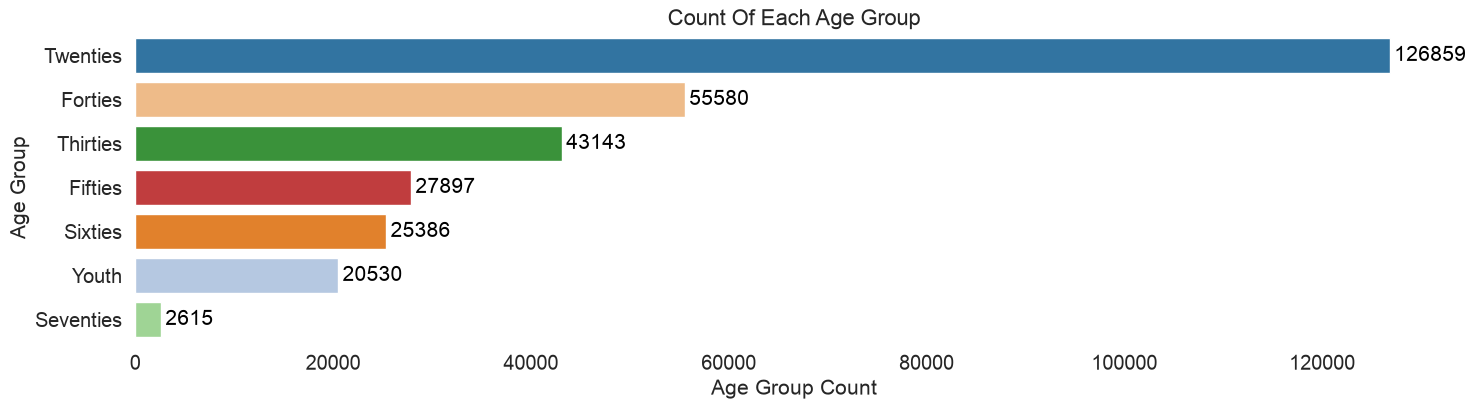

In [22]:
sns.set_theme(font_scale=1.3)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (17, 4))
sns.countplot(data=clean_df, y='Age_Group', hue='Age_Group', ax=ax, palette = sns.color_palette('tab20',7), order=clean_df['Age_Group'].value_counts(ascending = False).index)
ax.set_xlabel('Age Group Count', fontsize=15)
ax.set_ylabel("Age Group", fontsize=15)
for i in ax.containers:
    ax.bar_label(i,  padding=3, fmt='%d', color = 'black', fontsize = 15)
sns.despine(bottom = True, left = True)
ax.set_title('Count Of Each Age Group');

**B- Bivariate Analysis**

*1- Preferred Payment Method By Country*

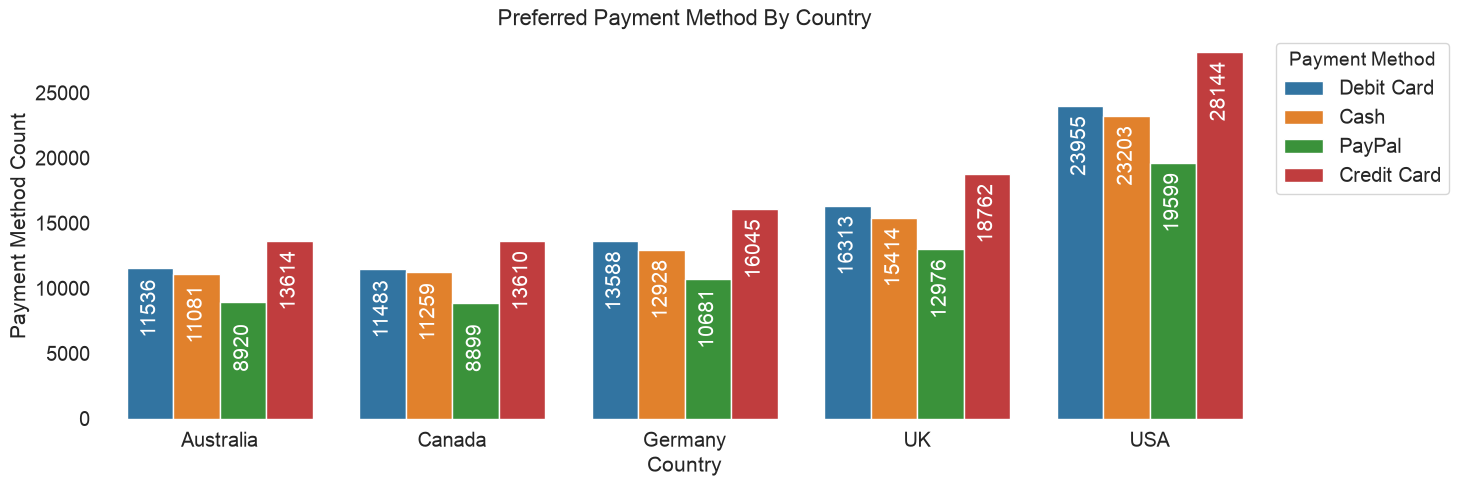

In [23]:
sns.set_theme(font_scale=1.3)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.countplot(data=clean_df, hue='Payment_Method', x='Country', ax=ax, palette = sns.color_palette('tab10'), order=clean_df['Country'].value_counts(ascending=True).index)
plt.legend(title='Payment Method', fontsize='14', title_fontsize='14')
ax.set_xlabel('Country', fontsize=15)
ax.set_ylabel("Payment Method Count", fontsize=15)
for i in ax.containers:
     ax.bar_label(i,  padding=-50, fmt='%d', color = 'white', fontsize = 15, rotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True)
ax.set_title('Preferred Payment Method By Country');

*2- Preferred Product Category Of Each Country*

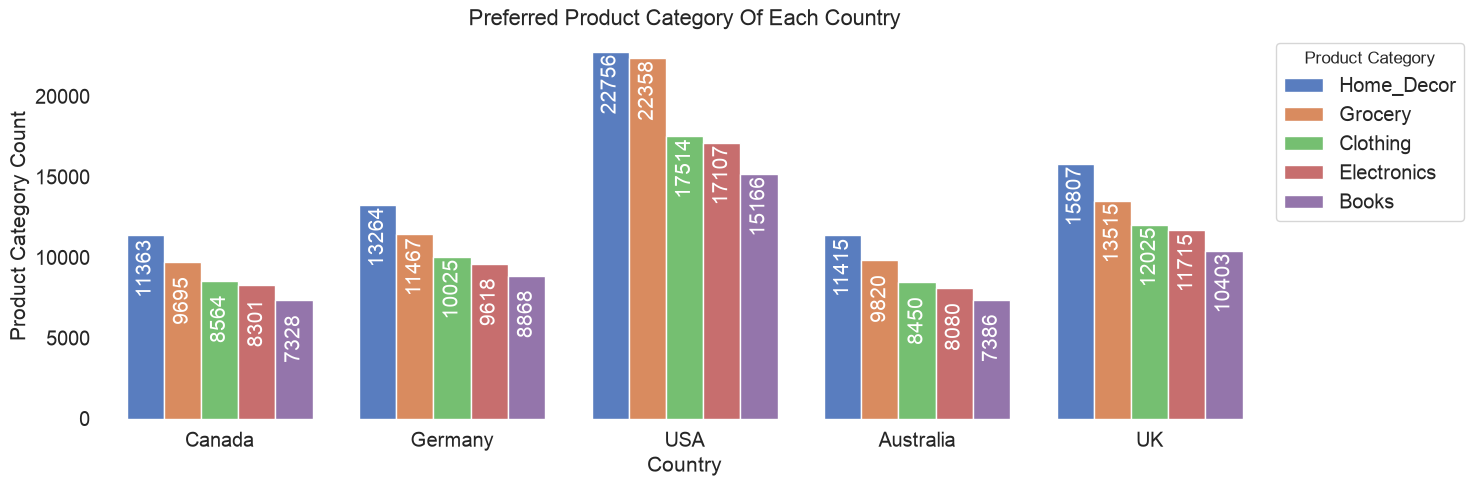

In [24]:
sns.set_theme(font_scale=1.3)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.countplot(data=clean_df, hue='Product_Category', x='Country', ax=ax, palette = sns.color_palette('muted'), hue_order=clean_df['Product_Category'].value_counts().index)
plt.legend(title='Product Category', fontsize='12', title_fontsize='12')
ax.set_xlabel('Country', fontsize=15)
ax.set_ylabel("Product Category Count", fontsize=15)
for i in ax.containers:
    ax.bar_label(i,  padding=-45, fmt='%d', color = 'white', rotation = 90,  fontsize = 15)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True)
ax.set_title('Preferred Product Category Of Each Country');

*3- Customer Segment Count By Country*

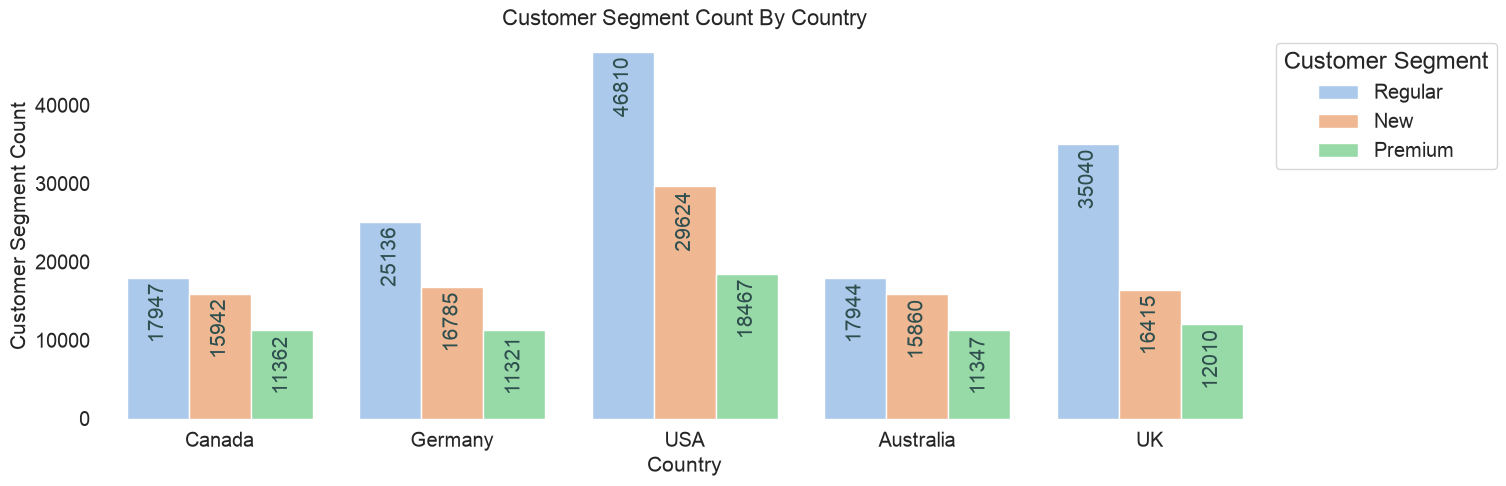

In [25]:
sns.set_theme(font_scale=1.3)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.countplot(data=clean_df, hue='Customer_Segment', x='Country', ax=ax, palette = sns.color_palette('pastel'), hue_order=clean_df['Customer_Segment'].value_counts().index)
plt.legend(title='Customer Segment', fontsize=17, title_fontsize=17)
ax.set_xlabel('Country', fontsize=15)
ax.set_ylabel("Customer Segment Count", fontsize=15)
for i in ax.containers:
    ax.bar_label(i,  padding=-47, fmt='%d', color = 'DarkSlateGray', rotation = 90, fontsize=15)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True)
ax.set_title('Customer Segment Count By Country');

*4- Count Of Income Level  By Country*

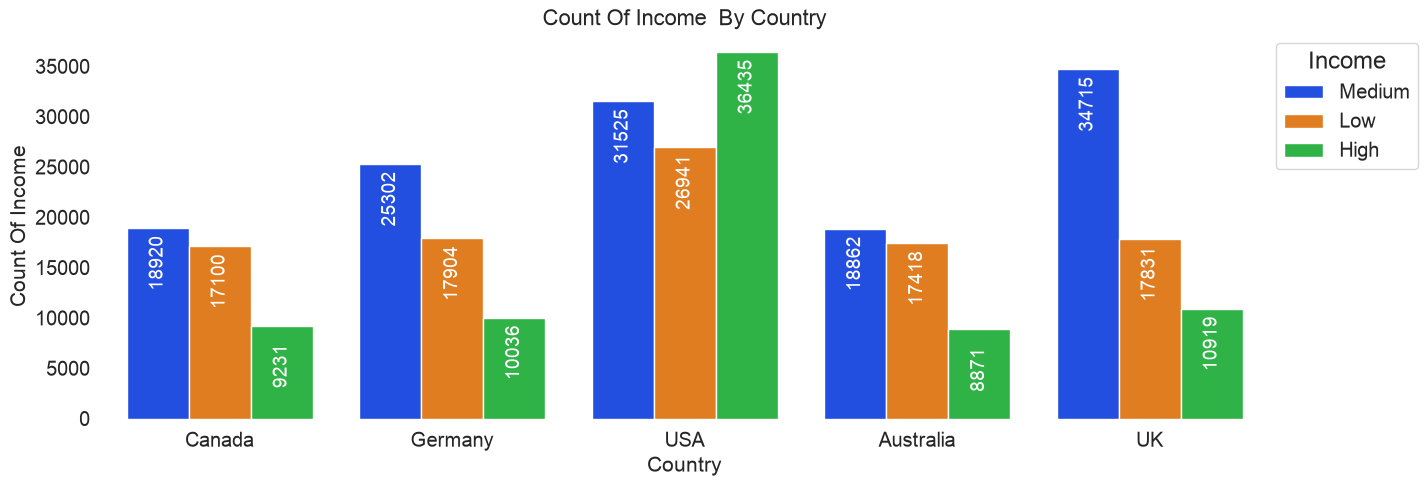

In [26]:
sns.set_theme(font_scale=1.3)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.countplot(data=clean_df, hue='Income', x='Country', ax=ax, palette = sns.color_palette('bright'), hue_order=clean_df['Income'].value_counts().index)
plt.legend(title='Income', fontsize=17, title_fontsize=17)
ax.set_xlabel('Country', fontsize=15)
ax.set_ylabel("Count Of Income", fontsize=15)
for i in ax.containers:
    ax.bar_label(i,  padding=-45, fmt='%d', color = 'white', fontsize = 14, rotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True)
ax.set_title('Count Of Income  By Country');

*5- Total Amount Spent By Country*

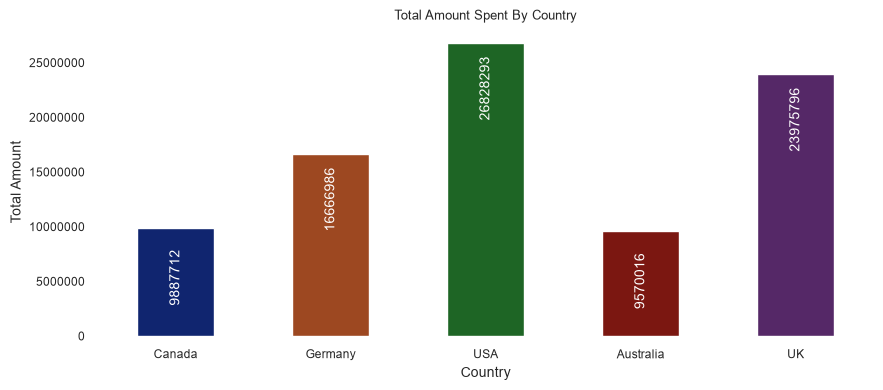

In [27]:
sns.set_theme(font_scale=0.8)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (10, 4))
sns.barplot(data=clean_df,  y = 'Total_Amount', x='Country', hue='Country', ax=ax, palette = sns.color_palette('dark'), estimator='sum', width=0.5, errorbar=None)
ax.ticklabel_format(axis='y', style='plain')
ax.set_xlabel('Country', fontsize=10)
ax.set_ylabel("Total Amount", fontsize=10)
for i in ax.containers:
    ax.bar_label(i,  padding=-56, fmt='%d', color = 'white', rotation = 90, fontsize = 10)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True)
ax.set_title('Total Amount Spent By Country');

*6- Count of Each Rating Value by Country*

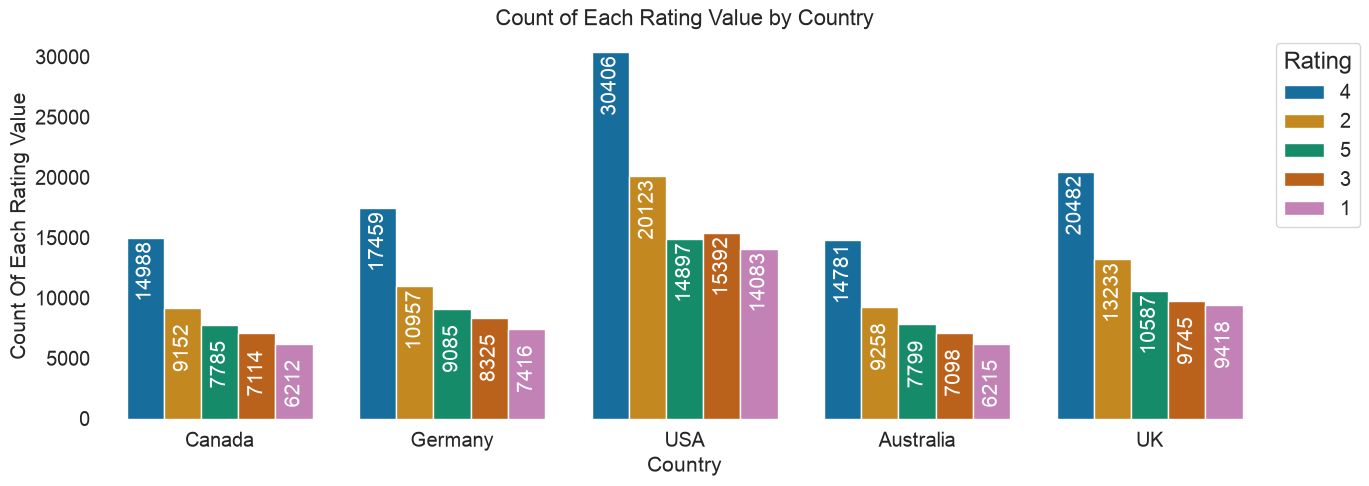

In [28]:
sns.set_theme(font_scale=1.3)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.countplot(data=clean_df, hue='Ratings', x='Country', ax=ax, palette = sns.color_palette('colorblind'), hue_order=clean_df['Ratings'].value_counts().index)
plt.legend(title='Rating', fontsize=17, title_fontsize=17)
ax.set_xlabel('Country', fontsize=15)
ax.set_ylabel("Count Of Each Rating Value", fontsize=15)
for i in ax.containers:
    ax.bar_label(i,  padding=-46, fmt='%d', color = 'white', rotation = 90, fontsize = 15)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True)
ax.set_title('Count of Each Rating Value by Country');

*7- Preferred Product Type By Product Category*

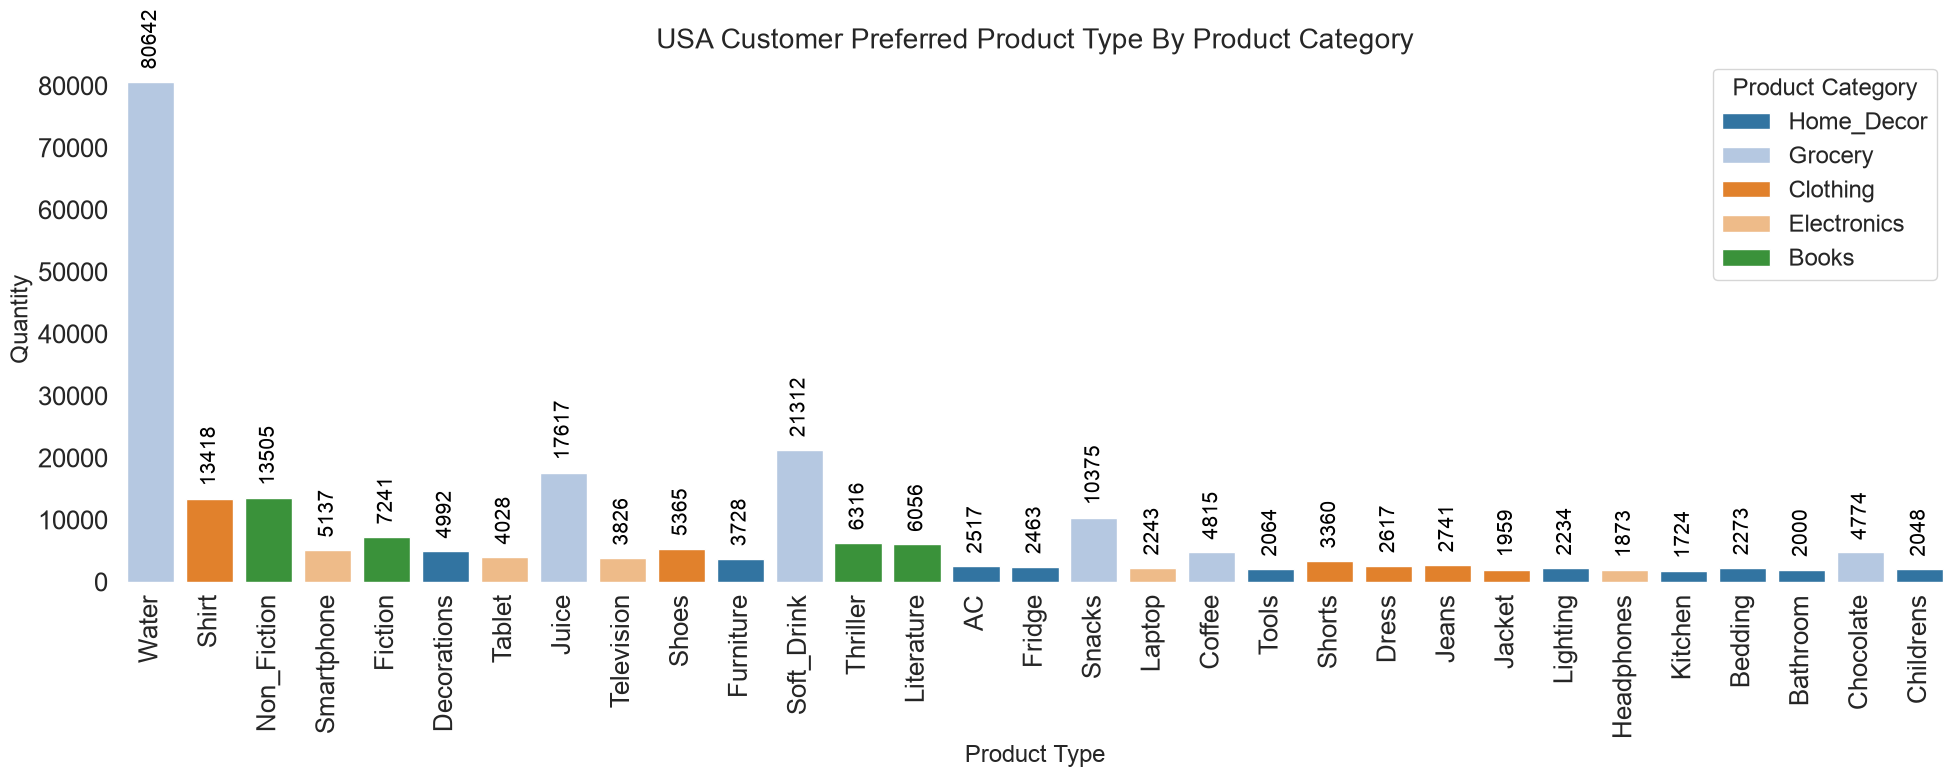

In [29]:
sns.set_theme(font_scale=1.7)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.barplot(data=usa_data, y = 'Quantity',  x='Product_Type', hue='Product_Category', hue_order=usa_data['Product_Category'].value_counts().index, ax=ax, palette = sns.color_palette('tab20'), estimator=sum, orient='v', order=usa_data['Product_Type'].value_counts().index, errorbar=None)
plt.legend(title='Product Category', fontsize=17, title_fontsize= 17)
ax.set_xlabel('Product Type', fontsize=17)
ax.set_ylabel("Quantity", fontsize=17)
ax.set_title('USA Customer Preferred Product Type By Product Category', fontsize = 20)
ax.tick_params(axis='x', labelrotation = 90)
sns.despine(bottom = True, left = True)
plt.tight_layout()
for i in ax.containers:
    ax.bar_label(i,  padding=9, fmt='%d', color = 'black', rotation = 90, fontsize = 15)


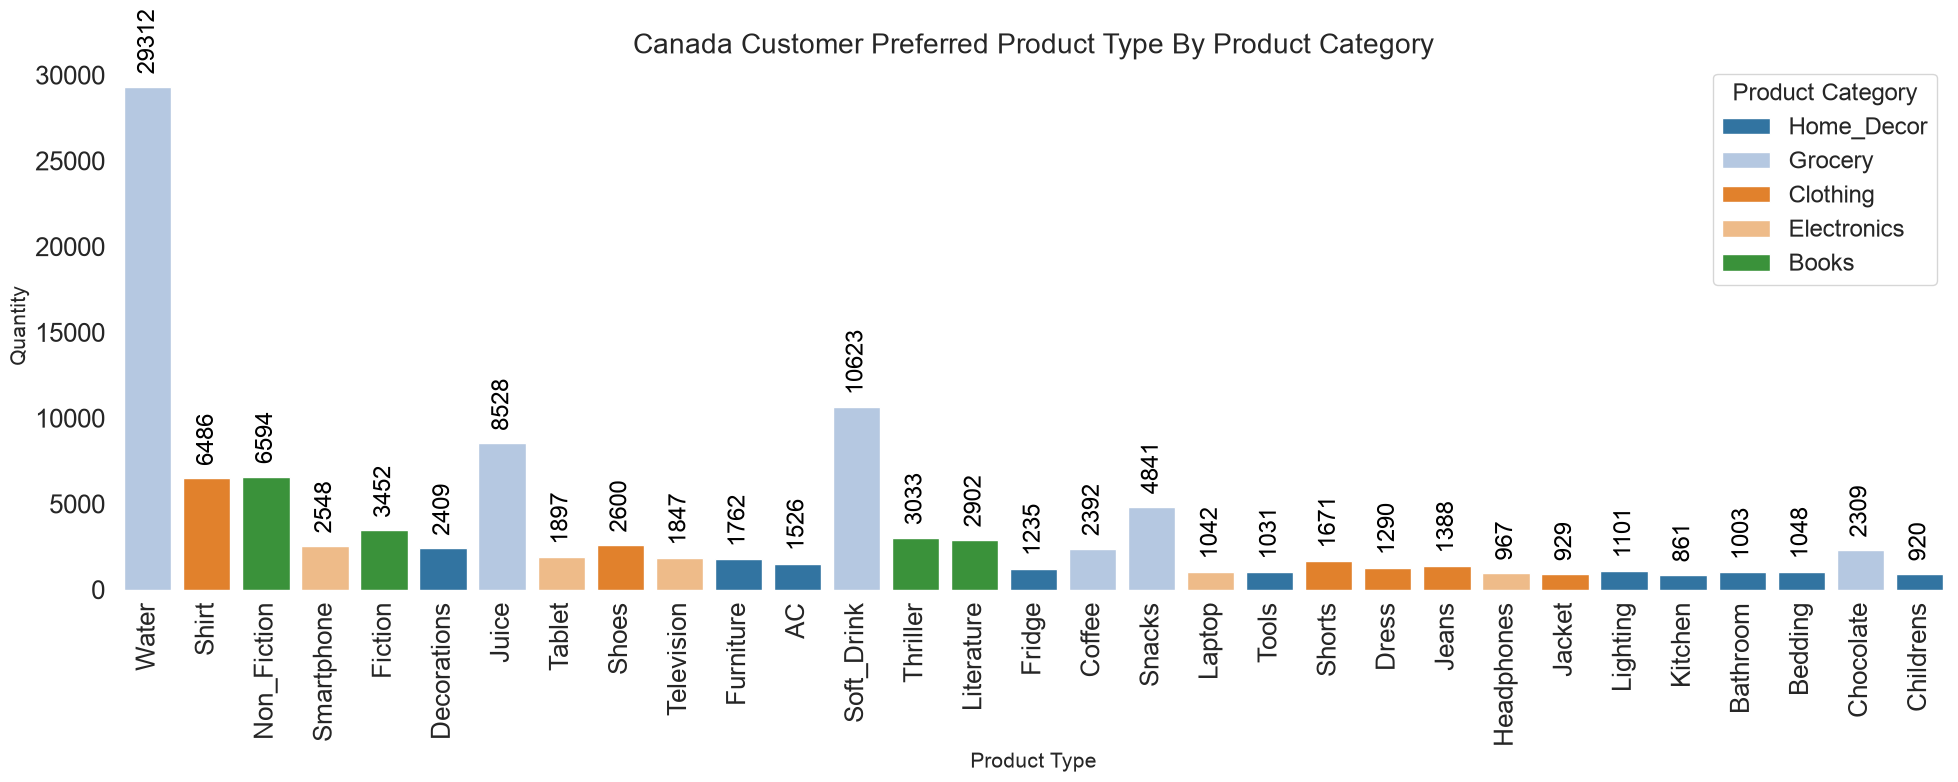

In [30]:
sns.set_theme(font_scale=1.7)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.barplot(data=canada_data, y = 'Quantity',  x='Product_Type', hue='Product_Category', hue_order=canada_data['Product_Category'].value_counts().index, ax=ax, palette = sns.color_palette('tab20'), estimator=sum, orient='v', order=canada_data['Product_Type'].value_counts().index, errorbar=None)
plt.legend(title='Product Category', fontsize=17, title_fontsize= 17)
ax.set_xlabel('Product Type', fontsize=15)
ax.set_ylabel("Quantity", fontsize=15)
ax.set_title('Canada Customer Preferred Product Type By Product Category', fontsize = 20)
ax.tick_params(axis='x', labelrotation = 90)
sns.despine(bottom = True, left = True)
plt.tight_layout()
for i in ax.containers:
    ax.bar_label(i,  padding=9, fmt='%d', color = 'black', rotation = 90, fontsize = 17)


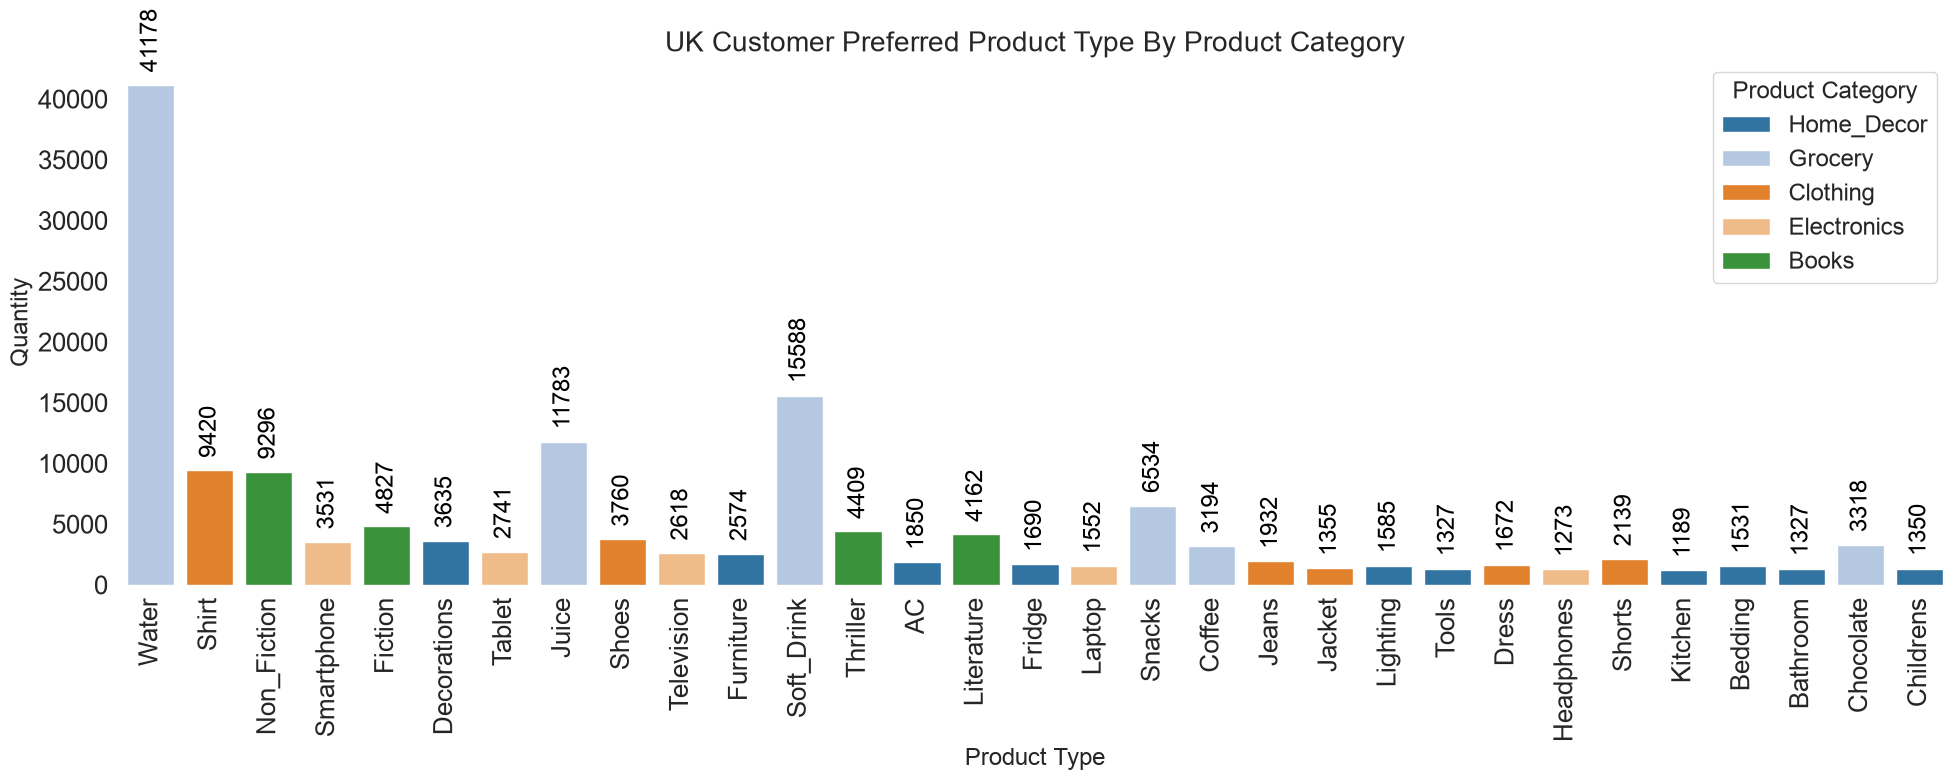

In [31]:
sns.set_theme(font_scale=1.7)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.barplot(data=uk_data, y = 'Quantity',  x='Product_Type', hue='Product_Category', hue_order=uk_data['Product_Category'].value_counts().index, ax=ax, palette = sns.color_palette('tab20'), estimator=sum, orient='v', order=uk_data['Product_Type'].value_counts().index, errorbar=None)
plt.legend(title='Product Category', fontsize=17, title_fontsize= 17)
ax.set_xlabel('Product Type', fontsize=17)
ax.set_ylabel("Quantity", fontsize=17)
ax.set_title('UK Customer Preferred Product Type By Product Category', fontsize = 20)
ax.tick_params(axis='x', labelrotation = 90)
sns.despine(bottom = True, left = True)
plt.tight_layout()
for i in ax.containers:
    ax.bar_label(i,  padding=9, fmt='%d', color = 'black', rotation = 90, fontsize = 17)


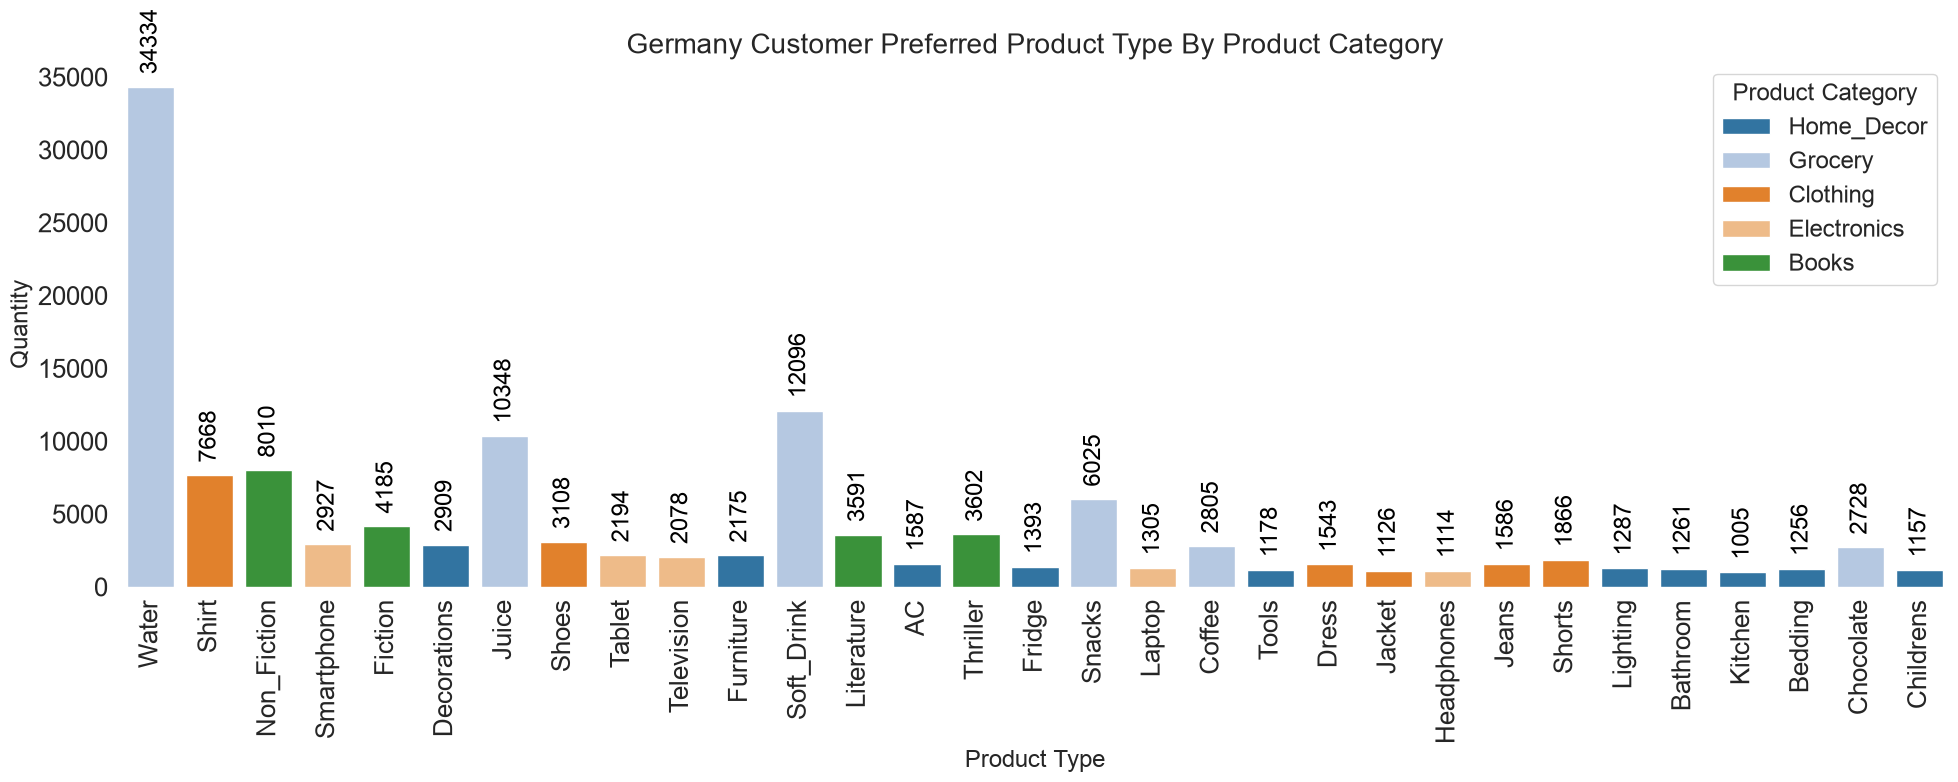

In [32]:
sns.set_theme(font_scale=1.7)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.barplot(data=germany_data, y = 'Quantity',  x='Product_Type', hue='Product_Category', hue_order=germany_data['Product_Category'].value_counts().index, ax=ax, palette = sns.color_palette('tab20'), estimator=sum, orient='v', order=germany_data['Product_Type'].value_counts().index, errorbar=None)
plt.legend(title='Product Category', fontsize=17, title_fontsize= 17)
ax.set_xlabel('Product Type', fontsize=17)
ax.set_ylabel("Quantity", fontsize=17)
ax.set_title('Germany Customer Preferred Product Type By Product Category', fontsize = 20)
ax.tick_params(axis='x', labelrotation = 90)
sns.despine(bottom = True, left = True)
plt.tight_layout()
for i in ax.containers:
    ax.bar_label(i,  padding=9, fmt='%d', color = 'black', rotation = 90, fontsize = 17)

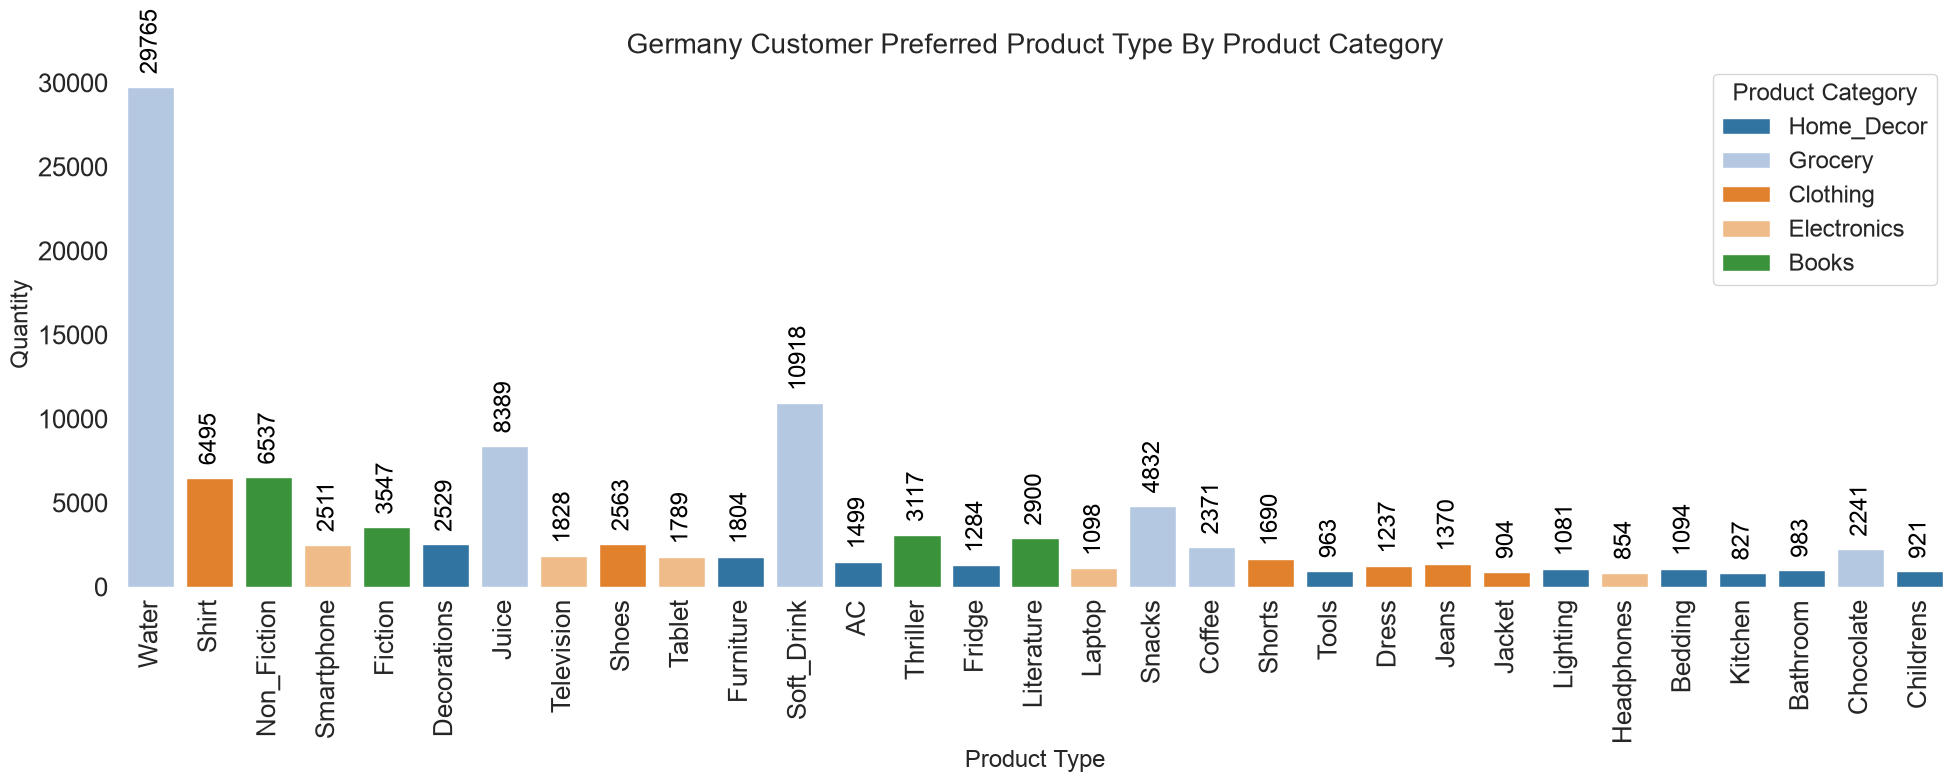

In [33]:
sns.set_theme(font_scale=1.7)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.barplot(data=australia_data, y = 'Quantity',  x='Product_Type', hue='Product_Category', hue_order=australia_data['Product_Category'].value_counts().index, ax=ax, palette = sns.color_palette('tab20'), estimator=sum, orient='v', order=australia_data['Product_Type'].value_counts().index, errorbar=None)
plt.legend(title='Product Category', fontsize=17, title_fontsize= 17)
ax.set_xlabel('Product Type', fontsize=17)
ax.set_ylabel("Quantity", fontsize=17)
ax.set_title('Germany Customer Preferred Product Type By Product Category', fontsize = 20)
ax.tick_params(axis='x', labelrotation = 90)
sns.despine(bottom = True, left = True)
plt.tight_layout()
for i in ax.containers:
    ax.bar_label(i,  padding=9, fmt='%d', color = 'black', rotation = 90, fontsize = 17)

*7- Preferred Purchased Day By Age Group*

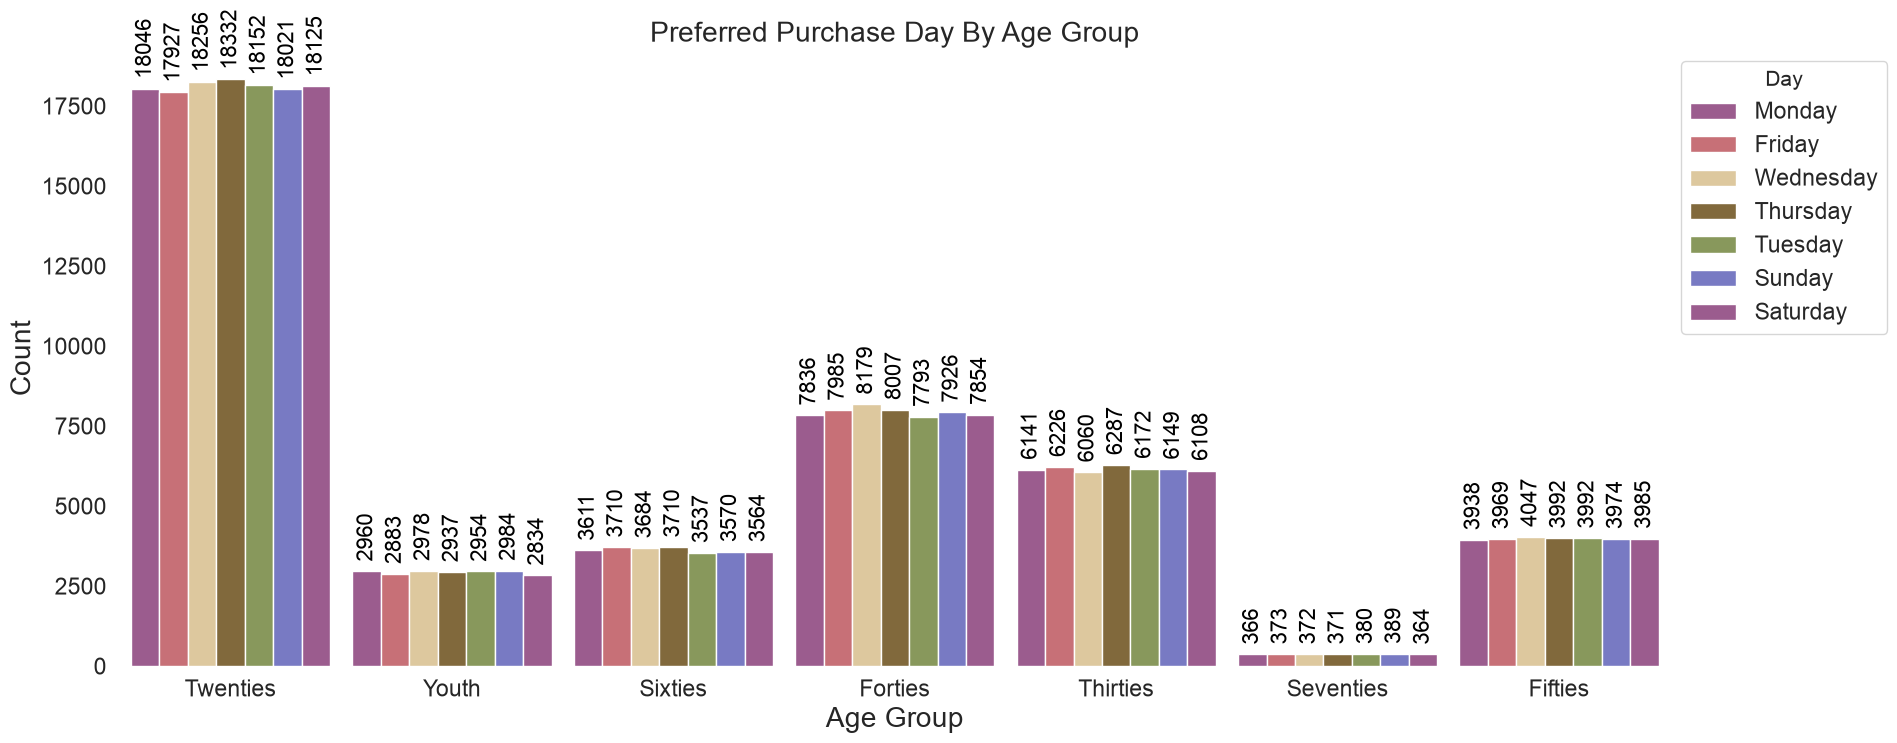

In [34]:
sns.set_theme(font_scale=1.5)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.countplot(data=clean_df, hue='Day', x='Age_Group', ax=ax, palette = sns.color_palette('tab20b_r'), width=0.9)
plt.legend(title='Day', fontsize=15, title_fontsize=15)
ax.set_xlabel('Age Group', fontsize=20)
ax.set_ylabel("Count", fontsize=20)
for i in ax.containers:
     ax.bar_label(i,  padding = 7, fmt='%d', color = 'black', fontsize = 16, rotation = 90)
sns.despine(bottom = True, left = True)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('Preferred Purchase Day By Age Group', fontsize = 20);

*8-Preferred Product Category By Age Group*

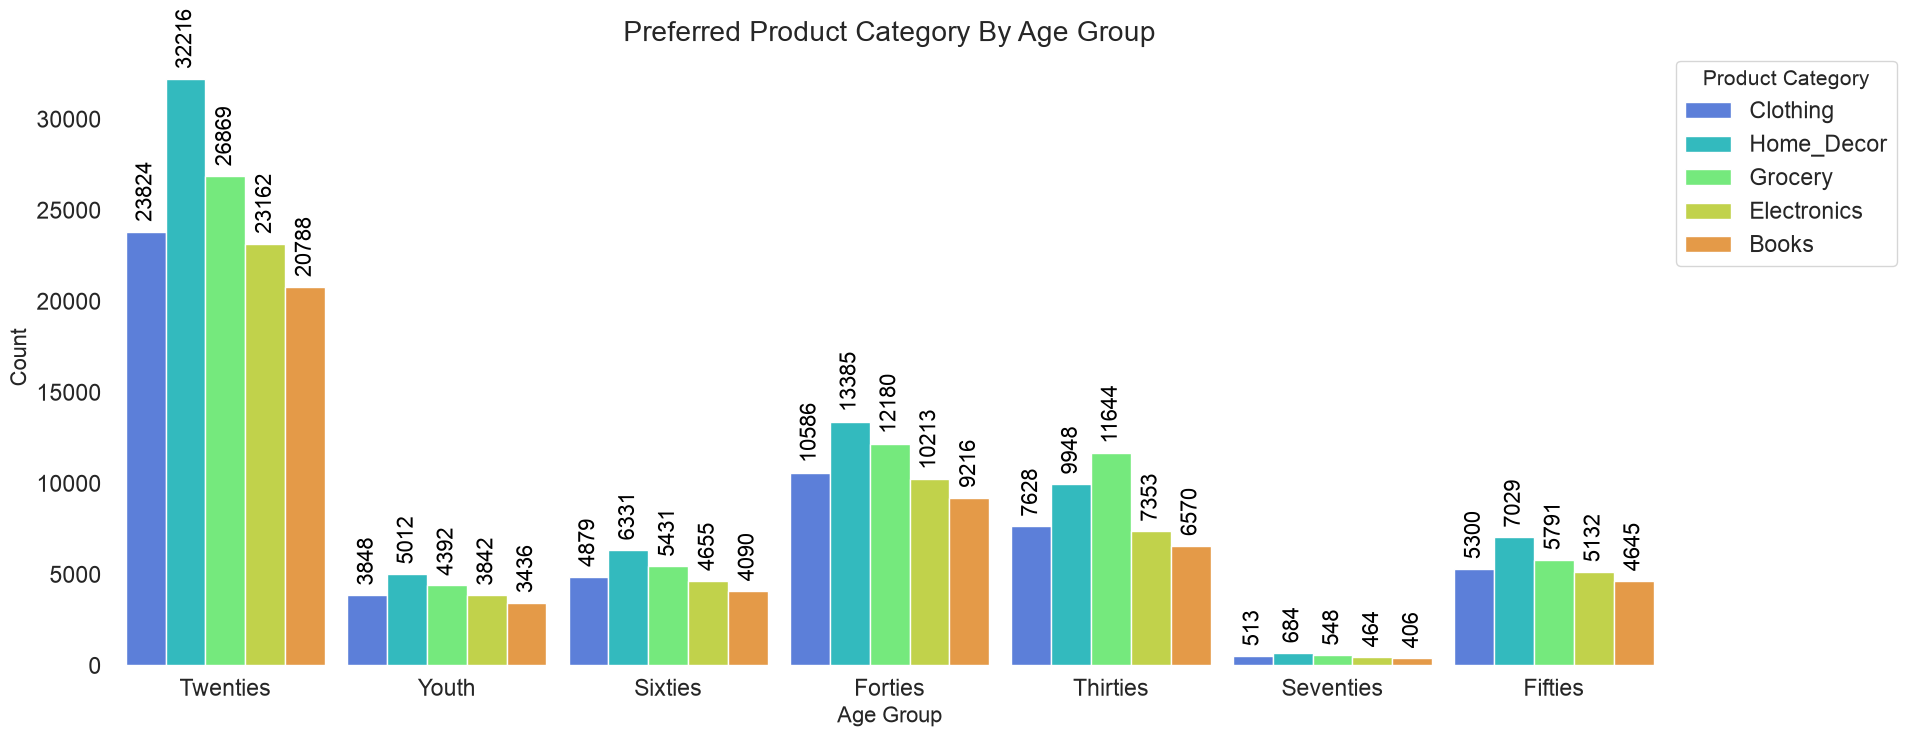

In [35]:
sns.set_theme(font_scale=1.5)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.countplot(data=clean_df, hue='Product_Category', x='Age_Group', ax=ax, palette = sns.color_palette('turbo'), width=0.9)
plt.legend(title='Product Category', fontsize=15, title_fontsize=15)
ax.set_xlabel('Age Group', fontsize=16)
ax.set_ylabel("Count", fontsize=16)
for i in ax.containers:
     ax.bar_label(i,  padding = 7, fmt='%d', color = 'black', fontsize = 16, rotation = 90 )
sns.despine(bottom = True, left = True)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('Preferred Product Category By Age Group', fontsize = 20);

**C- Multivariate Analysis**

**a-Chart**

*1- Monthly Total Amount Spent By Country*

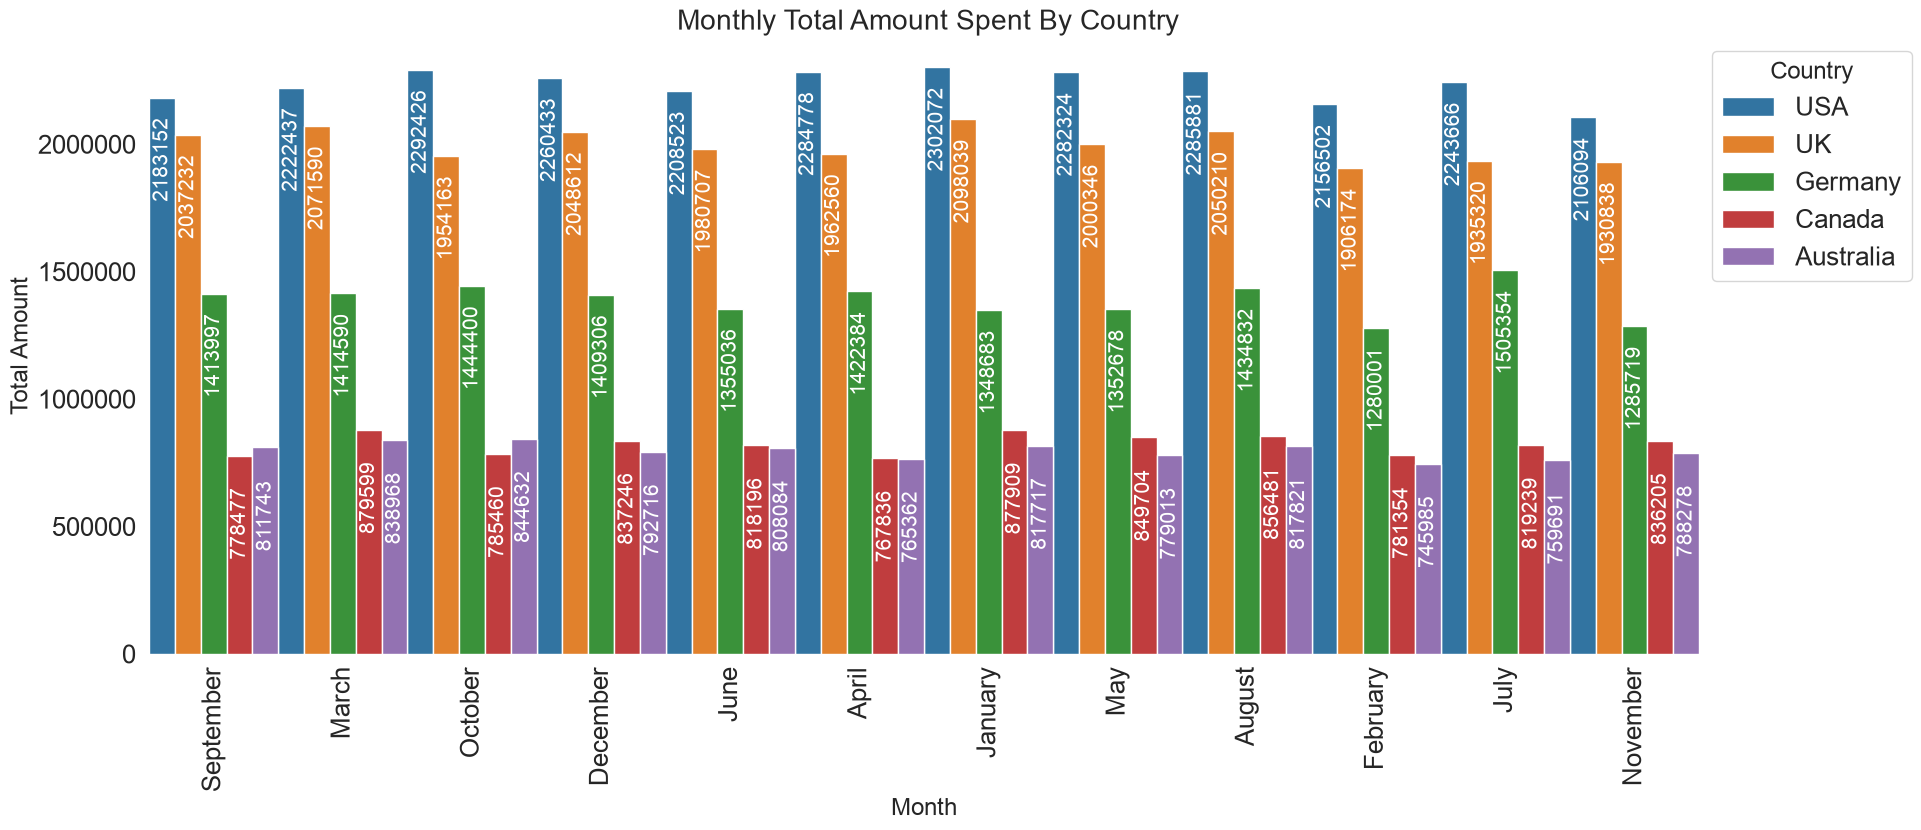

In [36]:
sns.set_theme(font_scale=1.7)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.barplot(data=clean_df, y = 'Total_Amount' , hue='Country', x='Month_Name', ax=ax, palette = sns.color_palette('tab10'), hue_order=clean_df['Country'].value_counts(ascending = False).index, estimator=sum, width=1, errorbar=None)
ax.set_xlabel('Month', fontsize=17)
ax.set_ylabel("Total Amount", fontsize=17)
plt.legend(title='Country', fontsize=17, title_fontsize=17)
for i in ax.containers:
    ax.bar_label(i,  padding=-75, fmt='%4d', color = 'white', rotation = 90, fontsize = 15)
ax.set_title(' Monthly Total Amount Spent By Country', fontsize = 20)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True);

*2- Daily Total Amount Spent By Country*

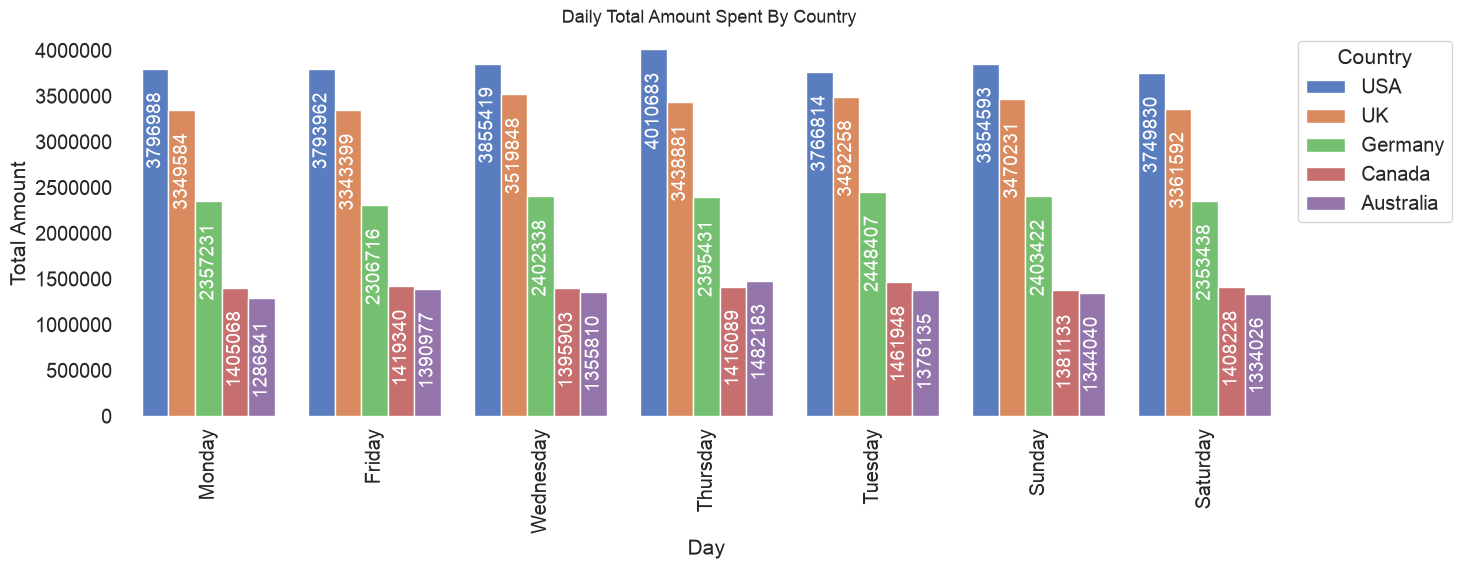

In [37]:
sns.set_theme(font_scale=1.3)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.barplot(data=clean_df, y = 'Total_Amount' , hue='Country', x='Day', ax=ax, palette = sns.color_palette('muted'), hue_order=clean_df['Country'].value_counts(ascending = False).index, estimator=sum, errorbar=None)
ax.set_xlabel('Day', fontsize=15)
ax.set_ylabel("Total Amount", fontsize=15)
plt.legend(title='Country', fontsize=15, title_fontsize=15)
for i in ax.containers:
    ax.bar_label(i,  padding=-72, fmt='%4d', color = 'white', rotation = 90, fontsize = 14)
ax.set_title(' Daily Total Amount Spent By Country', fontsize = 13)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True);

*3- Seasonally Total Amount Spent By Country*

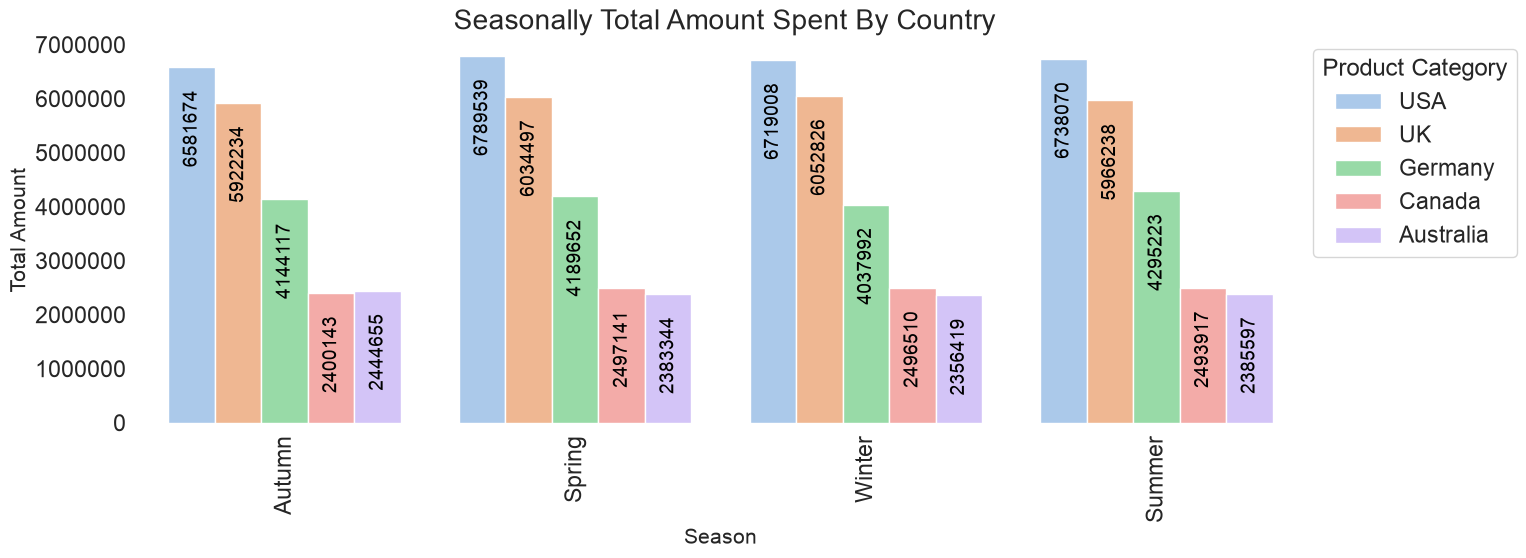

In [38]:
sns.set_theme(font_scale=1.5)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.barplot(data=clean_df, y = 'Total_Amount' , hue='Country', x='Season', ax=ax, palette = sns.color_palette('pastel'), hue_order=clean_df['Country'].value_counts(ascending = False).index, estimator=sum, errorbar=None)
ax.set_xlabel('Season', fontsize=15)
ax.set_ylabel("Total Amount", fontsize=15)
plt.legend(title='Product Category', fontsize=17, title_fontsize=17)
for i in ax.containers:
    ax.bar_label(i,  padding=-72, fmt='%4d', color = 'black', rotation = 90, fontsize = 14)
ax.set_title(' Seasonally Total Amount Spent By Country', fontsize = 20)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True);

*4- Quarterly Total Amount Spent By Country*

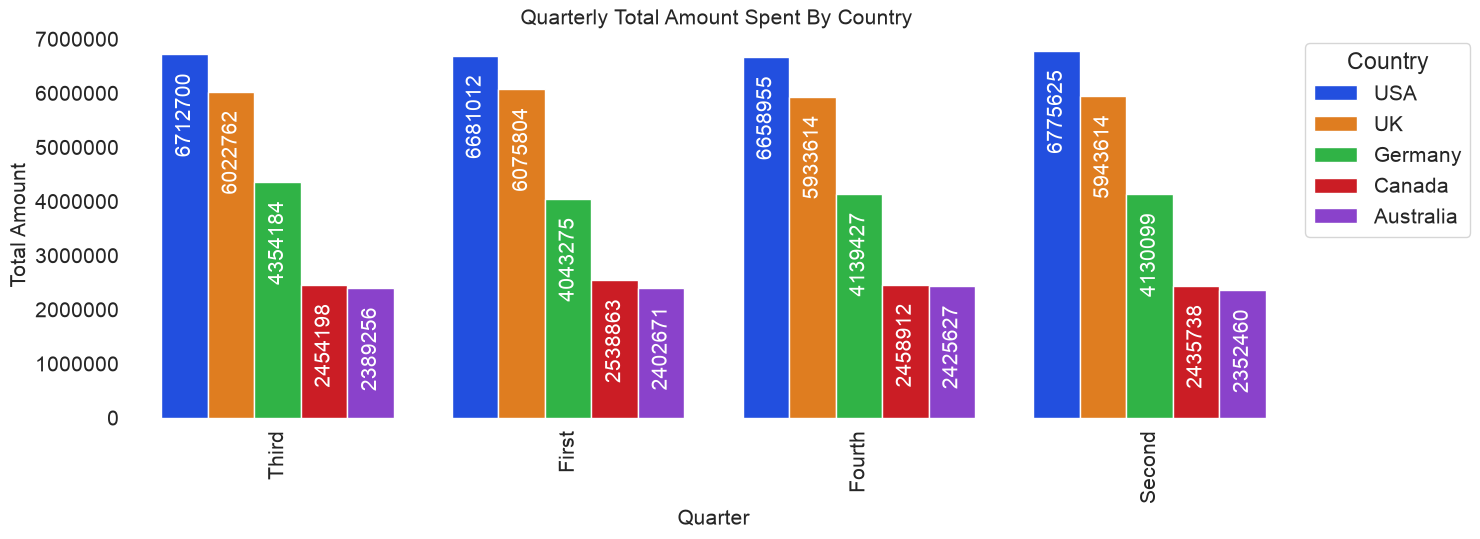

In [39]:
sns.set_theme(font_scale=1.4)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.barplot(data=clean_df, y = 'Total_Amount' , hue='Country', x='Quarter', ax=ax, palette = sns.color_palette('bright'), hue_order=clean_df['Country'].value_counts(ascending = False).index, estimator=sum, errorbar=None)
ax.set_xlabel('Quarter', fontsize=15)
ax.set_ylabel("Total Amount", fontsize=15)
for i in ax.containers:
    ax.bar_label(i,  padding=-74, fmt='%4d', color = 'white', rotation = 90, fontsize = 15)
ax.set_title(' Quarterly Total Amount Spent By Country', fontsize = 15)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True);

*5- Total Amount Spent By Each Customer Segment By Country*

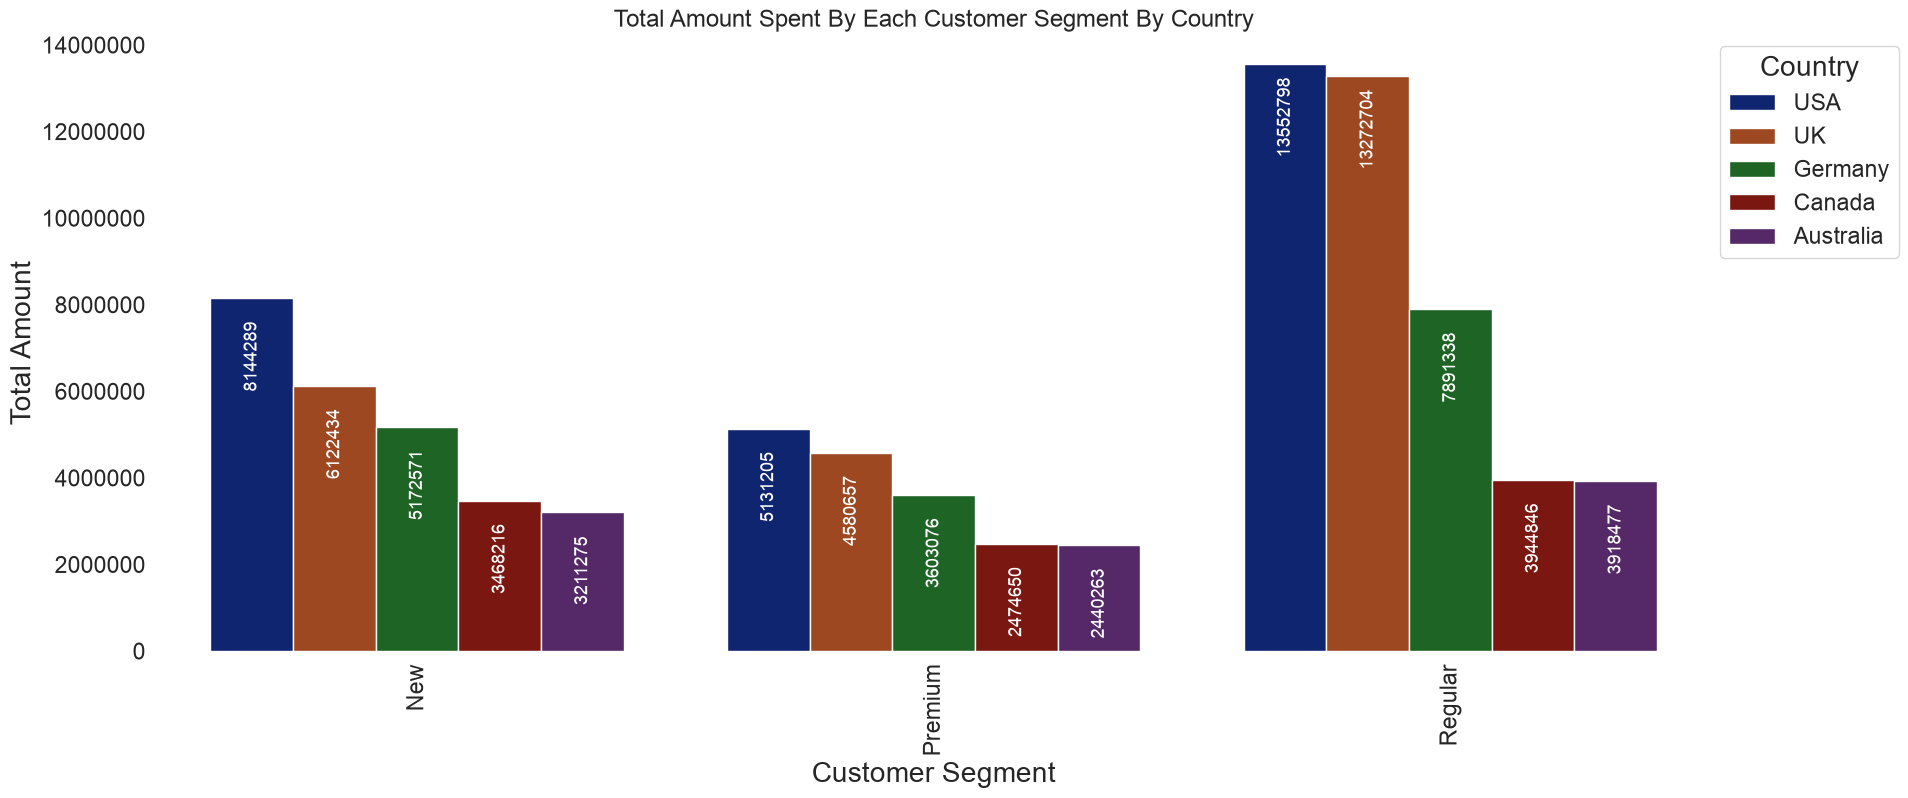

In [40]:
sns.set_theme(font_scale=1.5)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.barplot(data=clean_df, y = 'Total_Amount', hue='Country', x='Customer_Segment', ax=ax, palette = sns.color_palette('dark'), hue_order=clean_df['Country'].value_counts(ascending = False).index, estimator=sum, errorbar=None)
plt.legend(title='Country', fontsize= 20, title_fontsize=20)
ax.set_xlabel('Customer Segment', fontsize=20)
ax.set_ylabel("Total Amount", fontsize=20)
ax.set_title('Total Amount Spent By Each Customer Segment By Country', fontsize = 17)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
for i in ax.containers:
    ax.bar_label(i,  padding=-67, fmt='%d', color = 'white', rotation = 90, fontsize = 13)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True);

*6- Total Amount Spent Depending On Income Level By Country*

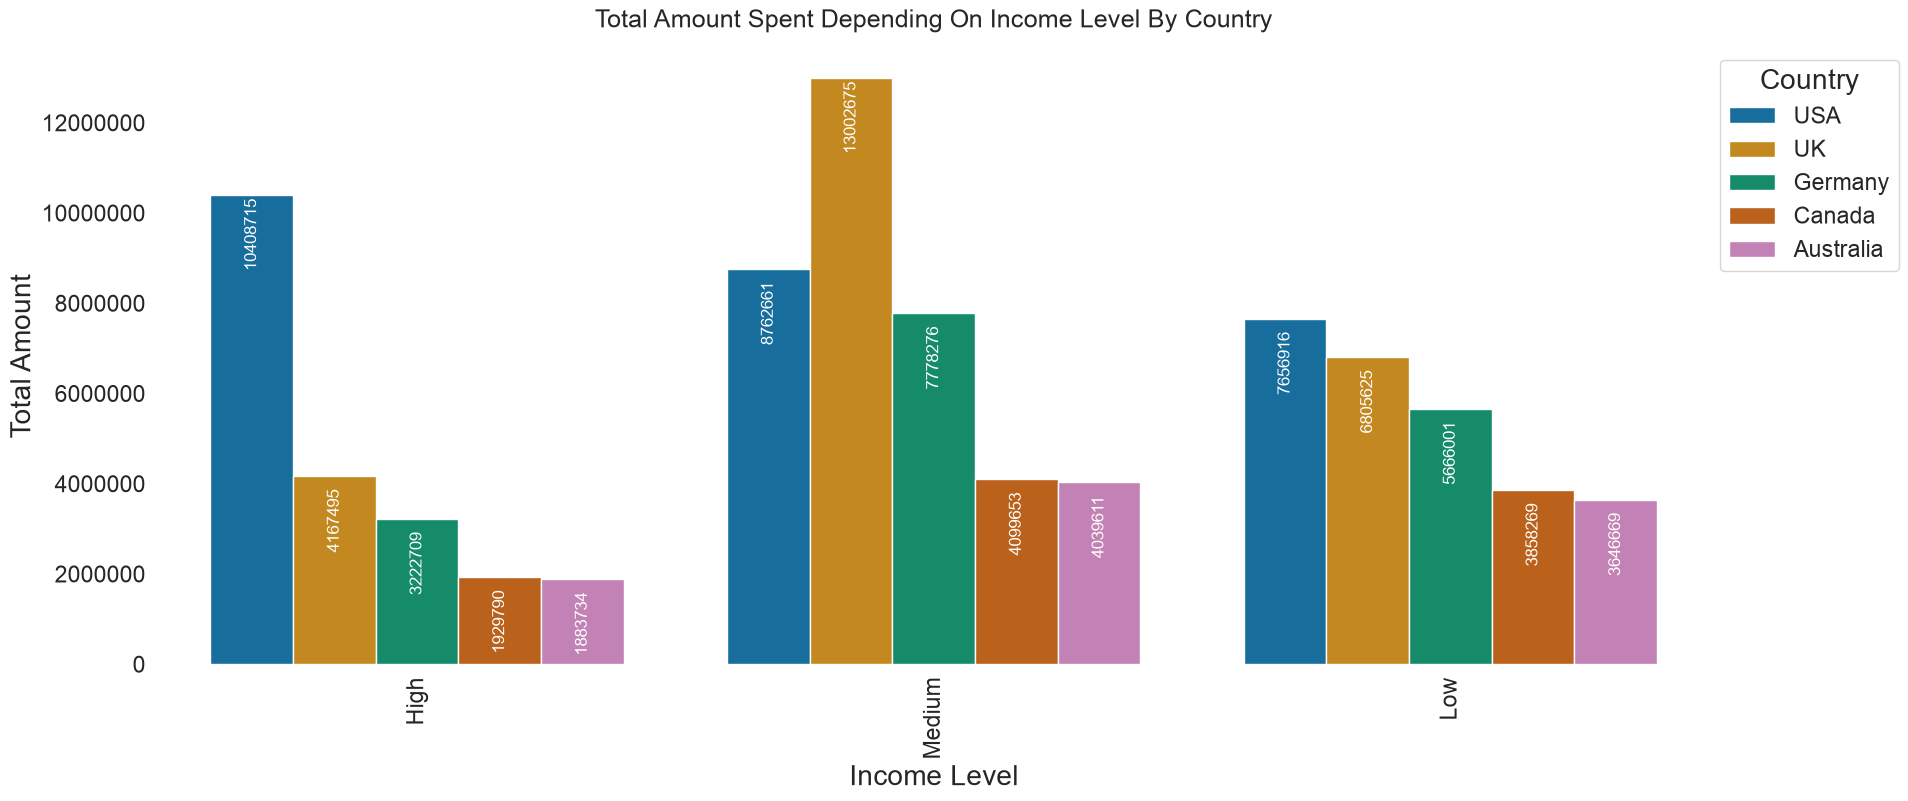

In [41]:
sns.set_theme(font_scale=1.5)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 8))
sns.barplot(data=clean_df, y = 'Total_Amount', hue='Country', x='Income', ax=ax, palette = sns.color_palette('colorblind'), hue_order=clean_df['Country'].value_counts(ascending = False).index, estimator=sum, errorbar=None)
plt.legend(title='Country', fontsize= 20, title_fontsize=20)
ax.set_xlabel('Income Level', fontsize=20)
ax.set_ylabel("Total Amount", fontsize=20)
ax.set_title('Total Amount Spent Depending On Income Level By Country', loc="center", pad=15)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
for i in ax.containers:
    ax.bar_label(i,  padding=-55, fmt='%d', color = 'white', rotation = 90, fontsize = 12)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True);

*7- Gender Preferred Product Category By Country*

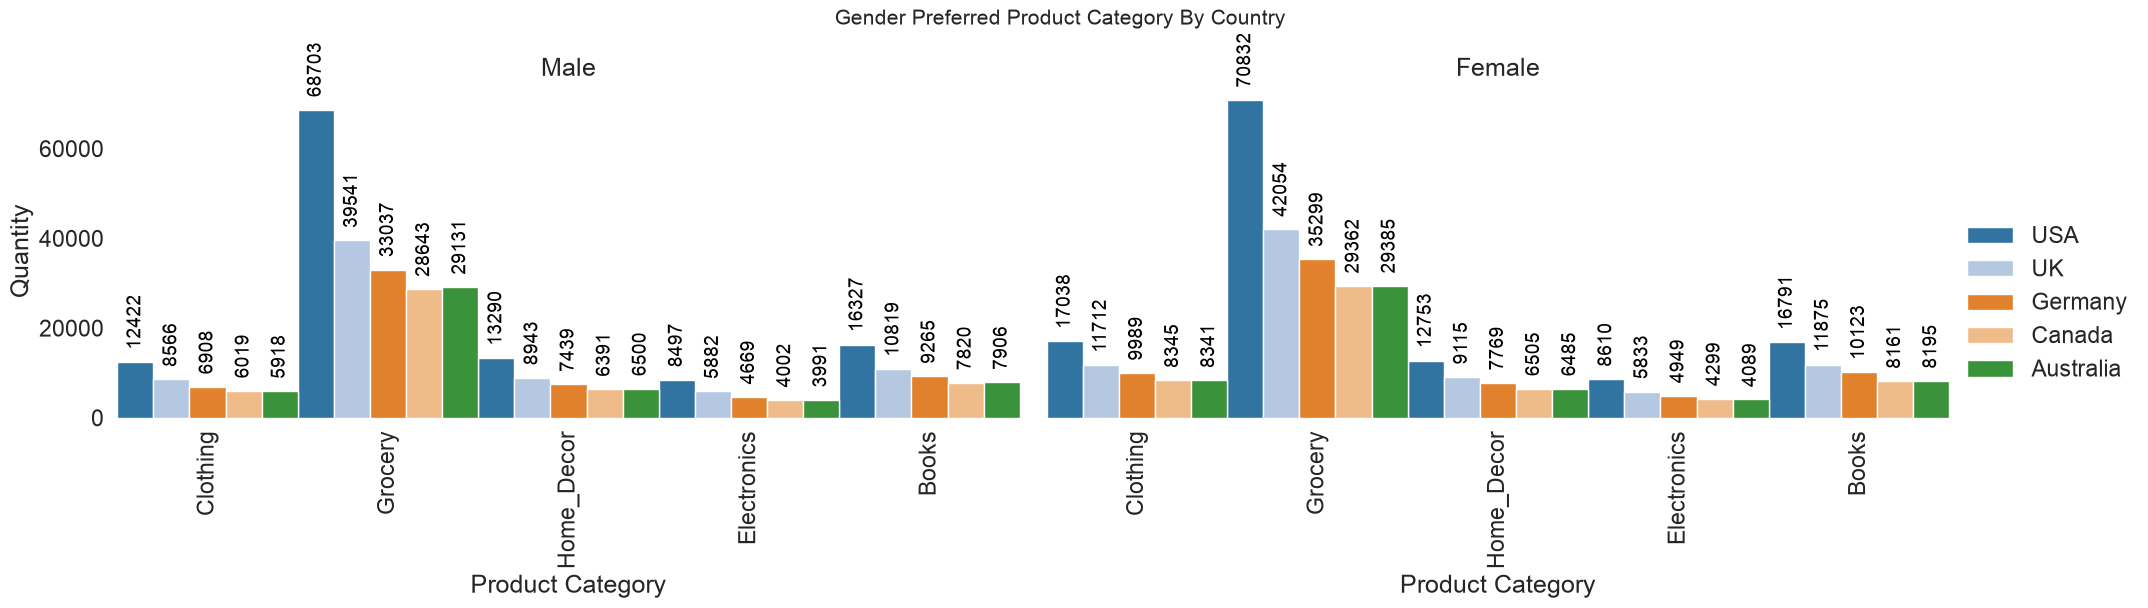

In [42]:
g = sns.FacetGrid(clean_df,  col='Gender',  height=5, aspect=2)
sns.set_style('white')
g.map_dataframe(sns.barplot, x= 'Product_Category',  y='Quantity', palette = sns.color_palette('tab20'), hue = 'Country', hue_order=clean_df['Country'].value_counts(ascending = False).index, estimator=sum, width = 1, errorbar = None)
g.set_titles(col_template='{col_name}')
g.set_axis_labels('Product Category', "Quantity")
g.figure.subplots_adjust(top=0.85)
g.figure.suptitle('Gender Preferred Product Category By Country',  fontsize=15, verticalalignment = 'center', horizontalalignment = 'center')
g.set_xticklabels(rotation=90)
for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=9, fmt='%d', color='black', rotation=90, fontsize=14)
sns.despine(bottom = True, left = True);
g.add_legend();

*8- Product Category Average Rating By Country*

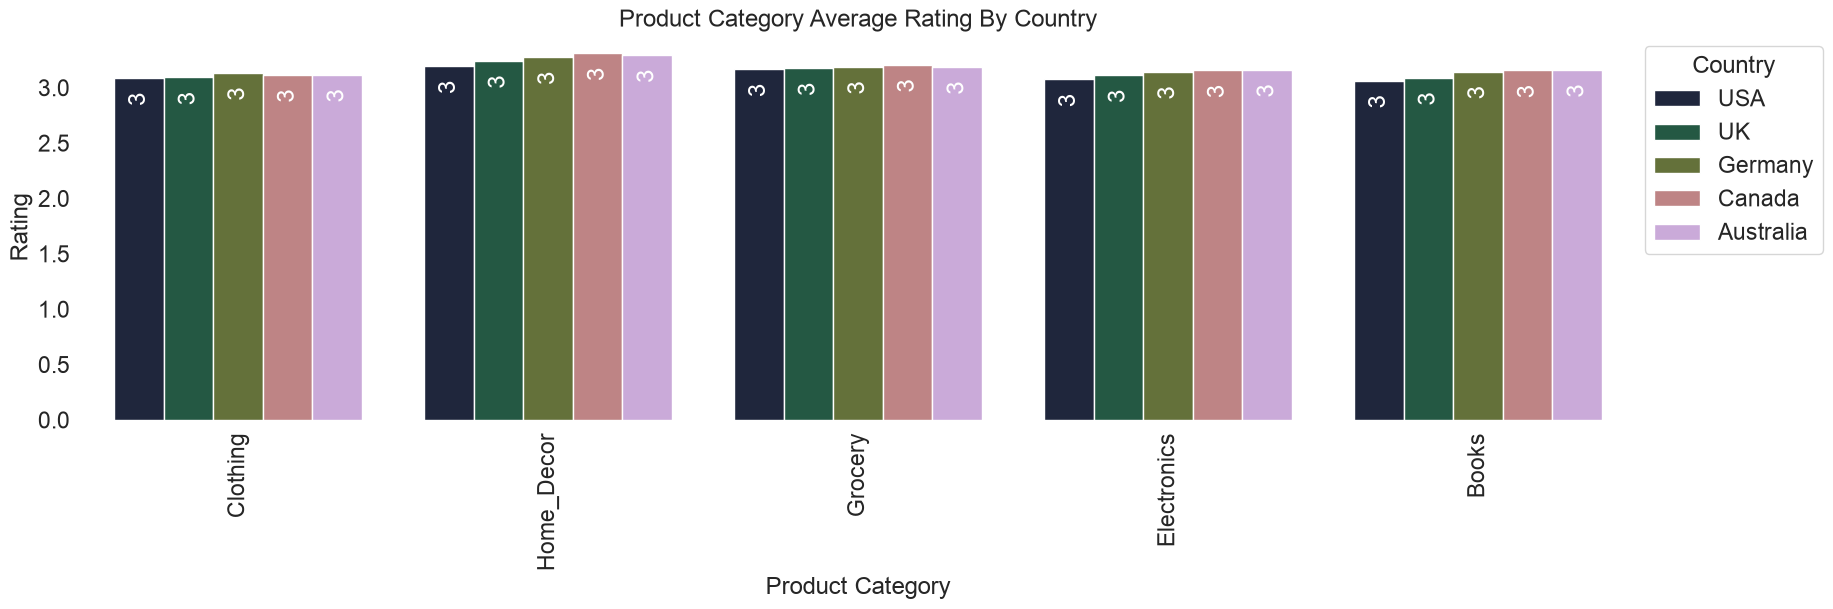

In [43]:
sns.set_theme(font_scale=1.5)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (20, 5))
sns.barplot(data=clean_df, y = 'Ratings', hue='Country', x='Product_Category', ax=ax, palette = sns.color_palette('cubehelix'), hue_order=clean_df['Country'].value_counts(ascending = False).index, errorbar= None)
plt.legend(title='Country', fontsize= 17, title_fontsize= 17)
ax.set_xlabel('Product Category', fontsize=17)
ax.set_ylabel("Rating", fontsize=17)
ax.set_title('Product Category Average Rating By Country', fontsize = 17)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
for i in ax.containers:
    ax.bar_label(i,  padding=-20, fmt='%d', color = 'white', rotation = 90, fontsize = 17)
sns.despine(bottom = True, left = True)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1));

*9- Product Category Amount Spent By Country*

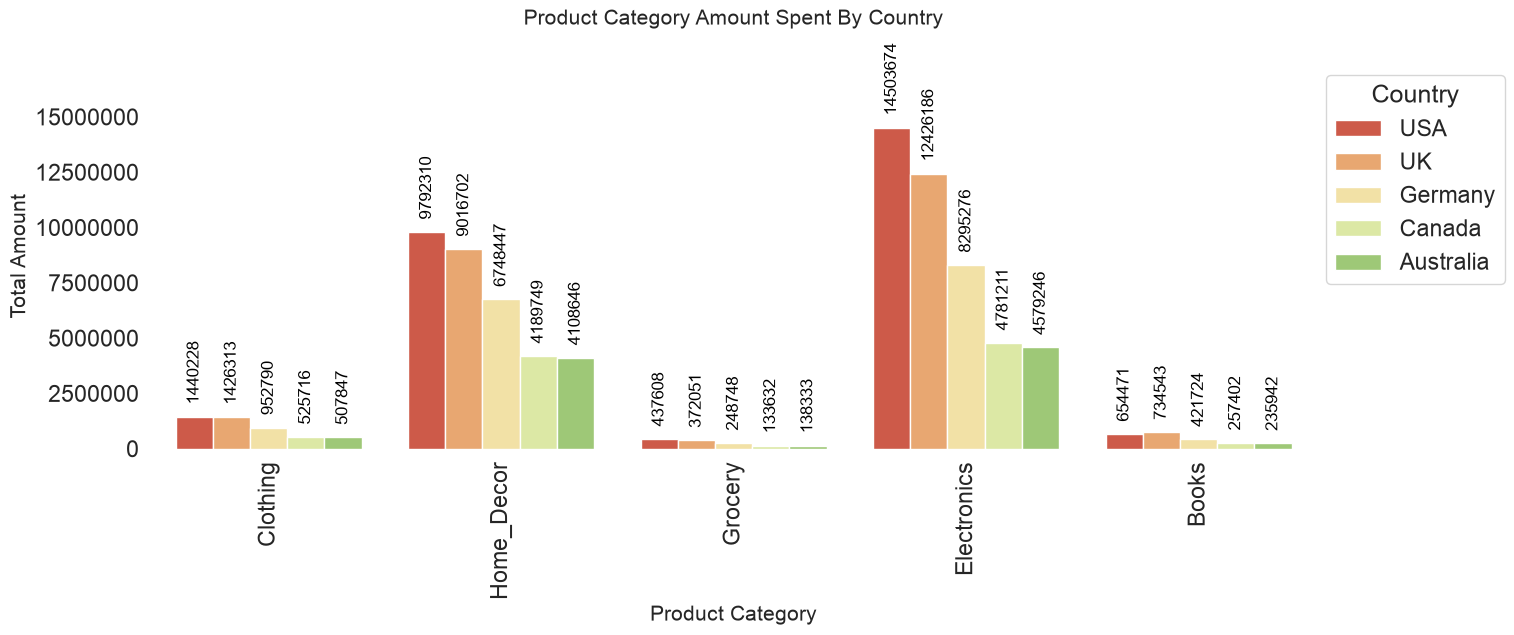

In [44]:
sns.set_theme(font_scale=1.5)
sns.set_style('white')
fig, ax = plt.subplots(figsize=(15, 5))

sns.barplot(
    data=clean_df, 
    y='Total_Amount', 
    hue='Country', 
    x='Product_Category', 
    ax=ax, 
    palette=sns.color_palette('RdYlGn'), 
    hue_order=clean_df['Country'].value_counts(ascending=False).index, 
    estimator=sum, 
    errorbar=None
)

ax.set_xlabel('Product Category', fontsize=15)
ax.set_ylabel("Total Amount", fontsize=15)

for i in ax.containers:
    ax.bar_label(i, padding=9, fmt='%4d', color='black', rotation=90, fontsize=12)

# Moved the title higher up using y=1.08 and added headroom to y-axis to avoid label overlap
ax.set_title('Product Category Amount Spent By Country', fontsize=15,  y=1.08)
ax.margins(y=0.2)  # Adds extra space at the top of the plot for the rotated numbers

ax.tick_params(axis='x', labelrotation=90)
plt.ticklabel_format(style='plain', axis='y')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom=True, left=True)
plt.show()

*10-Day Of Month Total Amount Spent By Country*

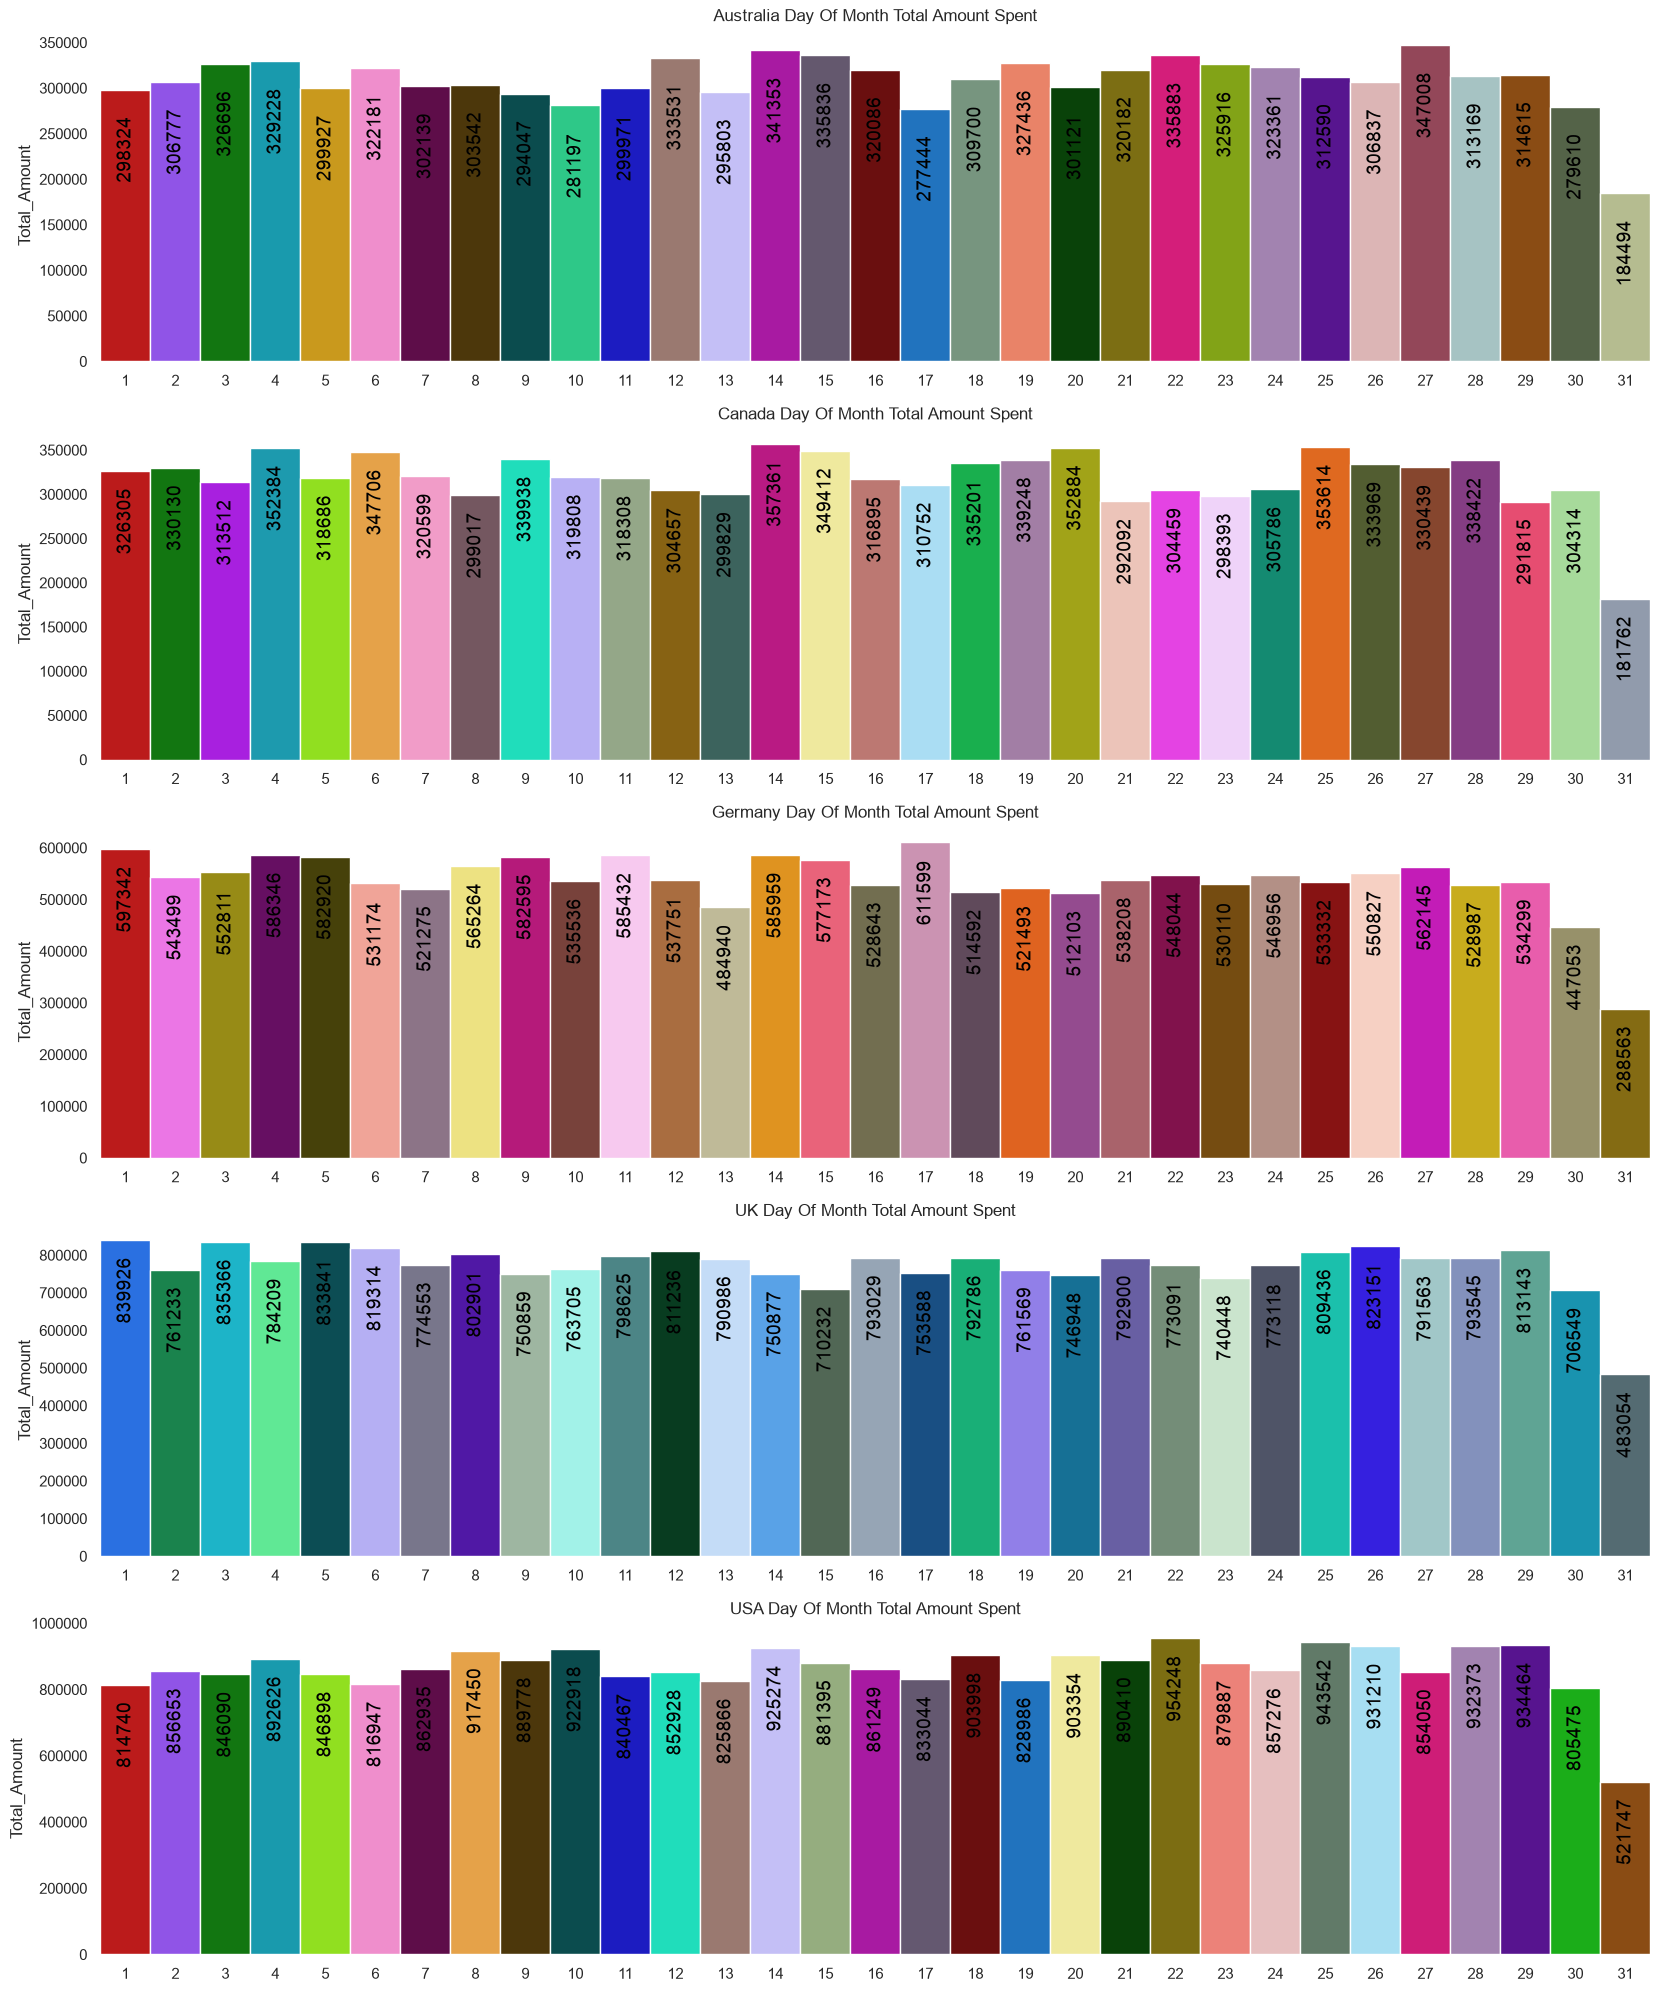

In [45]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(ncols=1, nrows = 5, figsize = (20, 25))
sns.barplot(data=australia_data, x = 'Day_Of_Month' , y='Total_Amount', ax=ax1, palette = sns.color_palette(cc.glasbey_dark, n_colors=31), width=1, estimator=sum, errorbar=None)
sns.barplot(data=canada_data, x = 'Day_Of_Month' , y='Total_Amount', ax=ax2, palette = sns.color_palette(cc.glasbey_light, n_colors=31), width=1, estimator=sum, errorbar=None)
sns.barplot(data=germany_data, x = 'Day_Of_Month' , y='Total_Amount', ax=ax3, palette = sns.color_palette(cc.glasbey_warm, n_colors=31), width=1, estimator=sum, errorbar=None)
sns.barplot(data=uk_data, x = 'Day_Of_Month' , y='Total_Amount', ax=ax4, palette = sns.color_palette(cc.glasbey_cool, n_colors=31), width=1, estimator=sum, errorbar=None)
sns.barplot(data=usa_data, x = 'Day_Of_Month' , y='Total_Amount', ax=ax5, palette = sns.color_palette(cc.glasbey, n_colors=31), width=1, estimator=sum, errorbar=None)


for i in ax1.containers:
    ax1.bar_label(i,  padding=-67, fmt='%.1d', color = 'black', rotation = 90, fontsize = 14)
for i in ax2.containers:
    ax2.bar_label(i,  padding=-60, fmt='%.1d', color = 'black', rotation = 90, fontsize = 14)
for i in ax3.containers:
    ax3.bar_label(i,  padding=-60, fmt='%.1d', color = 'black', rotation = 90, fontsize = 14)
for i in ax4.containers:
    ax4.bar_label(i,  padding=-60, fmt='%.1d', color = 'black', rotation = 90, fontsize = 14)
for i in ax5.containers:
    ax5.bar_label(i,  padding=-60, fmt='%.1d', color = 'black', rotation = 90, fontsize = 14)

ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('')
ax4.set_xlabel('')
ax5.set_xlabel('')

ax1.set_title('Australia Day Of Month Total Amount Spent', fontsize = 12)
ax2.set_title('Canada Day Of Month Total Amount Spent', fontsize = 12)
ax3.set_title('Germany Day Of Month Total Amount Spent', fontsize = 12)
ax4.set_title('UK Day Of Month Total Amount Spent', fontsize = 12)
ax5.set_title('USA Day Of Month Total Amount Spent', fontsize = 12)

ax1.ticklabel_format(style='plain', axis='y')
ax2.ticklabel_format(style='plain', axis='y')
ax3.ticklabel_format(style='plain', axis='y')
ax4.ticklabel_format(style='plain', axis='y')
ax5.ticklabel_format(style='plain', axis='y')

sns.despine(bottom = True, left = True);

**b-Tables**

*1-Seasonally Most Common Chocolate Products By Country*

In [46]:
chocolate = clean_df[(clean_df['Product_Category'] == 'Grocery') & (clean_df['Product_Type'] == 'Chocolate')]
chocolate_most_common = pd.DataFrame(chocolate.groupby(['Country', 'Season','Products'])['Quantity'].sum()).groupby(['Country', 'Season'], as_index=False).apply(lambda x: x.nlargest(1, 'Quantity'))
chocolate_most_common.style.set_properties(**{'background-color': 'white','color': 'green'})

*2-Seasonally Most Common Coffee Products By Country*

In [47]:
coffee = clean_df[(clean_df['Product_Category'] == 'Grocery') & (clean_df['Product_Type'] == 'Coffee')]
coffee_most_common = pd.DataFrame(coffee.groupby(['Country', 'Season','Products'])['Quantity'].sum()).groupby(['Country', 'Season'],as_index=False, group_keys=False).apply(lambda x: x.nlargest(1, 'Quantity'))
coffee_most_common.style.set_properties(**{'background-color': 'white','color': 'green'})

*3-Seasonally Most Common Water Products By Country*

In [48]:
water = clean_df[(clean_df['Product_Category'] == 'Grocery') & (clean_df['Product_Type'] == 'Water')]
water_most_common = pd.DataFrame(water.groupby(['Country', 'Season','Products'])['Quantity'].sum()).groupby(['Country', 'Season'],as_index=False, group_keys=False).apply(lambda x: x.nlargest(1, 'Quantity'))
water_most_common.style.set_properties(**{'background-color': 'white','color': 'green'})

*4-Seasonally Most Common Snacks Products By Country*

In [49]:
snacks = clean_df[(clean_df['Product_Category'] == 'Grocery') & (clean_df['Product_Type'] == 'Snacks')]
snacks_most_common = pd.DataFrame(snacks.groupby(['Country', 'Season','Products'])['Quantity'].sum()).groupby(['Country', 'Season'],as_index=False).apply(lambda x: x.nlargest(1, 'Quantity'))
snacks_most_common.style.set_properties(**{'background-color': 'white','color': 'green'})

*5-Seasonally Most Common Juice Products By Country*

In [50]:
juice = clean_df[(clean_df['Product_Category'] == 'Grocery') & (clean_df['Product_Type'] == 'Juice')]
juice_most_common = pd.DataFrame(juice.groupby(['Country', 'Season','Products'])['Quantity'].sum()).groupby(['Country', 'Season'],as_index=False, group_keys=False).apply(lambda x: x.nlargest(1, 'Quantity'))
juice_most_common.style.set_properties(**{'background-color': 'white','color': 'green'})

*6-Seasonally Most Common Soft Drink Products By Country*

In [51]:
soft_drink = clean_df[(clean_df['Product_Category'] == 'Grocery') & (clean_df['Product_Type'] == 'Soft_Drink')]
soft_drink_most_common = pd.DataFrame(soft_drink.groupby(['Country', 'Season','Products'])['Quantity'].sum()).groupby(['Country', 'Season'],as_index=False, group_keys=False).apply(lambda x: x.nlargest(1, 'Quantity'))
soft_drink_most_common.style.set_properties(**{'background-color': 'white','color': 'green'})

*7-Hourly Total Amount By Country*

In [52]:
hourly_total_amount = pd.pivot_table(clean_df, values='Total_Amount',
                                index=['Hour'],
                                columns='Country',
                                aggfunc='sum')
hourly_total_amount = hourly_total_amount.map(int)
hourly_total_amount.style.set_properties(**{'background-color': 'white','color': 'green'})

Country,Australia,Canada,Germany,UK,USA
Hour,,,,,
0,408636,418111,717087,980754,1085556
1,364137,444081,648628,1002631,1116737
2,407128,376833,718600,1070287,1162859
3,399262,423590,727633,985096,1095948
4,420326,395536,621047,994775,1086706
5,399391,428759,704975,979943,1066477
6,416091,388659,686994,1023367,1133850
7,391288,394809,629482,966354,1192004
8,399467,445232,678923,980848,1159585


*8-Product Category Monthly Peak Time By Country*

In [53]:
product_category_peak_time = pd.DataFrame(clean_df.groupby(['Country', 'Month_Name','Day', 'Hour','Product_Category'])['Quantity'].sum()).groupby(['Country','Product_Category'],as_index=False, group_keys=False).apply(lambda x: x.nlargest(1, 'Quantity'))
product_category_peak_time.style.set_properties(**{'background-color': 'white','color': 'green'})

*9-Hour Of The Day With The Highest Low Ratings By Month For Each Country*

In [54]:
low = clean_df[(clean_df['Ratings'] == 1)| (clean_df['Ratings'] == 2)]
all_orders = clean_df.groupby(['Country', 'Month_Name', 'Day', 'Hour'], as_index=False).agg(NumberOfOrders = ('Customer_ID','count'))
hour_high_low_rating = pd.DataFrame(low.groupby(['Country', 'Month_Name', 'Day', 'Hour'],as_index=False).agg(LowRatings=('Ratings', 'count')))
hour_high_low_rating = pd.merge(hour_high_low_rating, all_orders, how='inner')
hour_high_low_rating['LowRatingsPercentage'] = (hour_high_low_rating['LowRatings'] / hour_high_low_rating['NumberOfOrders']) * 100
hour_high_low_rating = hour_high_low_rating.groupby(['Country', 'Month_Name']).apply(lambda x:x.nlargest(1 , 'LowRatingsPercentage'))
hour_high_low_rating.style\
    .format({'LowRatingsPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})

*16-Worst Payment Method For Each Shipping Method By Category By Country*

In [55]:
payment_shipping = clean_df[(clean_df['Ratings'] == 1)| (clean_df['Ratings'] == 2)]
all_orders = clean_df.groupby(['Country','Product_Category','Shipping_Method','Payment_Method'], as_index=False).agg(NumberOfOrders = ('Customer_ID','count'))
payment_method_shipping_method = pd.DataFrame(payment_shipping.groupby(['Country','Product_Category','Shipping_Method','Payment_Method'],as_index=False).agg(LowRatings=('Ratings', 'count')))
payment_method_shipping_method = pd.merge(payment_method_shipping_method, all_orders, how='inner')
payment_method_shipping_method['LowRatingsPercentage'] = (payment_method_shipping_method['LowRatings'] / payment_method_shipping_method['NumberOfOrders']) * 100
payment_method_shipping_method = payment_method_shipping_method.groupby(['Country', 'Product_Category','Shipping_Method'],).apply(lambda x:x.nlargest(1 , 'LowRatingsPercentage'))
payment_method_shipping_method.style\
    .format({'LowRatingsPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})

*17-Top 5 Regular Customers In Each Country*

In [56]:
regular = clean_df[clean_df['Customer_Segment'] == 'Regular']
top_5_customers_regular = pd.DataFrame(regular.groupby(['Country','City','Customer_ID']).agg(TotalAmount=('Total_Amount', sum))).groupby(['Country'],as_index=False, group_keys=False).apply(lambda x:x.nlargest(5 , 'TotalAmount')).sort_values(by = ['Country', 'TotalAmount'], ascending = False).map(int)
top_5_customers_regular.style.set_properties(**{'background-color': 'white','color': 'green'})

*18-Top 5 Premium Customers In Each Country*

In [57]:
premium = clean_df[clean_df['Customer_Segment'] == 'Premium']
top_5_customers_premium = pd.DataFrame(premium.groupby(['Country','City','Customer_ID']).agg(TotalAmount=('Total_Amount', sum))).groupby(['Country'],as_index=False, group_keys=False).apply(lambda x:x.nlargest(5 , 'TotalAmount')).sort_values(by = ['Country', 'TotalAmount'], ascending = False).map(int)
top_5_customers_premium.style.set_properties(**{'background-color': 'white','color': 'green'})

*19-Top 5 New Customer In Each Country*

In [58]:
new = clean_df[clean_df['Customer_Segment'] == 'New']
top_5_customers_new = pd.DataFrame(new.groupby(['Country','City','Customer_ID']).agg(TotalAmount=('Total_Amount', sum))).groupby(['Country'],as_index=False, group_keys=False).apply(lambda x:x.nlargest(5 , 'TotalAmount')).sort_values(by = ['Country', 'TotalAmount'], ascending = False).map(int)
top_5_customers_new.style.set_properties(**{'background-color': 'white','color': 'green'})

*20-Lowest Spending 5 New Customers In Each Country*

In [59]:
new = clean_df[clean_df['Customer_Segment'] == 'New']
top_5_customers_new = pd.DataFrame(new.groupby(['Country','City','Customer_ID']).agg(TotalAmount=('Total_Amount', sum))).groupby(['Country'],as_index=False, group_keys=False).apply(lambda x:x.nsmallest(5 , 'TotalAmount')).sort_values(by = ['Country', 'TotalAmount'], ascending = False).map(float)
top_5_customers_new.style.format("{:.2f}").set_properties(**{'background-color': 'white', 'color': 'green'})

*21-Preferred Day Of Month To Make Orders By Country*

In [60]:
preferred_day_of_month = clean_df.groupby(['Country','Month_Name' ,'Day_Of_Month']).agg(TotalOrders =('Customer_ID', 'count')).groupby(['Country', 'Month_Name'],as_index=False, group_keys=False).apply(lambda x:x.nlargest(1 , 'TotalOrders'))
preferred_day_of_month.style.set_properties(**{'background-color': 'white', 'color': 'green'})

*22-Day Of Month The Highest Low Ratings By Country*

In [61]:
low = clean_df[(clean_df['Ratings'] == 1)| (clean_df['Ratings'] == 2)]
all_orders = clean_df.groupby(['Country','Month_Name', 'Day_Of_Month'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
low_ratings = pd.DataFrame(low.groupby(['Country','Month_Name', 'Day_Of_Month'],as_index=False).agg(LowRatings=('Ratings', 'count')))
low_ratings = pd.merge(low_ratings, all_orders, how='inner')
low_ratings['LowRatingsPercentage'] = 100 * (low_ratings['LowRatings'] / low_ratings['NumberOfOrders'])
low_ratings = low_ratings.groupby(['Country','Month_Name']).apply(lambda x:x.nlargest(1 , 'LowRatingsPercentage')).sort_values(by = ['Country'], ascending = True)
low_ratings.style \
    .format({'LowRatingsPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


*23-Day Of Month With Highest Pending Orders By Country*

In [62]:
pending = clean_df[(clean_df['Order_Status'] == 'Pending')]
all_orders = clean_df.groupby(['Country','Month_Name', 'Day_Of_Month'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
pending_orders = pd.DataFrame(pending.groupby(['Country','Month_Name', 'Day_Of_Month'],as_index=False).agg(PendingOrders=('Order_Status', 'count')))
pending_orders = pd.merge(pending_orders, all_orders, how='inner')
pending_orders['PendingOrdersPercentage'] = 100 * (pending_orders['PendingOrders'] / pending_orders['NumberOfOrders'])
pending_orders = pending_orders.groupby(['Country','Month_Name']).apply(lambda x:x.nlargest(1 , 'PendingOrdersPercentage')).sort_values(by = ['Country'], ascending = True)
pending_orders.style \
    .format({'PendingOrdersPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


*24-Top 5 Smartphones In Each Country*

In [63]:
smartphone = clean_df[(clean_df['Product_Category'] == 'Electronics') & (clean_df['Product_Type'] == 'Smartphone')]
top_5_smartphone = pd.DataFrame(smartphone.groupby(['Country','Products']).agg(TotalAmount = ('Total_Amount', 'sum'))).groupby(['Country'],as_index=False, group_keys=False).apply(lambda x: x.nlargest(5, 'TotalAmount'))
top_5_smartphone ['TotalAmount'] = top_5_smartphone ['TotalAmount'].astype(int)
top_5_smartphone.style.set_properties(**{'background-color': 'white','color': 'green'})

*25-Top 5 Laptops In Each Country*

In [64]:
laptop = clean_df[(clean_df['Product_Category'] == 'Electronics') & (clean_df['Product_Type'] == 'Laptop')]
top_5_laptop = pd.DataFrame(laptop.groupby(['Country','Products']).agg(TotalAmount = ('Total_Amount', 'sum'))).groupby(['Country'],as_index=False, group_keys=False).apply(lambda x: x.nlargest(5, 'TotalAmount'))
top_5_laptop ['TotalAmount'] = top_5_laptop ['TotalAmount'].astype(int)
top_5_laptop.style.set_properties(**{'background-color': 'white','color': 'green'})

*26-Top 5 Tablets In Each Country*

In [65]:
tablets = clean_df[(clean_df['Product_Category'] == 'Electronics') & (clean_df['Product_Type'] == 'Tablet')]
top_5_tablets = pd.DataFrame(tablets.groupby(['Country','Products']).agg(TotalAmount = ('Total_Amount', 'sum'))).groupby(['Country'],as_index=False, group_keys=False).apply(lambda x: x.nlargest(5, 'TotalAmount'))
top_5_tablets ['TotalAmount'] = top_5_tablets ['TotalAmount'].astype(int)
top_5_tablets.style.set_properties(**{'background-color': 'white','color': 'green'})

**c-Table And Chart**

*1-Number Of Customers In Each Country Cities*

In [66]:
customer_count_usa = usa_data.groupby(['Country', 'City'],as_index=False).agg(Customer_Count =('Customer_ID', 'nunique')).sort_values(by = 'Customer_Count', ascending = False)
customer_count_usa.style.set_properties(**{'background-color': 'white', 'color': 'green'}).hide(axis='index')

Country,City,Customer_Count
USA,Chicago,7941
USA,Boston,4045
USA,San Francisco,2272
USA,Fort Worth,1475
USA,New York,1181
USA,Austin,461
USA,Albuquerque,453
USA,Atlanta,426
USA,Baltimore,424
USA,Arlington,391


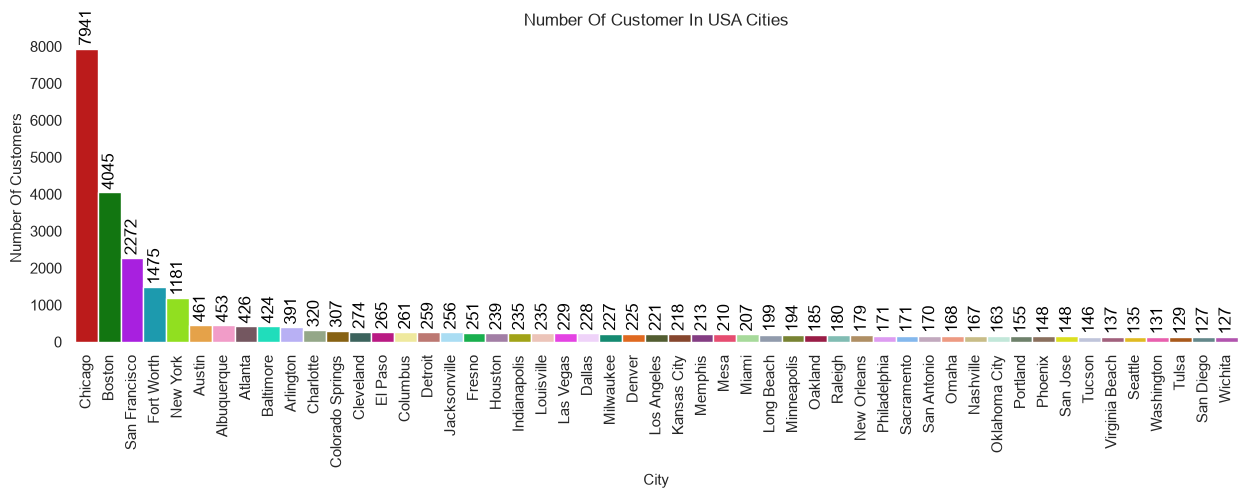

In [67]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=customer_count_usa, y = 'Customer_Count' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_light, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Number Of Customers", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.1d', color = 'Black', rotation = 90, fontsize = 12)
ax.set_title('Number Of Customer In USA Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [68]:
customer_count_canada = canada_data.groupby(['Country', 'City'],as_index=False, group_keys=False).agg(Customer_Count =('Customer_ID', 'nunique')).sort_values(by = 'Customer_Count', ascending = False)
customer_count_canada.style.set_properties(**{'background-color': 'white', 'color': 'green'}).hide(axis='index')

Country,City,Customer_Count
Canada,Edmonton,854
Canada,Calgary,854
Canada,Barrie,851
Canada,Halifax,800
Canada,Hamilton,763
Canada,Kitchener,744
Canada,Kelowna,692
Canada,London,689
Canada,Oshawa,638
Canada,Montreal,633


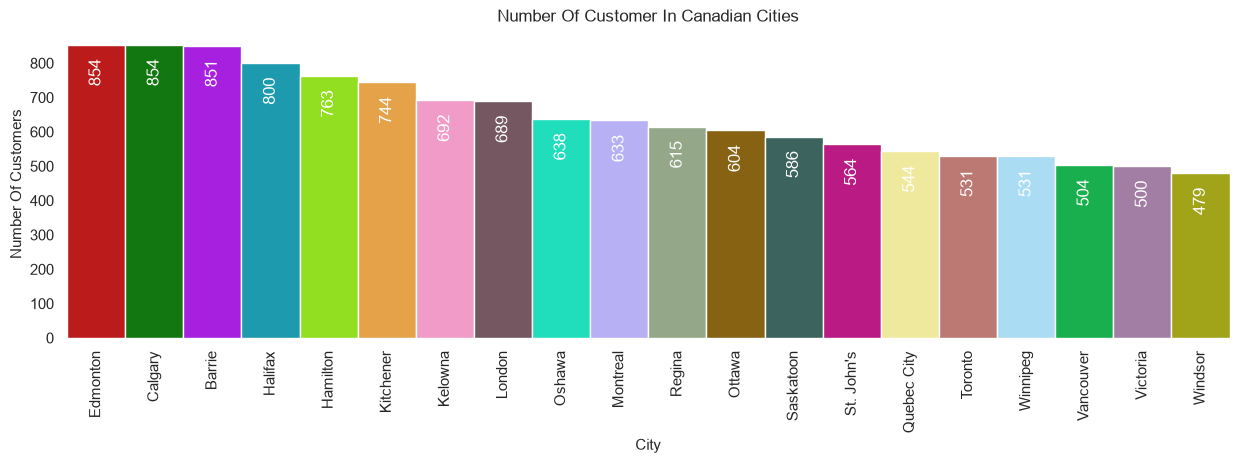

In [69]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=customer_count_canada, y = 'Customer_Count' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_light, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Number Of Customers", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-30, fmt='%.1d', color = 'white', rotation = 90, fontsize = 12)
ax.set_title('Number Of Customer In Canadian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [70]:
customer_count_uk = uk_data.groupby(['Country', 'City'],as_index=False, group_keys=False).agg(Customer_Count =('Customer_ID', 'nunique')).sort_values(by = 'Customer_Count', ascending = False)
customer_count_uk.style.set_properties(**{'background-color': 'white', 'color': 'green'}).hide(axis='index')

Country,City,Customer_Count
UK,Portsmouth,4844
UK,Birmingham,968
UK,Belfast,951
UK,Brighton,908
UK,Cardiff,831
UK,Glasgow,788
UK,Edinburgh,784
UK,Bristol,772
UK,Hull,751
UK,Leeds,712


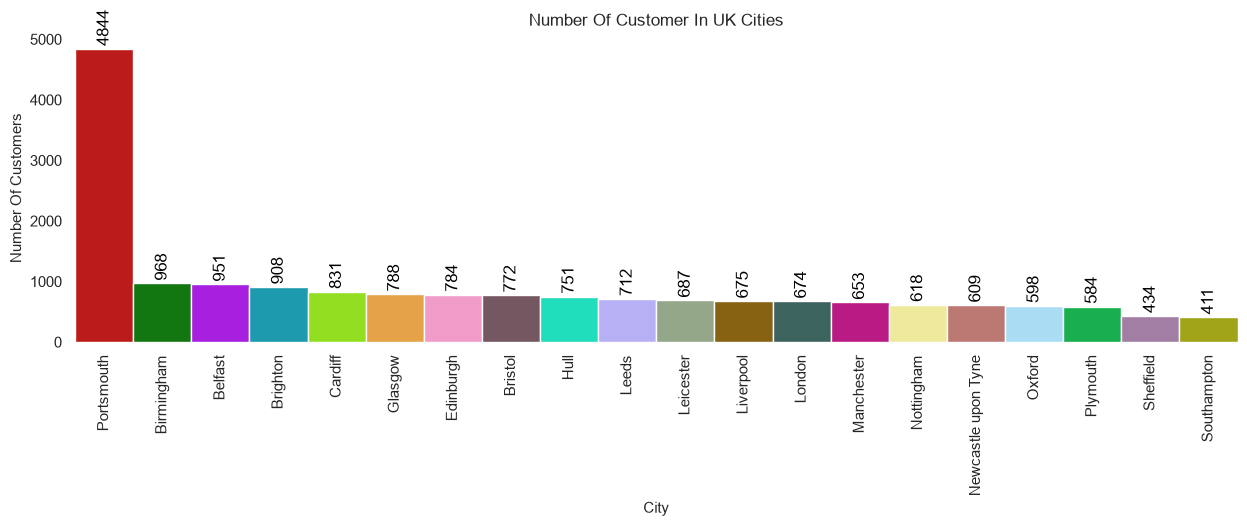

In [71]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=customer_count_uk, y = 'Customer_Count' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_light, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Number Of Customers", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.1d', color = 'Black', rotation = 90, fontsize = 12)
ax.set_title('Number Of Customer In UK Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [72]:
customer_count_germany = germany_data.groupby(['Country', 'City'],as_index=False, group_keys=False).agg(Customer_Count =('Customer_ID', 'nunique')).sort_values(by = 'Customer_Count', ascending = False)
customer_count_germany.style.set_properties(**{'background-color': 'white', 'color': 'green'}).hide(axis='index')

Country,City,Customer_Count
Germany,Frankfurt,2870
Germany,Bielefeld,897
Germany,Berlin,864
Germany,Bochum,825
Germany,Bremen,804
Germany,Dortmund,791
Germany,Cologne,778
Germany,Bonn,776
Germany,Dresden,694
Germany,Düsseldorf,683


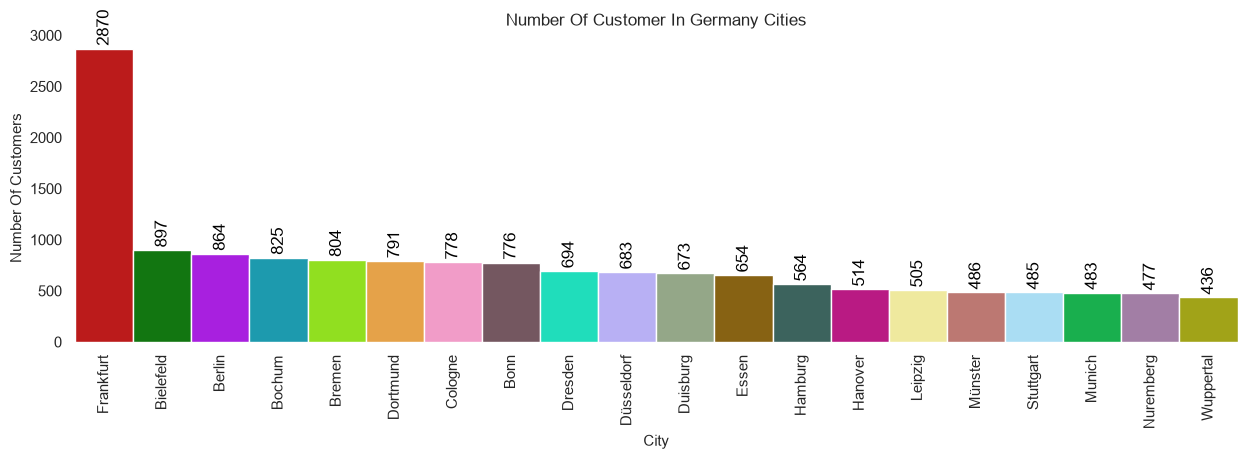

In [73]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=customer_count_germany, y = 'Customer_Count' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_light, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Number Of Customers", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.1d', color = 'black', rotation = 90, fontsize = 12)
ax.set_title('Number Of Customer In Germany Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [74]:
customer_count_australia = australia_data.groupby(['Country', 'City'],as_index=False, group_keys=False).agg(Customer_Count =('Customer_ID', 'nunique')).sort_values(by = 'Customer_Count', ascending = False)
customer_count_australia.style.set_properties(**{'background-color': 'white', 'color': 'green'}).hide(axis='index')

Country,City,Customer_Count
Australia,Albury,856
Australia,Adelaide,840
Australia,Ballarat,784
Australia,Bendigo,784
Australia,Brisbane,775
Australia,Cairns,734
Australia,Canberra,714
Australia,Geelong,699
Australia,Darwin,697
Australia,Mackay,642


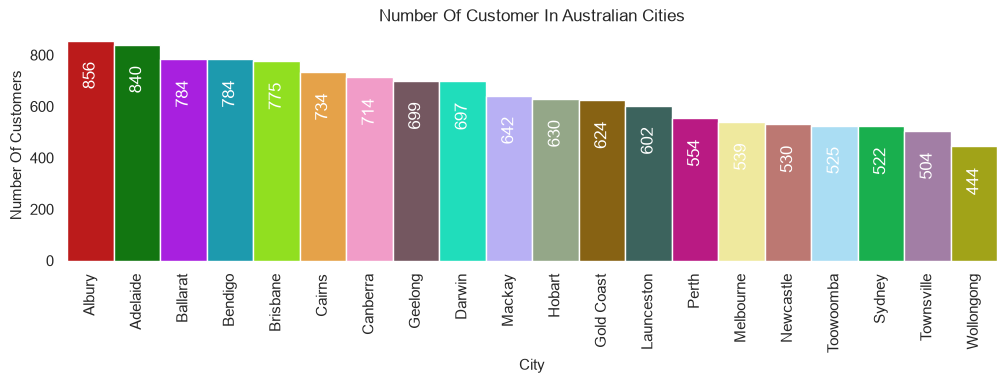

In [75]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (12, 3))
sns.barplot(data=customer_count_australia, y = 'Customer_Count' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_light, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Number Of Customers", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-35, fmt='%.1d', color = 'white', rotation = 90, fontsize = 12)
ax.set_title('Number Of Customer In Australian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

*2-Percentage Of Low Ratings In Each City By Country*

In [76]:
low = usa_data[(usa_data['Ratings'] == 1)| (usa_data['Ratings'] == 2)]
all_orders = usa_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
low_ratings_usa = pd.DataFrame(low.groupby(['Country','City'],as_index=False).agg(LowRatings=('Ratings', 'count')))
low_ratings_usa = pd.merge(low_ratings_usa, all_orders, how='inner')
low_ratings_usa['LowRatingsPercentage'] = 100 * (low_ratings_usa['LowRatings'] / low_ratings_usa['NumberOfOrders'])
low_ratings_usa = low_ratings_usa.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'LowRatingsPercentage')).sort_values(by = 'LowRatingsPercentage', ascending = False)
low_ratings_usa.style \
    .format({'LowRatingsPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


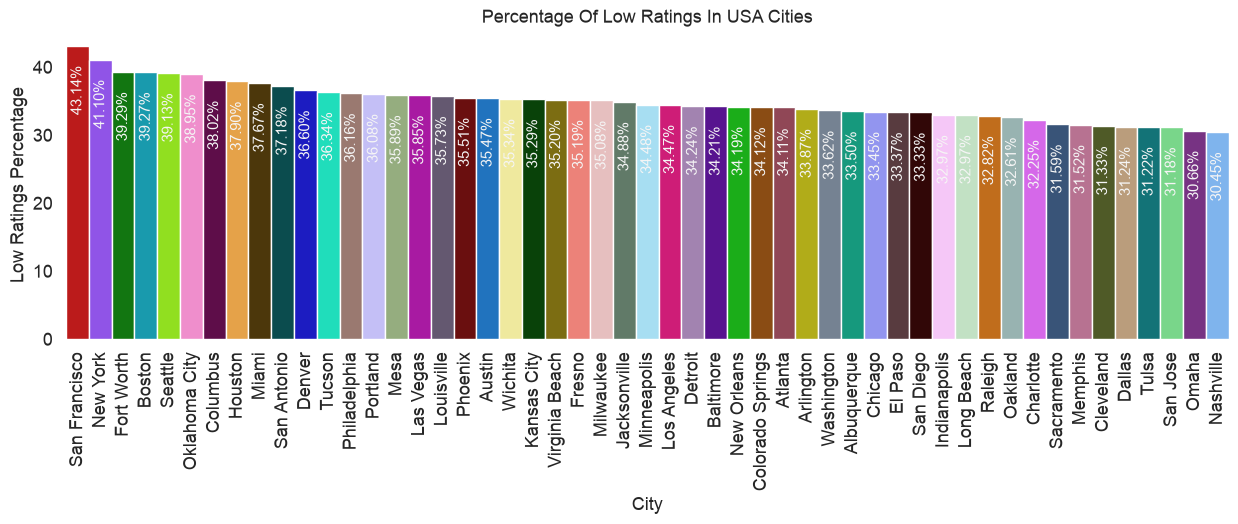

In [77]:
sns.set_theme(font_scale=1.2)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=low_ratings_usa, y = low_ratings_usa['LowRatingsPercentage'] , x='City', ax=ax, palette = sns.color_palette(cc.glasbey, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=13)
ax.set_ylabel("Low Ratings Percentage", fontsize=13)
for i in ax.containers:
    ax.bar_label(i,  padding=-50, fmt='%.2f%%', color = 'whitesmoke', rotation = 90, fontsize = 11, )
ax.set_title('Percentage Of Low Ratings In USA Cities', fontsize = 13)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [78]:
low = canada_data[(canada_data['Ratings'] == 1)| (canada_data['Ratings'] == 2)]
all_orders = canada_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
low_ratings_canada = pd.DataFrame(low.groupby(['Country','City'],as_index=False).agg(LowRatings=('Ratings', 'count')))
low_ratings_canada = pd.merge(low_ratings_canada, all_orders, how='inner')
low_ratings_canada['LowRatingsPercentage'] = 100 * (low_ratings_canada['LowRatings'] / low_ratings_canada['NumberOfOrders'])
low_ratings_canada = low_ratings_canada.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'LowRatingsPercentage')).sort_values(by = 'LowRatingsPercentage', ascending = False)
low_ratings_canada.style \
    .format({'LowRatingsPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


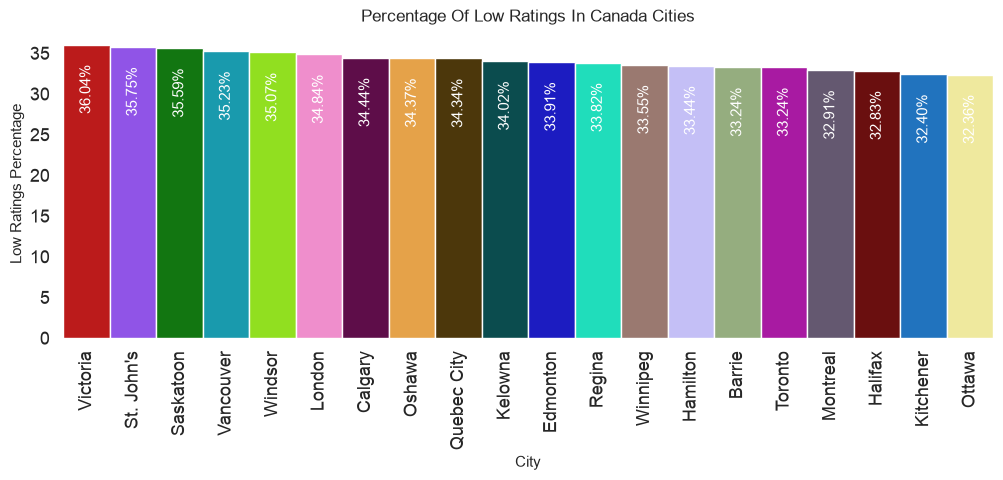

In [79]:
sns.set_theme(font_scale=1.2)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (12, 4))
sns.barplot(data=low_ratings_canada, y = low_ratings_canada['LowRatingsPercentage'] , x='City', ax=ax, palette = sns.color_palette(cc.glasbey, n_colors=20), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Low Ratings Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-50, fmt='%.2f%%', color = 'white', rotation = 90, fontsize = 11)
ax.set_title('Percentage Of Low Ratings In Canada Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [80]:
low = germany_data[(germany_data['Ratings'] == 1)| (germany_data['Ratings'] == 2)]
all_orders = germany_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
low_ratings_germany = pd.DataFrame(low.groupby(['Country','City'],as_index=False).agg(LowRatings=('Ratings', 'count')))
low_ratings_germany = pd.merge(low_ratings_germany, all_orders, how='inner')
low_ratings_germany['LowRatingsPercentage'] = 100 * (low_ratings_germany['LowRatings'] / low_ratings_germany['NumberOfOrders'])
low_ratings_germany = low_ratings_germany.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'LowRatingsPercentage')).sort_values(by = 'LowRatingsPercentage', ascending = False)
low_ratings_germany.style \
    .format({'LowRatingsPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


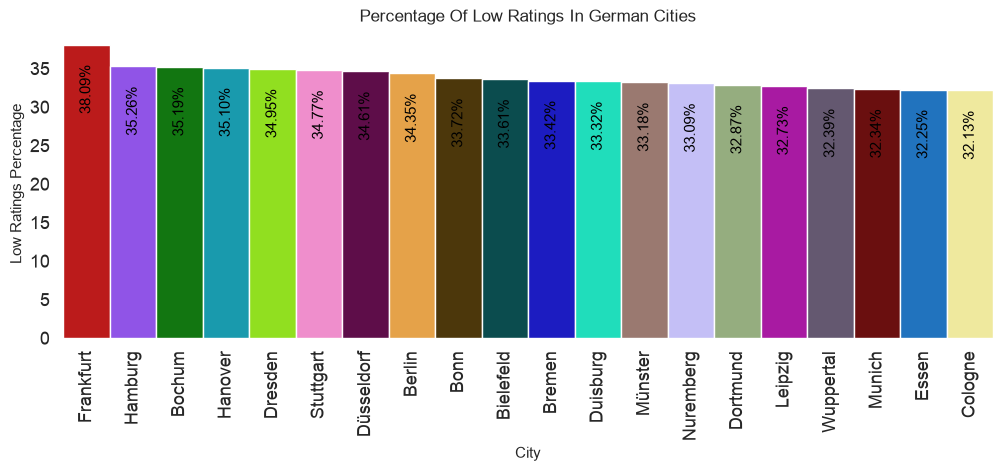

In [81]:
sns.set_theme(font_scale=1.2)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (12, 4))
sns.barplot(data=low_ratings_germany, y = low_ratings_germany['LowRatingsPercentage'] , x='City', ax=ax, palette = sns.color_palette(cc.glasbey, n_colors=20), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Low Ratings Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-50, fmt='%.2f%%', color = 'black', rotation = 90, fontsize = 11)
ax.set_title('Percentage Of Low Ratings In German Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [82]:
low = uk_data[(uk_data['Ratings'] == 1)| (uk_data['Ratings'] == 2)]
all_orders = uk_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
low_ratings_uk = pd.DataFrame(low.groupby(['Country','City'],as_index=False).agg(LowRatings=('Ratings', 'count')))
low_ratings_uk = pd.merge(low_ratings_uk, all_orders, how='inner')
low_ratings_uk['LowRatingsPercentage'] = 100 * (low_ratings_uk['LowRatings'] / low_ratings_uk['NumberOfOrders'])
low_ratings_uk = low_ratings_uk.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'LowRatingsPercentage')).sort_values(by = 'LowRatingsPercentage', ascending = False)
low_ratings_uk.style \
    .format({'LowRatingsPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


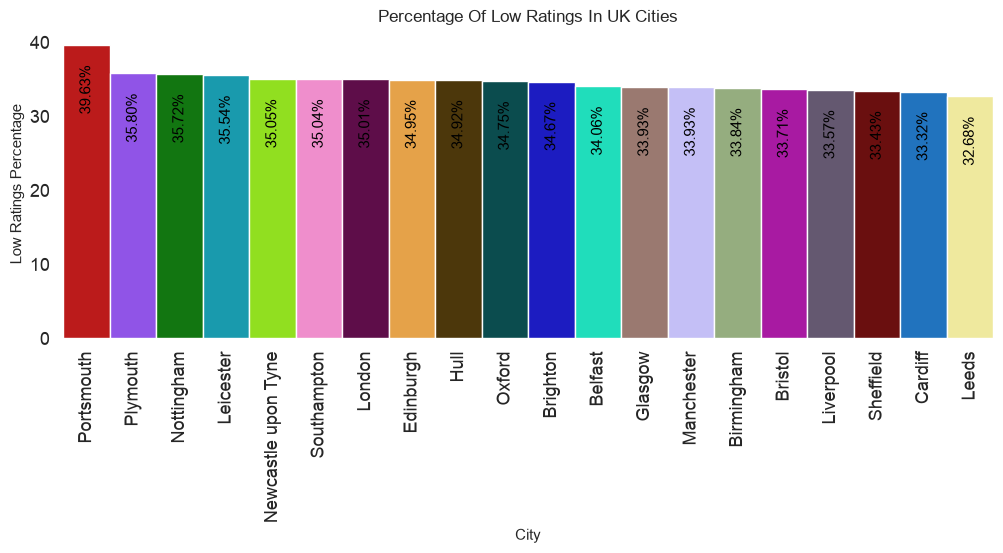

In [83]:
sns.set_theme(font_scale=1.2)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (12, 4))
sns.barplot(data=low_ratings_uk, y = low_ratings_uk['LowRatingsPercentage'] , x='City', ax=ax, palette = sns.color_palette(cc.glasbey, n_colors=20), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Low Ratings Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-50, fmt='%.2f%%', color = 'black', rotation = 90, fontsize = 11)
ax.set_title('Percentage Of Low Ratings In UK Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [84]:
low = australia_data[(australia_data['Ratings'] == 1)| (australia_data['Ratings'] == 2)]
all_orders = australia_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
low_ratings_australia = pd.DataFrame(low.groupby(['Country','City'],as_index=False).agg(LowRatings=('Ratings', 'count')))
low_ratings_australia = pd.merge(low_ratings_australia, all_orders, how='inner')
low_ratings_australia['LowRatingsPercentage'] = 100 * (low_ratings_australia['LowRatings'] / low_ratings_australia['NumberOfOrders'])
low_ratings_australia = low_ratings_australia.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'LowRatingsPercentage')).sort_values(by = 'LowRatingsPercentage', ascending = False)
low_ratings_australia.style \
    .format({'LowRatingsPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


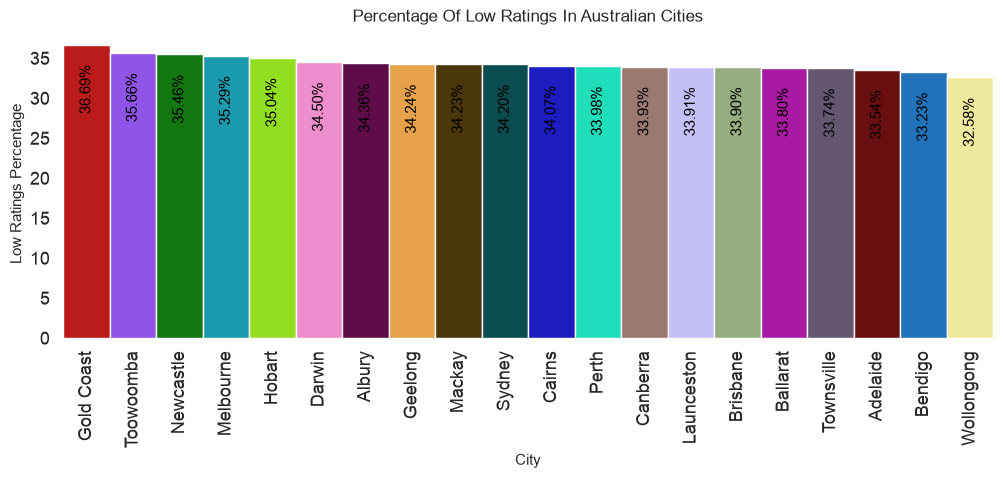

In [85]:
sns.set_theme(font_scale=1.2)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (12, 4))
sns.barplot(data=low_ratings_australia, y = low_ratings_australia['LowRatingsPercentage'] , x='City', ax=ax, palette = sns.color_palette(cc.glasbey, n_colors=20), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Low Ratings Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-50, fmt='%.2f%%', color = 'black', rotation = 90, fontsize = 11)
ax.set_title('Percentage Of Low Ratings In Australian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

*3-Percentage Of Pending Orderss In Each City By Country*

In [86]:
order_pending = usa_data[(usa_data['Order_Status'] == 'Pending')]
all_orders = usa_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
pending_orders_usa = pd.DataFrame(order_pending.groupby(['Country','City'],as_index=False).agg(PendingOrders=('Order_Status', 'count')))
pending_orders_usa = pd.merge(pending_orders_usa, all_orders, how='inner')
pending_orders_usa['PendingOrdersPercentage'] = 100 * (pending_orders_usa['PendingOrders'] / pending_orders_usa['NumberOfOrders'])
pending_orders_usa = pending_orders_usa.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'PendingOrdersPercentage')).sort_values(by = 'PendingOrdersPercentage', ascending = False)
pending_orders_usa.style \
    .format({'PendingOrdersPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})

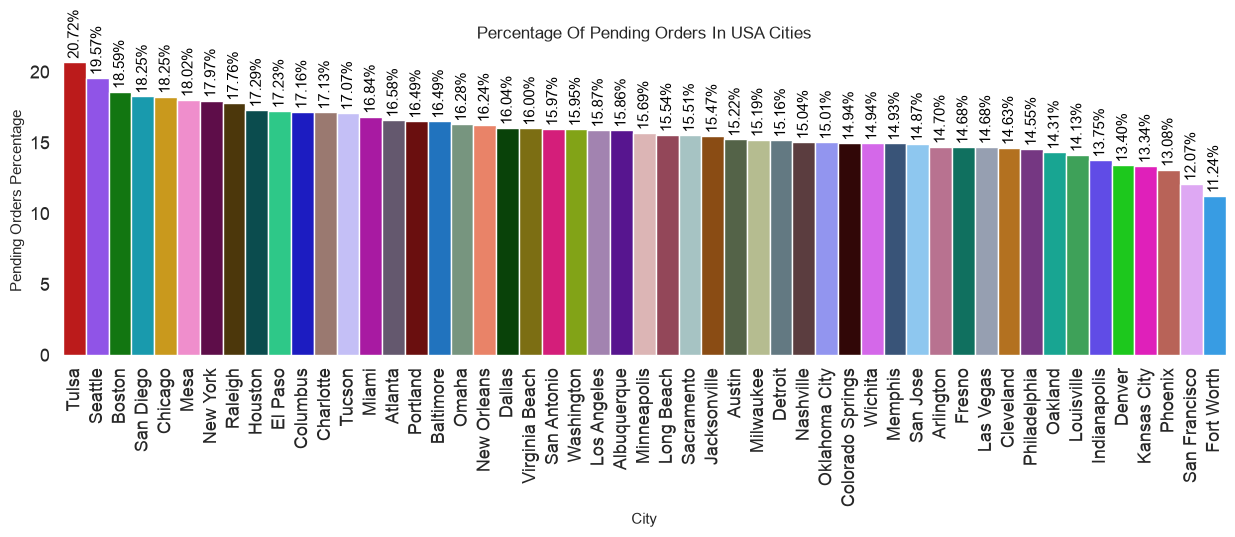

In [87]:
sns.set_theme(font_scale=1.2)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=pending_orders_usa, y = 'PendingOrdersPercentage' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_dark, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Pending Orders Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.2f%%', color = 'black', rotation = 90, fontsize = 11)
ax.set_title('Percentage Of Pending Orders In USA Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [88]:
order_pending = canada_data[(canada_data['Order_Status'] == 'Pending')]
all_orders = canada_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
pending_orders_canada = pd.DataFrame(order_pending.groupby(['Country','City'],as_index=False).agg(PendingOrders=('Order_Status', 'count')))
pending_orders_canada = pd.merge(pending_orders_canada, all_orders, how='inner')
pending_orders_canada['PendingOrdersPercentage'] = 100 * (pending_orders_canada['PendingOrders'] / pending_orders_canada['NumberOfOrders'])
pending_orders_canada = pending_orders_canada.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'PendingOrdersPercentage')).sort_values(by = 'PendingOrdersPercentage', ascending = False)
pending_orders_canada.style \
    .format({'PendingOrdersPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


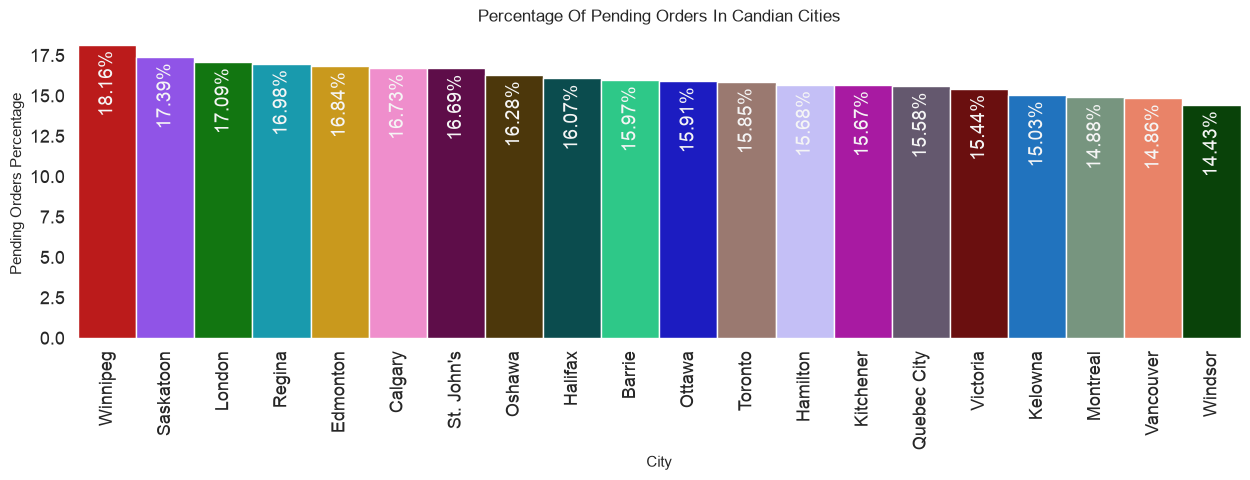

In [89]:
sns.set_theme(font_scale=1.2)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=pending_orders_canada, y = 'PendingOrdersPercentage' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_dark, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Pending Orders Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-52, fmt='%.2f%%', color = 'whitesmoke', rotation = 90, fontsize = 14)
ax.set_title('Percentage Of Pending Orders In Candian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [90]:
order_pending = germany_data[(germany_data['Order_Status'] == 'Pending')]
all_orders = germany_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
pending_orders_germany = pd.DataFrame(order_pending.groupby(['Country','City'],as_index=False).agg(PendingOrders=('Order_Status', 'count')))
pending_orders_germany = pd.merge(pending_orders_germany, all_orders, how='inner')
pending_orders_germany['PendingOrdersPercentage'] = 100 * (pending_orders_germany['PendingOrders'] / pending_orders_germany['NumberOfOrders'])
pending_orders_germany = pending_orders_germany.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'PendingOrdersPercentage')).sort_values(by = 'PendingOrdersPercentage', ascending = False)
pending_orders_germany.style \
    .format({'PendingOrdersPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


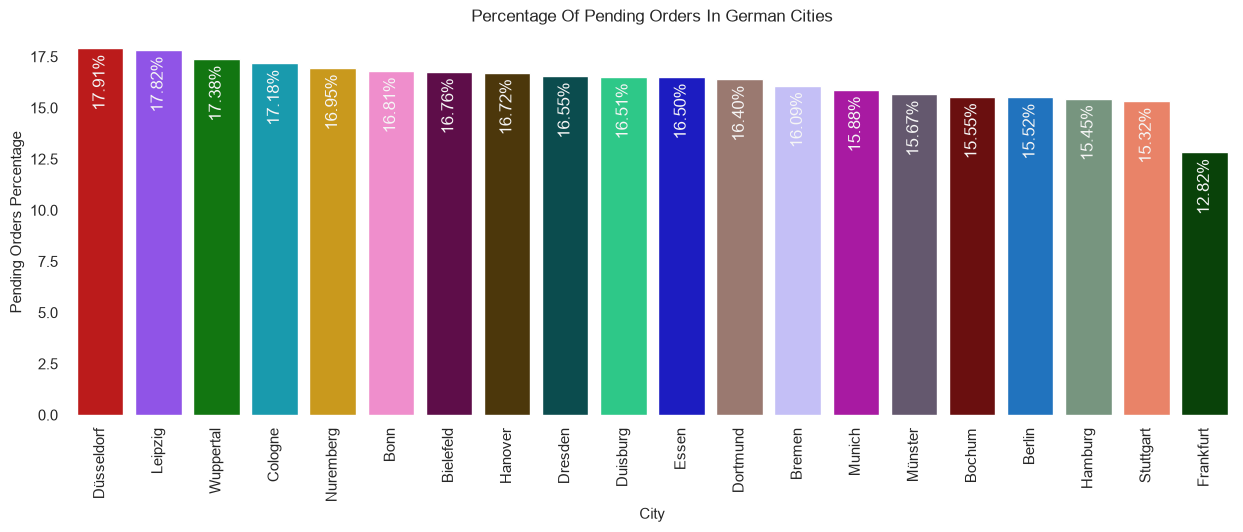

In [91]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 5))
sns.barplot(data=pending_orders_germany, y = 'PendingOrdersPercentage' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_dark, n_colors=20), width=0.8)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Pending Orders Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-45, fmt='%.2f%%', color = 'whitesmoke', rotation = 90, fontsize = 12)
ax.set_title('Percentage Of Pending Orders In German Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [92]:
order_pending = uk_data[(uk_data['Order_Status'] == 'Pending')]
all_orders = uk_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
pending_orders_uk = pd.DataFrame(order_pending.groupby(['Country','City'],as_index=False).agg(PendingOrders=('Order_Status', 'count')))
pending_orders_uk = pd.merge(pending_orders_uk, all_orders, how='inner')
pending_orders_uk['PendingOrdersPercentage'] = 100 * (pending_orders_uk['PendingOrders'] / pending_orders_uk['NumberOfOrders'])
pending_orders_uk = pending_orders_uk.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'PendingOrdersPercentage')).sort_values(by = 'PendingOrdersPercentage', ascending = False)
pending_orders_uk.style \
    .format({'PendingOrdersPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


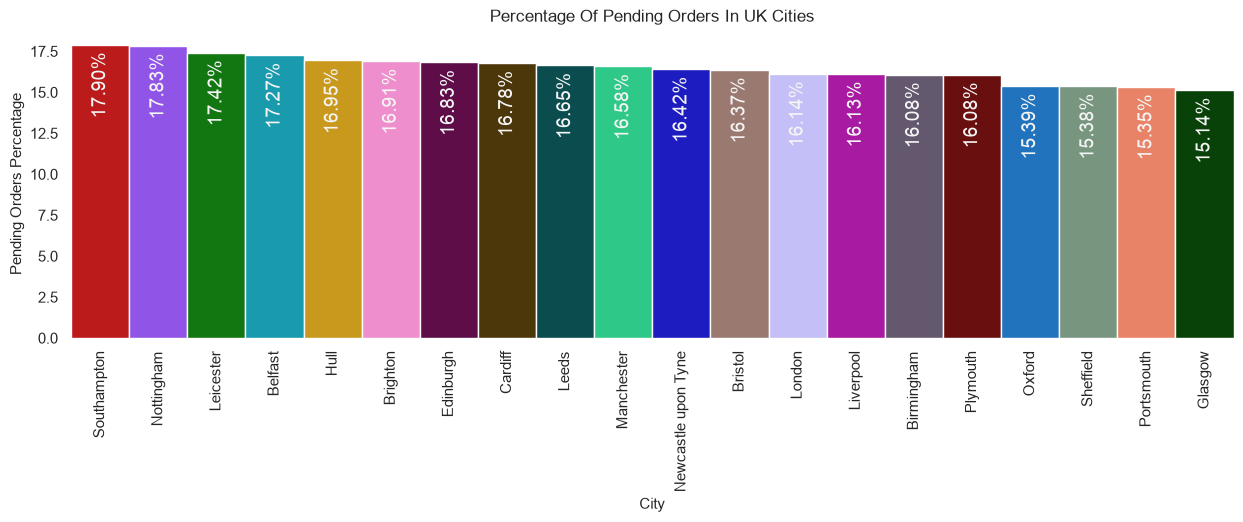

In [93]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=pending_orders_uk, y = 'PendingOrdersPercentage' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_dark, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Pending Orders Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-53, fmt='%.2f%%', color = 'whitesmoke', rotation = 90, fontsize = 14)
ax.set_title('Percentage Of Pending Orders In UK Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [94]:
order_pending = australia_data[(australia_data['Order_Status'] == 'Pending')]
all_orders = australia_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
pending_orders_australia = pd.DataFrame(order_pending.groupby(['Country','City'],as_index=False).agg(PendingOrders=('Order_Status', 'count')))
pending_orders_australia = pd.merge(pending_orders_australia, all_orders, how='inner')
pending_orders_australia['PendingOrdersPercentage'] = 100 * (pending_orders_australia['PendingOrders'] / pending_orders_australia['NumberOfOrders'])
pending_orders_australia = pending_orders_australia.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'PendingOrdersPercentage')).sort_values(by = 'PendingOrdersPercentage', ascending = False)
pending_orders_australia.style \
    .format({'PendingOrdersPercentage': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})


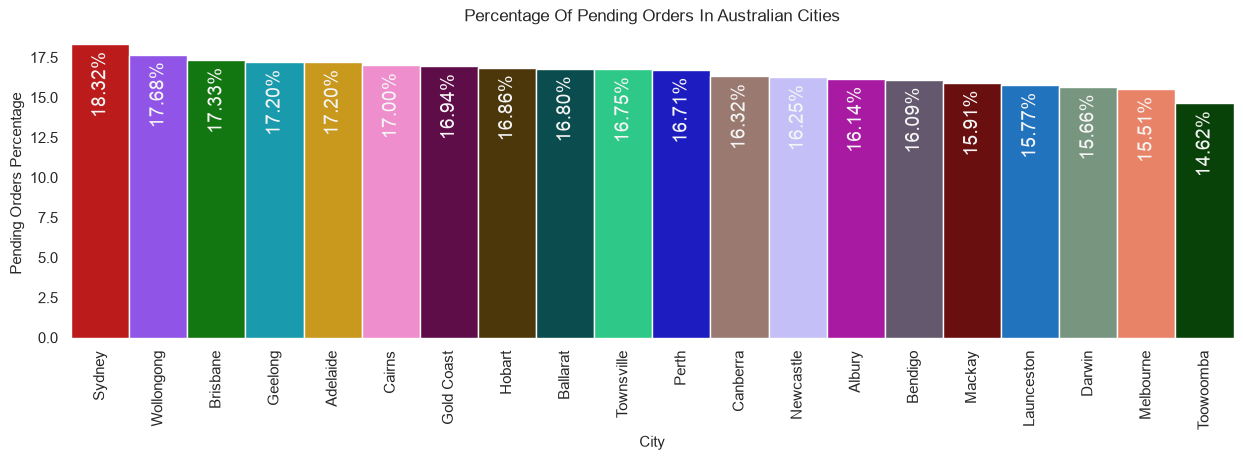

In [95]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=pending_orders_australia, y = 'PendingOrdersPercentage' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_dark, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Pending Orders Percentage", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-53, fmt='%.2f%%', color = 'whitesmoke', rotation = 90, fontsize = 14)
ax.set_title('Percentage Of Pending Orders In Australian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

*4-Preferred Day In Each City By Country*

In [96]:
all_orders = usa_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
preferred_day_usa = pd.DataFrame(usa_data.groupby(['Country','City', 'Day'],as_index=False).agg(DayOrders=('Customer_ID', 'count')))
preferred_day_usa = pd.merge(preferred_day_usa, all_orders, how='inner')
preferred_day_usa['DayOrdersPercentage'] = 100 * (preferred_day_usa['DayOrders'] / preferred_day_usa['NumberOfOrders'])
preferred_day_usa = preferred_day_usa.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'DayOrdersPercentage')).sort_values(by = 'Day', ascending = False)
preferred_day_usa.style \
     .format({'DayOrdersPercentage': "{:.2f}"}) \
     .set_properties(**{'background-color': 'white', 'color': 'green'})


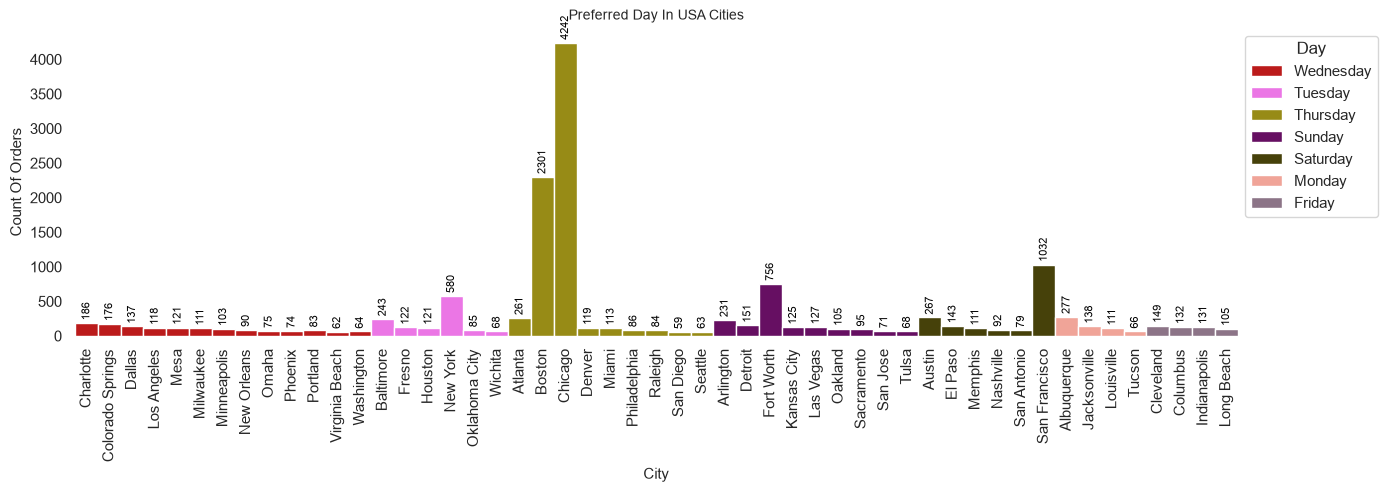

In [97]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=preferred_day_usa, y = 'DayOrders' , x='City', hue='Day' ,ax=ax, palette = sns.color_palette(cc.glasbey_warm, n_colors=7), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Count Of Orders", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.2d', color = 'black', rotation = 90, fontsize = 8)
ax.set_title('Preferred Day In USA Cities', fontsize = 10)
ax.tick_params(axis='x', labelrotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [98]:
all_orders = canada_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
preferred_day_canada = pd.DataFrame(canada_data.groupby(['Country','City', 'Day'],as_index=False).agg(DayOrders=('Customer_ID', 'count')))
preferred_day_canada = pd.merge(preferred_day_canada, all_orders, how='inner')
preferred_day_canada['DayOrdersPercentage'] = 100 * (preferred_day_canada['DayOrders'] / preferred_day_canada['NumberOfOrders'])
preferred_day_canada = preferred_day_canada.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'DayOrdersPercentage')).sort_values(by = 'Day', ascending = False)
preferred_day_canada.style \
     .format({'DayOrdersPercentage': "{:.2f}"}) \
     .set_properties(**{'background-color': 'white', 'color': 'green'})


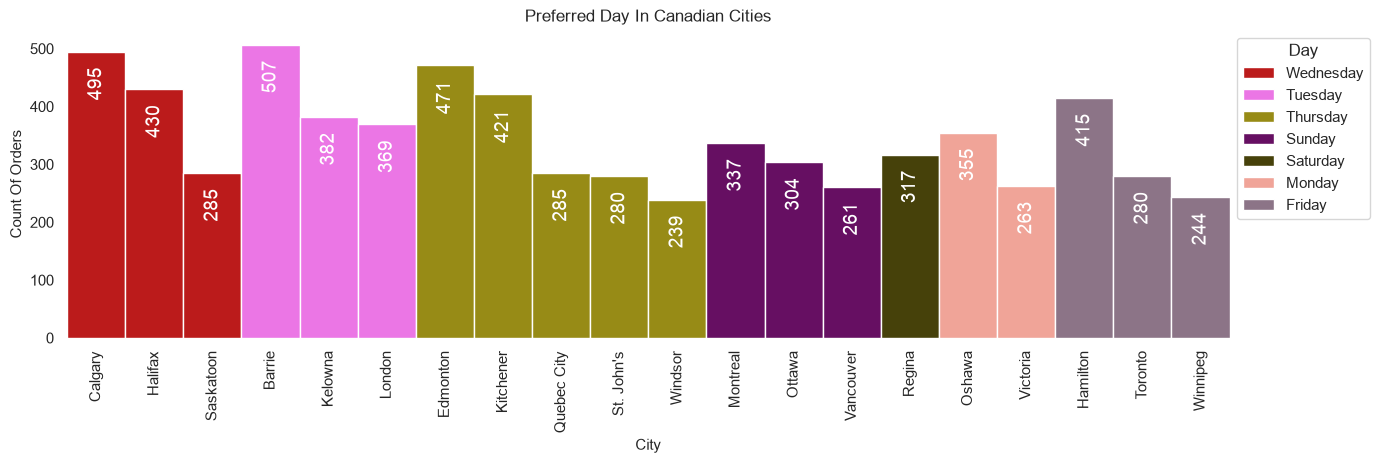

In [99]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=preferred_day_canada, y = 'DayOrders' , x='City', hue='Day' ,ax=ax, palette = sns.color_palette(cc.glasbey_warm, n_colors=7), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Count Of Orders", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-35, fmt='%.2d', color = 'white', rotation = 90, fontsize = 14)
ax.set_title('Preferred Day In Canadian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [100]:
all_orders = germany_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
preferred_day_germany = pd.DataFrame(germany_data.groupby(['Country','City', 'Day'],as_index=False).agg(DayOrders=('Customer_ID', 'count')))
preferred_day_germany = pd.merge(preferred_day_germany, all_orders, how='inner')
preferred_day_germany['DayOrdersPercentage'] = 100 * (preferred_day_germany['DayOrders'] / preferred_day_germany['NumberOfOrders'])
preferred_day_germany = preferred_day_germany.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'DayOrdersPercentage')).sort_values(by = 'Day', ascending = False)
preferred_day_germany.style \
     .format({'DayOrdersPercentage': "{:.2f}"}) \
     .set_properties(**{'background-color': 'white', 'color': 'green'})


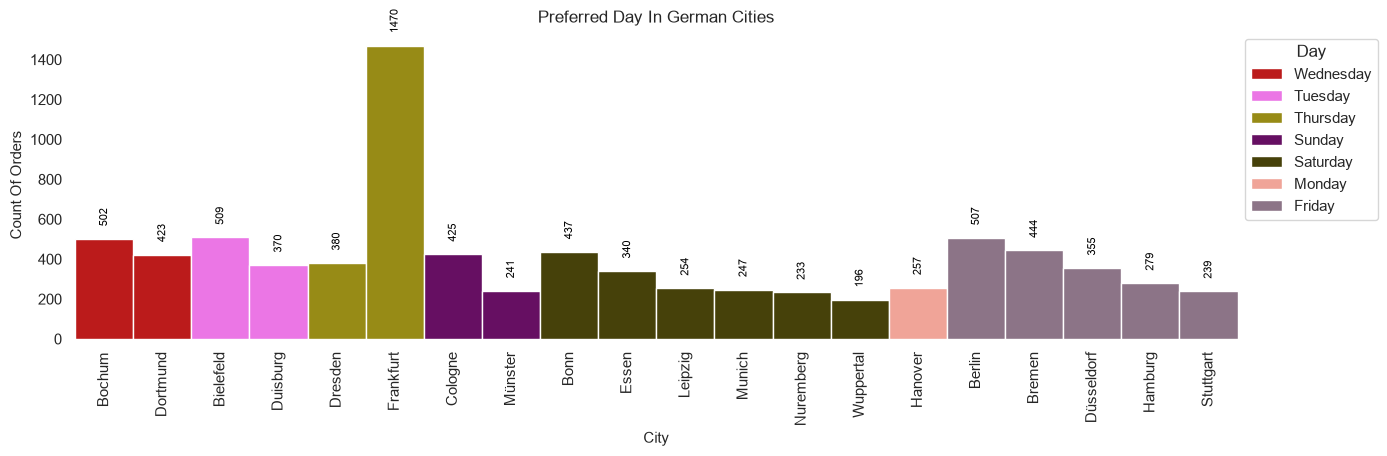

In [101]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=preferred_day_germany, y = 'DayOrders' , x='City', hue='Day' ,ax=ax, palette = sns.color_palette(cc.glasbey_warm, n_colors=7), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Count Of Orders", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=9, fmt='%.2d', color = 'black', rotation = 90, fontsize = 8)
ax.set_title('Preferred Day In German Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [102]:
all_orders = uk_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
preferred_day_uk = pd.DataFrame(uk_data.groupby(['Country','City', 'Day'],as_index=False).agg(DayOrders=('Customer_ID', 'count')))
preferred_day_uk = pd.merge(preferred_day_uk, all_orders, how='inner')
preferred_day_uk['DayOrdersPercentage'] = 100 * (preferred_day_uk['DayOrders'] / preferred_day_uk['NumberOfOrders'])
preferred_day_uk = preferred_day_uk.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'DayOrdersPercentage')).sort_values(by = 'Day', ascending = False)
preferred_day_uk.style \
     .format({'DayOrdersPercentage': "{:.2f}"}) \
     .set_properties(**{'background-color': 'white', 'color': 'green'})


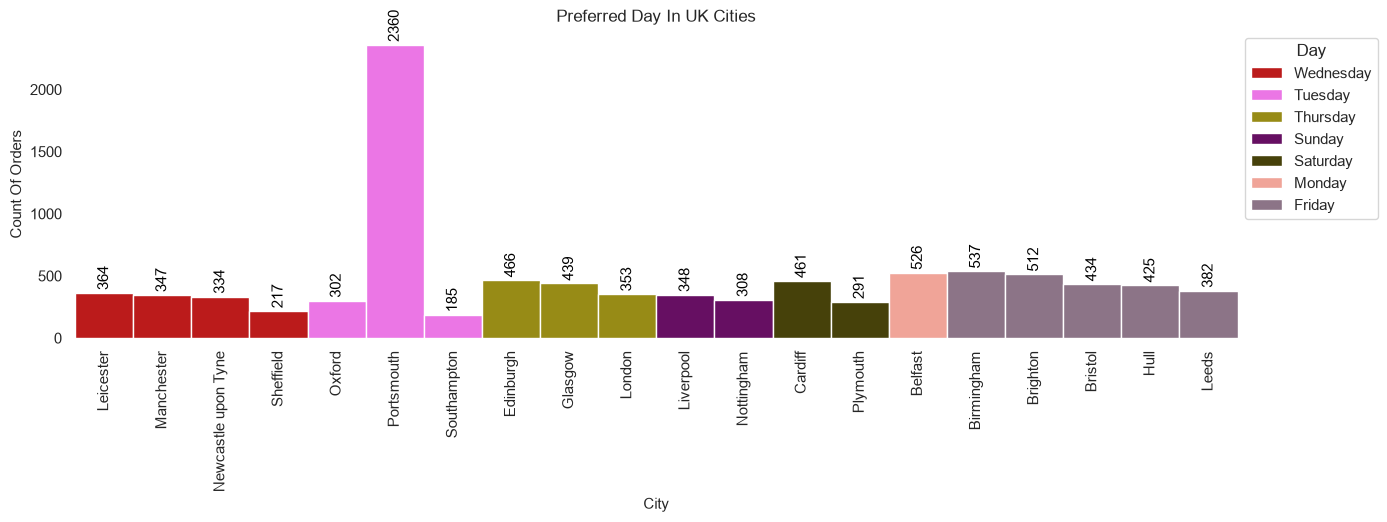

In [103]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=preferred_day_uk, y = 'DayOrders' , x='City', hue='Day' ,ax=ax, palette = sns.color_palette(cc.glasbey_warm, n_colors=7), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Count Of Orders", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.2d', color = 'black', rotation = 90, fontsize = 11)
ax.set_title('Preferred Day In UK Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [104]:
all_orders = australia_data.groupby(['Country','City'],as_index=False, group_keys=False).agg(NumberOfOrders = ('Customer_ID','count'))
preferred_day_australia = pd.DataFrame(australia_data.groupby(['Country','City', 'Day'],as_index=False).agg(DayOrders=('Customer_ID', 'count')))
preferred_day_australia = pd.merge(preferred_day_australia, all_orders, how='inner')
preferred_day_australia['DayOrdersPercentage'] = 100 * (preferred_day_australia['DayOrders'] / preferred_day_australia['NumberOfOrders'])
preferred_day_australia = preferred_day_australia.groupby(['Country', 'City']).apply(lambda x:x.nlargest(1 , 'DayOrdersPercentage')).sort_values(by = 'Day', ascending = False)
preferred_day_australia.style \
     .format({'DayOrdersPercentage': "{:.2f}"}) \
     .set_properties(**{'background-color': 'white', 'color': 'green'})


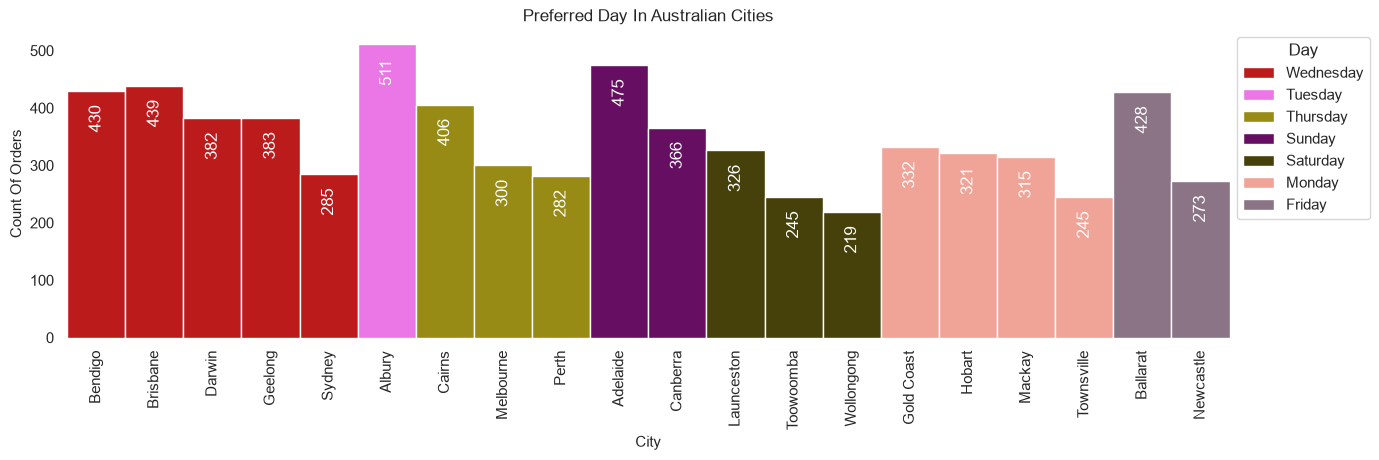

In [105]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=preferred_day_australia, y = 'DayOrders' , x='City', hue='Day' ,ax=ax, palette = sns.color_palette(cc.glasbey_warm, n_colors=7), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Count Of Orders", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-30, fmt='%.2d', color = 'white', rotation = 90, fontsize = 12)
ax.set_title('Preferred Day In Australian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

*5-Total Amount Of Each City By Country*

In [106]:
total_amount_usa = usa_data.groupby(['Country', 'City']).agg(TotalAmount =('Total_Amount', 'sum')).sort_values(by = 'TotalAmount', ascending = False)
total_amount_usa['TotalAmount'] = total_amount_usa['TotalAmount'].astype(int)
total_amount_usa.style.set_properties(**{'background-color': 'white', 'color': 'green'})

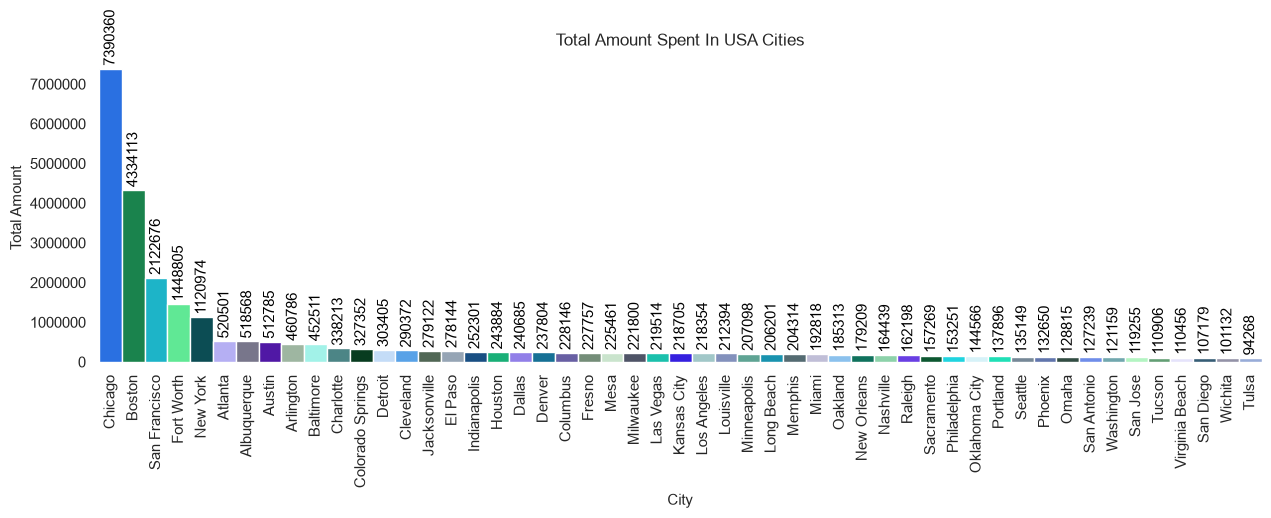

In [107]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=total_amount_usa, y = 'TotalAmount' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_cool, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Total Amount", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.1d', color = 'Black', rotation = 90, fontsize = 11)
ax.set_title('Total Amount Spent In USA Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [108]:
total_amount_canada = canada_data.groupby(['Country', 'City']).agg(TotalAmount =('Total_Amount', 'sum')).sort_values(by = 'TotalAmount', ascending = False)
total_amount_canada['TotalAmount'] = total_amount_canada['TotalAmount'].astype(int)
total_amount_canada.style.set_properties(**{'background-color': 'white', 'color': 'green'})

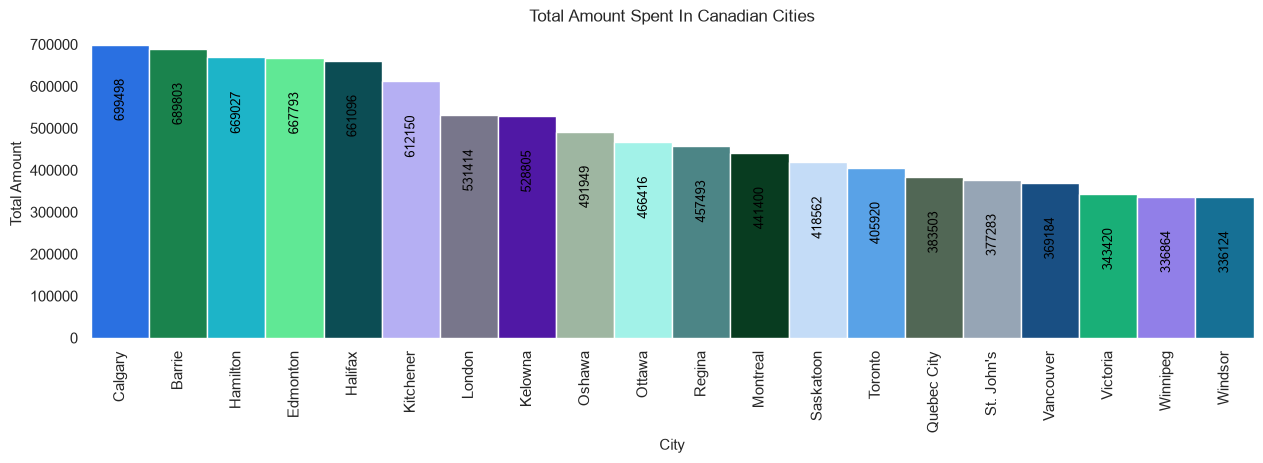

In [109]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=total_amount_canada, y = 'TotalAmount' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_cool, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Total Amount", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-55, fmt='%.1d', color = 'black', rotation = 90, fontsize = 9)
ax.set_title('Total Amount Spent In Canadian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [110]:
total_amount_germany = germany_data.groupby(['Country', 'City']).agg(TotalAmount =('Total_Amount', 'sum')).sort_values(by = 'TotalAmount', ascending = False)
total_amount_germany['TotalAmount'] = total_amount_germany['TotalAmount'].astype(int)
total_amount_germany.style.set_properties(**{'background-color': 'white', 'color': 'green'})

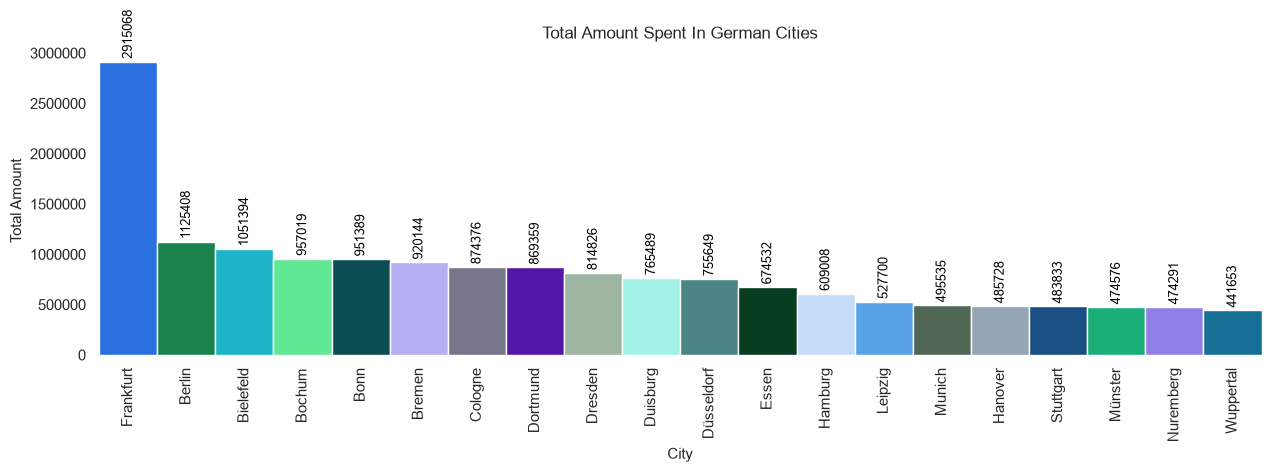

In [111]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=total_amount_germany, y = 'TotalAmount' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_cool, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Total Amount", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.1d', color = 'black', rotation = 90, fontsize = 9)
ax.set_title('Total Amount Spent In German Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [112]:
total_amount_uk = uk_data.groupby(['Country', 'City']).agg(TotalAmount =('Total_Amount', 'sum')).sort_values(by = 'TotalAmount', ascending = False)
total_amount_uk['TotalAmount'] = total_amount_uk['TotalAmount'].astype(int)
total_amount_uk.style.set_properties(**{'background-color': 'white', 'color': 'green'})

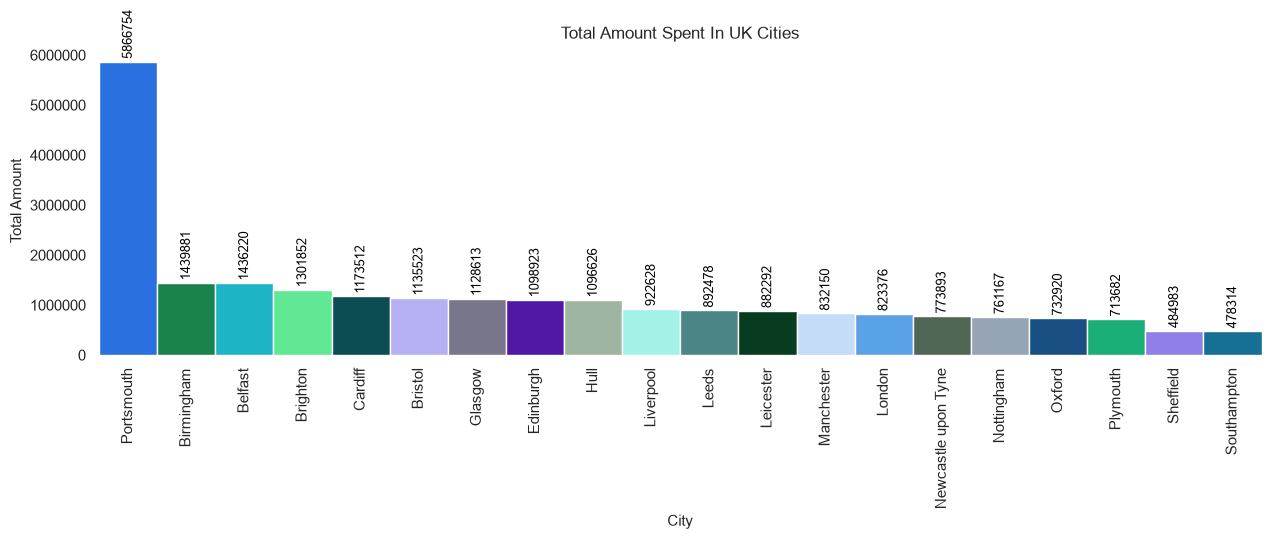

In [113]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=total_amount_uk, y = 'TotalAmount' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_cool, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Total Amount", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.1d', color = 'black', rotation = 90, fontsize = 9)
ax.set_title('Total Amount Spent In UK Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

In [114]:
total_amount_australia = australia_data.groupby(['Country', 'City']).agg(TotalAmount =('Total_Amount', 'sum')).sort_values(by = 'TotalAmount', ascending = False)
total_amount_australia['TotalAmount'] = total_amount_australia['TotalAmount'].astype(int)
total_amount_australia.style.set_properties(**{'background-color': 'white', 'color': 'green'})

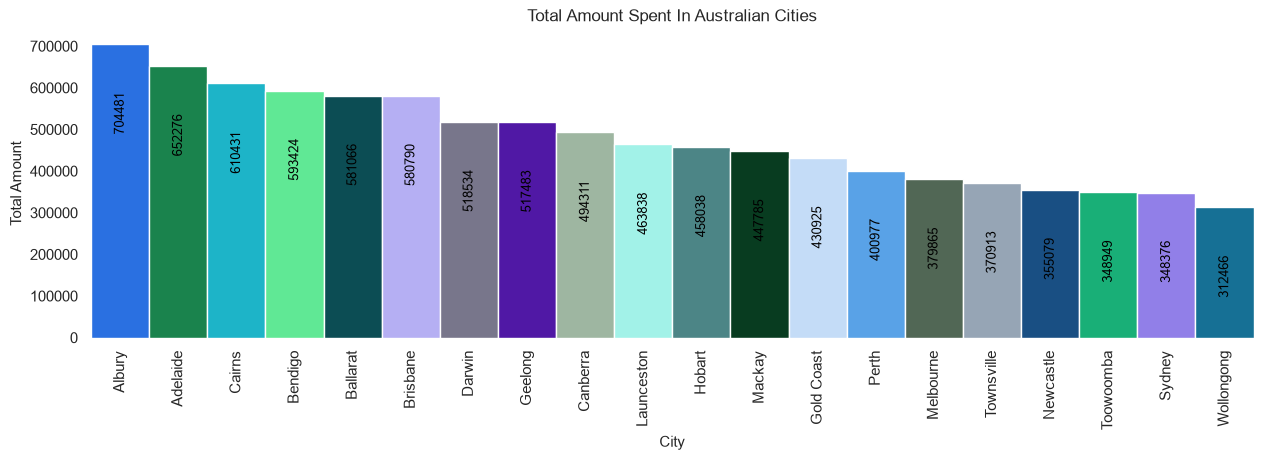

In [115]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=total_amount_australia, y = 'TotalAmount' , x='City', ax=ax, palette = sns.color_palette(cc.glasbey_cool, n_colors=51), width=1)
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel("Total Amount", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=-65, fmt='%.1d', color = 'black', rotation = 90, fontsize = 9)
ax.set_title('Total Amount Spent In Australian Cities', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.despine(bottom = True, left = True);

*6-Gender Total Amount, Total Orders, Total Quantity By Country*

In [116]:
gender_total = clean_df.groupby(['Country', 'Gender']).agg(TotalAmount = ('Total_Amount','sum'), TotalOrders  = ('Customer_ID','count'), TotalQuantity  = ('Quantity','sum')).sort_values(by = 'Country', ascending = True)
gender_total['TotalAmount'] = gender_total['TotalAmount'].astype(int)
gender_total.style.set_properties(**{'background-color': 'white', 'color': 'green'})

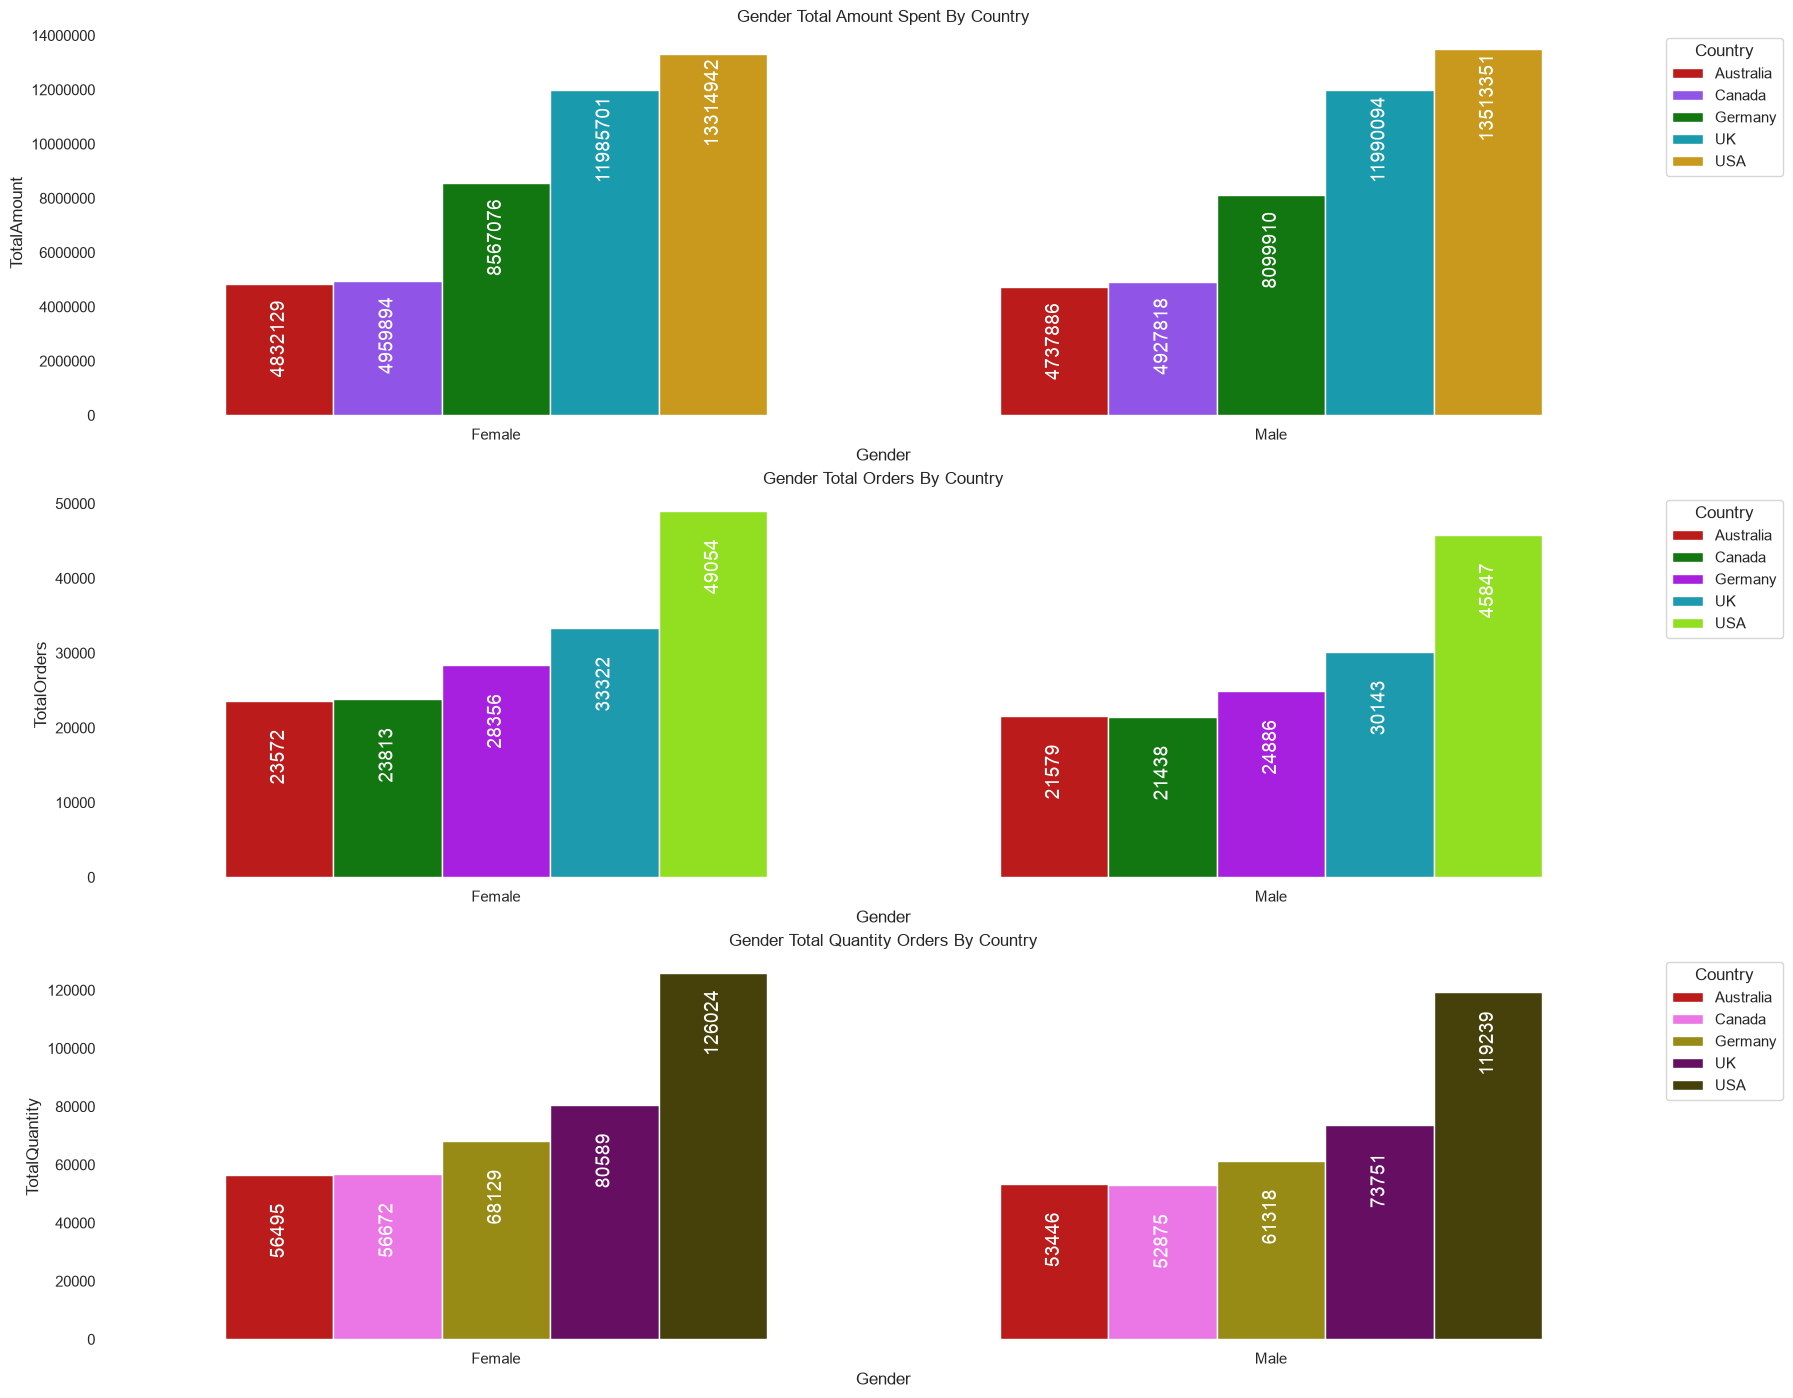

In [117]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, (ax1, ax2, ax3) = plt.subplots(ncols=1, nrows = 3, figsize = (20, 17))
sns.barplot(data=gender_total, x = 'Gender' , y='TotalAmount',   hue='Country', ax=ax1, palette = sns.color_palette(cc.glasbey_dark, n_colors=5), width=0.7)
sns.barplot(data=gender_total, x = 'Gender' , y='TotalOrders',   hue='Country', ax=ax2, palette = sns.color_palette(cc.glasbey_light, n_colors=5), width=0.7)
sns.barplot(data=gender_total, x = 'Gender' , y='TotalQuantity', hue='Country', ax=ax3, palette = sns.color_palette(cc.glasbey_warm, n_colors=5), width=0.7)

for i in ax1.containers:
    ax1.bar_label(i,  padding=-67, fmt='%.1d', color = 'white', rotation = 90, fontsize = 14)
for i in ax2.containers:
    ax2.bar_label(i,  padding=-60, fmt='%.1d', color = 'white', rotation = 90, fontsize = 14)
for i in ax3.containers:
    ax3.bar_label(i,  padding=-60, fmt='%.1d', color = 'white', rotation = 90, fontsize = 14)

ax1.set_title('Gender Total Amount Spent By Country', fontsize = 12)
ax2.set_title('Gender Total Orders By Country', fontsize = 12)
ax3.set_title('Gender Total Quantity Orders By Country', fontsize = 12)

ax1.ticklabel_format(style='plain', axis='y')
sns.move_legend(ax1, "upper left", bbox_to_anchor=(1, 1))
sns.move_legend(ax2, "upper left", bbox_to_anchor=(1, 1))
sns.move_legend(ax3, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True);

*7-Number Of Return Customer By Customer Segment By Country*

In [118]:
all_customer = clean_df.groupby(['Country', 'Customer_Segment'], as_index=False).agg(AllCustomer=('Customer_ID', 'nunique'))
number_of_orders = clean_df.groupby(['Country', 'Customer_ID', 'Customer_Segment', 'City'], as_index=False).agg(NumberOfOrders=('Customer_ID', 'count'))
number_of_orders = number_of_orders[number_of_orders['NumberOfOrders'] > 1]
number_of_return_customer = number_of_orders.groupby(['Country', 'Customer_Segment'], as_index=False).agg(NumberOfReturnCustomer=('Customer_ID', 'count'))
number_of_return_customer = pd.merge(number_of_return_customer, all_customer, how='outer')
number_of_return_customer['Return_Rate'] = number_of_return_customer['NumberOfReturnCustomer'] / number_of_return_customer['AllCustomer'] * 100
number_of_return_customer.style \
    .format({'Return_Rate': "{:.2f}"}) \
    .set_properties(**{'background-color': 'white', 'color': 'green'})

,Country,Customer_Segment,NumberOfReturnCustomer,AllCustomer,Return_Rate
0,Australia,New,3969,4494,88.32
1,Australia,Premium,2883,3263,88.35
2,Australia,Regular,4543,5242,86.67
3,Canada,New,3963,4521,87.66
4,Canada,Premium,2874,3286,87.46
5,Canada,Regular,4514,5169,87.33
6,Germany,New,4167,4758,87.58
7,Germany,Premium,2826,3209,88.06
8,Germany,Regular,6354,7292,87.14
9,UK,New,4081,4641,87.93


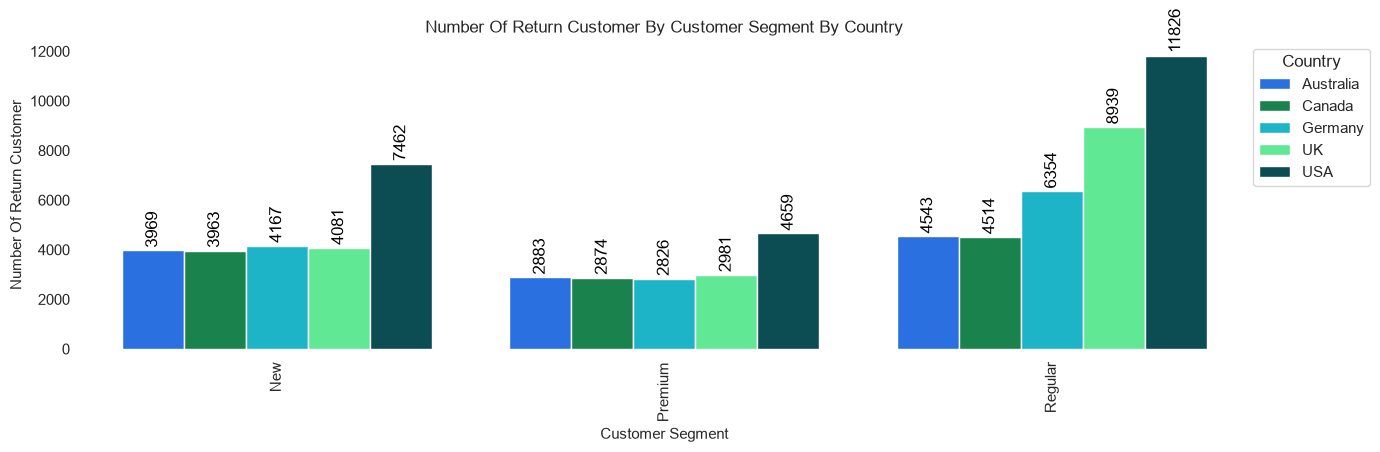

In [119]:
sns.set_theme(font_scale=1)
sns.set_style('white')
fig, ax = plt.subplots(figsize = (15, 4))
sns.barplot(data=number_of_return_customer, y = 'NumberOfReturnCustomer' , x='Customer_Segment', hue='Country', ax=ax, palette = sns.color_palette(cc.glasbey_cool, n_colors=5), width=0.8)
ax.set_xlabel('Customer Segment', fontsize=11)
ax.set_ylabel("Number Of Return Customer", fontsize=11)
for i in ax.containers:
    ax.bar_label(i,  padding=2, fmt='%.1d', color = 'black', rotation = 90, fontsize = 12)
ax.set_title('Number Of Return Customer By Customer Segment By Country', fontsize = 12)
ax.tick_params(axis='x', labelrotation = 90)
plt.ticklabel_format(style='plain', axis='y')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine(bottom = True, left = True)